# Лабораторная работа №13: Fine-tuning diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Подготовить изображения/captions и fixed-seed baseline.
- Выполнить SD1.5 LoRA fine-tuning.
- Сравнить checkpoints, diversity и memorization.

## Теоретическая часть

Latent diffusion добавляет шум в latent space VAE, а U-Net предсказывает noise/velocity. LoRA адаптирует attention projections без изменения всех весов. Фиксированные seeds и prompts обязательны для сравнения checkpoints.

![Архитектура latent diffusion](https://raw.githubusercontent.com/CompVis/latent-diffusion/main/assets/modelfigure.png)


Latent diffusion обучает UNet предсказывать ε в пространстве VAE. LoRA добавляет обучаемые низкоранговые поправки к attention projections; VAE, text encoder и base UNet остаются замороженными. CLIP text similarity, разнообразие и ближайшая train генерация измеряют разные свойства и требуют ручного дополнения.

Для LoRA $W^{\prime}=W+BA$, где $B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r\ll\min(d,k)$. Noise-prediction минимизирует $\mathbb{E}_{x_0,\epsilon,t}\|\epsilon-\epsilon_\theta(z_t,t,c)\|_2^2$ на VAE-latents.

## Теоретическая часть

**Диффузионные модели (Diffusion Models)** — это класс генеративных нейронных сетей, предназначенных для создания изображений путём постепенного преобразования случайного шума в осмысленное изображение. В процессе прямого распространения к исходному изображению постепенно добавляется гауссовский шум, а при обратном процессе нейронная сеть учится удалять этот шум и восстанавливать изображение.

В данной работе используется модель **Stable Diffusion 1.5**, основанная на архитектуре Latent Diffusion. В отличие от обычных диффузионных моделей, она выполняет основные вычисления не непосредственно с изображениями, а в скрытом пространстве (latent space). Для преобразования изображений в скрытое представление и обратно используется вариационный автокодировщик (VAE). Это позволяет значительно снизить вычислительные затраты.

Основным компонентом модели является **U-Net**, которая предсказывает шум, добавленный к скрытому представлению изображения. Обучение модели происходит путём минимизации ошибки между реальным шумом и предсказанным сетью значением.

Для адаптации предварительно обученной модели к новой предметной области применяется метод **LoRA (Low-Rank Adaptation)**. Его идея заключается в том, что вместо изменения всех параметров нейронной сети обучаются небольшие низкоранговые матрицы, которые добавляются к существующим весам модели:

\[
W' = W + BA
\]

где \(W\) — исходные веса модели, а \(A\) и \(B\) — обучаемые матрицы меньшего ранга. Такой подход позволяет существенно сократить количество обучаемых параметров, время обучения и требования к видеопамяти.

В лабораторной работе LoRA используется для дообучения Stable Diffusion 1.5 на наборе фотографий бабочек. При этом основные веса модели, включая VAE и текстовый энкодер, остаются замороженными, а адаптация выполняется через дополнительные обучаемые параметры.

Для оценки качества дообучения используются несколько подходов:
- **Baseline** — генерация изображений исходной моделью до обучения, необходимая для сравнения результатов.
- **CLIP similarity** — оценка соответствия сгенерированного изображения текстовому описанию.
- **Diversity** — оценка разнообразия изображений, полученных при разных случайных начальных значениях (seeds).
- **Memorization** — проверка того, насколько сильно модель воспроизводит изображения из обучающей выборки вместо создания новых вариантов.

### Экспериментальный протокол

Основной эксперимент: SD 1.5 и 28 открытых реальных фотографий бабочек Wikimedia Commons при 512 px. `download_open_data.py` скачивает файлы и для каждого проверяет метаданные CC0-1.0 через Commons API, фиксирует страницу источника, URL лицензии и SHA256. Никакие файлы студента не требуются; `CV_LORA_DATA` задаёт альтернативный каталог с той же структурой metadata.jsonl. 3 независимых адаптера по 400 optimizer updates, checkpoint на 200/400; фиксированные held-out prompts и seeds. FAST_DEV_RUN: 256 px, один update, только smoke. Требуются GPU, Pillow, pip install diffusers transformers accelerate peft safetensors torchvision; на CPU не подменять обучение имитацией. CV_ARTIFACTS указывает на постоянный каталог Drive.

### Материалы

- [Diffusers LoRA training](https://huggingface.co/docs/diffusers/training/lora)
- [Latent Diffusion](https://arxiv.org/abs/2112.10752)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
PROJECT_DIR = Path('/content/drive/MyDrive/lab13')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 64
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', PROJECT_DIR / 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', PROJECT_DIR / 'data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/drive/MyDrive/lab13/artifacts'}


In [1]:
!pip index versions torchao 2>/dev/null || pip index versions torchao
!pip show torchao
!pip install --upgrade --force-reinstall "torchao>=0.16.0" -v 2>&1 | tail -40

torchao (0.18.0)
Available versions: 0.18.0, 0.17.0, 0.16.0, 0.15.0, 0.14.1, 0.14.0, 0.13.0, 0.12.0, 0.11.0, 0.10.0, 0.9.0, 0.8.0, 0.7.0, 0.1, 0.0.3, 0.0.1
  INSTALLED: 0.10.0
  LATEST:    0.18.0
Name: torchao
Version: 0.10.0
Summary: Package for applying ao techniques to GPU models
Home-page: https://github.com/pytorch/ao
Author: 
Author-email: 
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: 
Required-by: 
Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
  Obtaining dependency information for torchao>=0.16.0 from https://files.pythonhosted.org/packages/19/55/ed9ad98f0f09d5a1124d09830043d13a39e63539f9590d2bdb6d71cbc4a4/torchao-0.18.0-cp310-abi3-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 14.9 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Removing file or directory /usr/local/lib/p

In [3]:
# Библиотеки

import hashlib
from collections import Counter
from PIL import Image
import sys, subprocess
import re
import math
import matplotlib.pyplot as plt

from diffusers import StableDiffusionPipeline, DDPMScheduler
from peft import LoraConfig, get_peft_model, PeftModel
import copy

import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import gc

import shutil
from diffusers.optimization import get_scheduler
import diffusers
import transformers
import peft

Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`


### Лицензия и валидация изображений

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей.

**Результат.** Проверяемое состояние «Лицензия и валидация изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей» и его результат доступен следующему этапу.

In [4]:
REQUIRED_LICENSE = 'CC0-1.0'
META_PATH = DATA_ROOT / 'metadata.jsonl'

# --- 1. download_open_data.py, если metadata ещё нет ---
if not META_PATH.exists():
    script = next((p for p in [
        PROJECT_DIR / 'download_open_data.py',
        Path.cwd() / 'download_open_data.py',
        Path('/content/download_open_data.py'),
    ] if p.exists()), None)
    if script is None:
        raise FileNotFoundError('download_open_data.py не найден в PROJECT_DIR, cwd или /content')

    env = os.environ.copy()
    env['CV_LORA_DATA'] = str(DATA_ROOT)
    env['CV_ARTIFACTS'] = str(ARTIFACTS)
    base = [sys.executable, str(script)]
    help_out = subprocess.run(base + ['--help'], env=env, text=True,
                              capture_output=True, cwd=str(script.parent))
    flags = (help_out.stdout + help_out.stderr)
    cmd = base + (['--data-root', str(DATA_ROOT)] if '--data-root' in flags
                  else ['--out', str(DATA_ROOT)] if '--out' in flags else [])
    proc = subprocess.run(cmd, env=env, text=True, capture_output=True, cwd=str(script.parent))
    print((proc.stdout or '')[-2000:]); print((proc.stderr or '')[-2000:])
    if proc.returncode != 0:
        raise RuntimeError(f'download_open_data.py упал с кодом {proc.returncode}')

# --- 2. читаем metadata ---
records = [json.loads(l) for l in META_PATH.read_text(encoding='utf-8').splitlines() if l.strip()]
print(f'metadata.jsonl: {len(records)} записей')

def field(rec, *names):
    return next((rec[n] for n in names if rec.get(n) is not None), None)

# --- 3. проверки ---
per_image, errors = [], []
for i, rec in enumerate(records):
    name    = field(rec, 'file_name', 'image', 'path', 'filename')
    caption = field(rec, 'text', 'caption', 'prompt')
    license_= field(rec, 'license', 'license_id')
    lic_url = field(rec, 'license_url', 'licenseUrl', 'rights_url')
    src     = field(rec, 'source_url', 'source_page', 'source', 'page_url', 'page',
                    'descriptionurl', 'descriptionshorturl', 'commons_page', 'html_url')
    src_title = field(rec, 'source_title')
    author  = field(rec, 'author_as_reported')
    sha_exp = field(rec, 'sha256')

    row = dict(index=i, file_name=name, caption=caption, license=license_,
               license_url=lic_url, source_page=src, source_title=src_title,
               author=author, sha256_expected=sha_exp)

    if not name:
        errors.append({'index': i, 'error': 'missing file_name'}); per_image.append(row); continue

    path = DATA_ROOT / name
    row['file_path'] = str(path)
    row['file_exists'] = path.exists()
    if not path.exists():
        errors.append({'index': i, 'error': f'file not found: {path}'}); per_image.append(row); continue

    h = hashlib.sha256(path.read_bytes()).hexdigest()
    row['sha256_actual'] = h
    row['sha256_matches'] = sha_exp is None or h == sha_exp
    if not row['sha256_matches']:
        errors.append({'index': i, 'error': 'sha256 mismatch'})

    try:
        with Image.open(path) as im:
            im.load()
            row['pil_mode'], row['pil_size'] = im.mode, list(im.size)
            arr = np.asarray(im.convert('RGB'))
        row['rgb_ok'] = arr.ndim == 3 and arr.shape[2] == 3 and arr.dtype == np.uint8
        row['rgb_shape'] = list(arr.shape)
        if not row['rgb_ok']:
            errors.append({'index': i, 'error': 'RGB decode failed'})
    except Exception as e:
        row['rgb_ok'] = False
        errors.append({'index': i, 'error': f'decode failed: {e!r}'})

    if license_ != REQUIRED_LICENSE:
        errors.append({'index': i, 'error': f'license {license_!r} != {REQUIRED_LICENSE}'})
    if not lic_url:
        errors.append({'index': i, 'error': 'missing license_url'})
    if not src:
        errors.append({'index': i, 'error': 'missing source_page'})
    per_image.append(row)

# --- 4. уникальность ---
def dups(key):
    c = Counter(r.get(key) for r in per_image if r.get(key))
    return {k: n for k, n in c.items() if n > 1}

dups_sha, dups_name, dups_cap = dups('sha256_actual'), dups('file_name'), dups('caption')
for d, label in [(dups_sha, 'sha256'), (dups_name, 'file_name'), (dups_cap, 'caption')]:
    if d:
        errors.append({'error': f'duplicate {label}', 'count': len(d)})

# --- 5. сводка ---
n = len(per_image)
report = {
    'required_license': REQUIRED_LICENSE,
    'n_records': n,
    'n_files_exist':      sum(r.get('file_exists', False) for r in per_image),
    'n_sha256_matches':   sum(r.get('sha256_matches', False) for r in per_image),
    'n_rgb_ok':           sum(r.get('rgb_ok', False) for r in per_image),
    'n_license_ok':       sum(r.get('license') == REQUIRED_LICENSE for r in per_image),
    'n_license_url_present': sum(bool(r.get('license_url')) for r in per_image),
    'n_source_page_present': sum(bool(r.get('source_page')) for r in per_image),
    'license_counts': dict(Counter(r.get('license') for r in per_image if r.get('license'))),
    'duplicates_by_sha256': dups_sha,
    'duplicates_by_file_name': dups_name,
    'duplicates_by_caption': dups_cap,
    'errors': errors,
}
report['all_ok'] = (
    n > 0 and all(report[k] == n for k in [
        'n_files_exist', 'n_sha256_matches', 'n_rgb_ok',
        'n_license_ok', 'n_license_url_present', 'n_source_page_present'])
    and not (dups_sha or dups_name or dups_cap)
)

valid = [{'file_name': r['file_name'], 'file_path': r['file_path'], 'caption': r['caption'],
          'license': r['license'], 'license_url': r['license_url'], 'source_page': r['source_page'],
          'source_title': r.get('source_title'), 'author': r.get('author'),
          'sha256': r['sha256_actual'], 'size': r.get('pil_size')}
         for r in per_image if r.get('rgb_ok') and r.get('sha256_matches') and r.get('file_exists')]

(ARTIFACTS / 'task1_validation_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2))
(ARTIFACTS / 'task1_per_image.json').write_text(json.dumps(per_image, ensure_ascii=False, indent=2))
(ARTIFACTS / 'task1_valid_images.json').write_text(json.dumps(valid, ensure_ascii=False, indent=2))

# --- 6. вывод измеренных значений ---
print(f'records:            {n}')
print(f'files exist:        {report["n_files_exist"]}/{n}')
print(f'sha256 matches:     {report["n_sha256_matches"]}/{n}')
print(f'RGB decode ok:      {report["n_rgb_ok"]}/{n}')
print(f'license == CC0-1.0: {report["n_license_ok"]}/{n}')
print(f'license_url:        {report["n_license_url_present"]}/{n}')
print(f'source_page:        {report["n_source_page_present"]}/{n}')
print(f'license_counts:     {report["license_counts"]}')
print(f'dups sha/name/cap:  {len(dups_sha)}/{len(dups_name)}/{len(dups_cap)}')
print(f'errors:             {len(errors)}')
print(f'ALL_OK:             {report["all_ok"]}')
print(f'artifacts:          {ARTIFACTS}/task1_*.json')

assert report['all_ok'], f'Валидация не пройдена, первые ошибки: {errors[:5]}'

sam.jpg (124914 bytes)
4/28 commons_03.jpg: A butterfly on a purple flower.jpg (106346 bytes)
5/28 commons_04.jpg: Black and white butterfly near Shirahama.jpg (262645 bytes)
6/28 commons_05.jpg: Butterfly 51.jpg (90759 bytes)
7/28 commons_06.jpg: Butterfly Iguazu Falls.jpg (297914 bytes)
8/28 commons_07.jpg: Butterfly The Insect.jpg (354628 bytes)
9/28 commons_08.jpg: Butterfly at Jonanjima.jpg (93098 bytes)
10/28 commons_09.jpg: Butterfly at Wingham Wildlife Park Kent UK.jpg (84272 bytes)
11/28 commons_10.jpg: Butterfly by the water.jpg (152912 bytes)
12/28 commons_11.jpg: Butterfly enjoying with nature.jpg (101671 bytes)
13/28 commons_12.jpg: Butterfly from butterfly garden-lucknow zoo.jpg (497712 bytes)
14/28 commons_13.jpg: Butterfly hanging on leaf.jpg (163975 bytes)
15/28 commons_14.jpg: Butterfly in Armenia.jpg (363511 bytes)
16/28 commons_15.jpg: Butterfly orange.jpg (274701 bytes)
17/28 commons_16.jpg: Common Jezebel Delias eucharis by kadavoor 3.jpg (123211 bytes)
18/28 comm

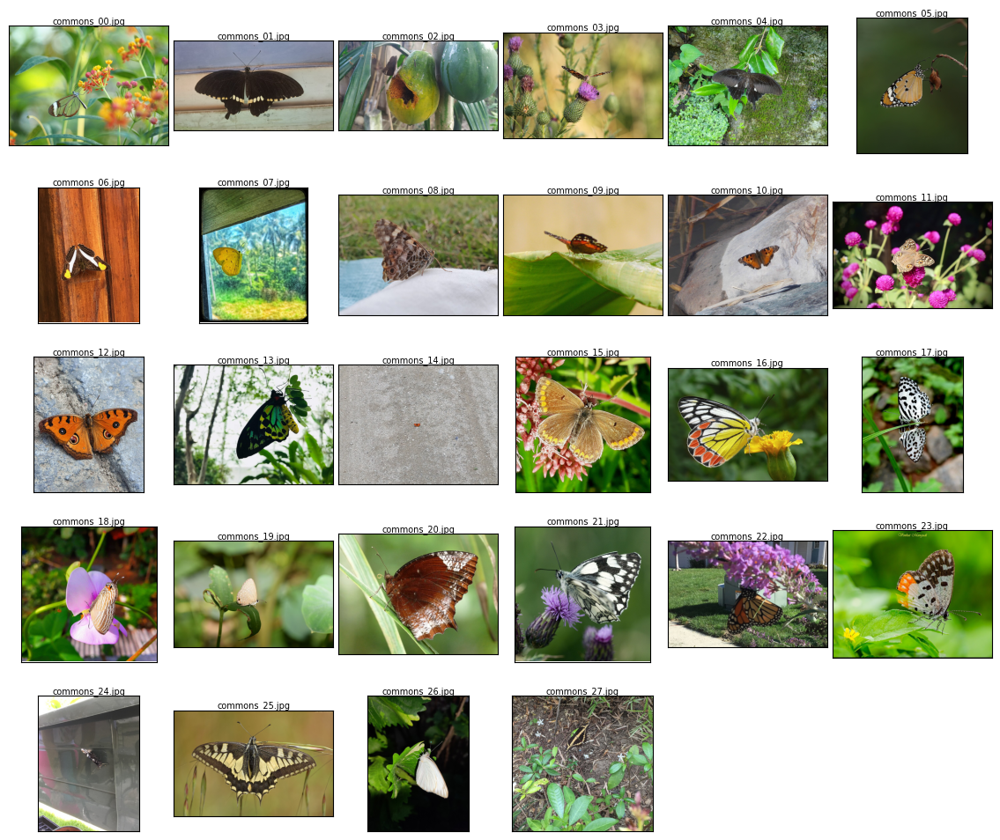

28 изображений, сетка 5×6


In [5]:
valid_path = ARTIFACTS / 'task1_valid_images.json'
valid = json.loads(valid_path.read_text(encoding='utf-8'))

N = len(valid)
NCOLS = 6
NROWS = math.ceil(N / NCOLS)

fig, axes = plt.subplots(NROWS, NCOLS, figsize=(NCOLS * 2.4, NROWS * 2.4))
axes = axes.flatten()

for ax, item in zip(axes, valid):
    with Image.open(item['file_path']) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{item['file_name']}", fontsize=7, pad=2)

# выключаем пустые ячейки
for ax in axes[N:]:
    ax.axis('off')

plt.subplots_adjust(wspace=0.03, hspace=0.25)
plt.show()

print(f'{N} изображений, сетка {NROWS}×{NCOLS}')

### Отложенные текстовые запросы

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями.

**Результат.** Проверяемое состояние «Отложенные текстовые запросы» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями» и его результат доступен следующему этапу.

In [6]:
# --- 1. читаем train captions из артефакта задания 1 ---
valid_path = ARTIFACTS / 'task1_valid_images.json'
valid = json.loads(valid_path.read_text(encoding='utf-8'))
train_captions = [v['caption'] for v in valid if v.get('caption')]
print(f'train captions: {len(train_captions)}')

# --- 2. нормализация для сравнения "на точное совпадение" ---
def norm(s: str) -> str:
    s = s.lower().strip()
    s = re.sub(r'\s+', ' ', s)
    s = re.sub(r'[^\w\s]', '', s)
    return s

train_norm = {norm(c) for c in train_captions}

# --- 3. held-out prompts ---
# Правила:
#  - не совпадают точно ни с одним train caption (после нормализации);
#  - НЕ содержат триггер-токен 'sks' (он в train captions, в held-out его быть не должно);
#  - покрывают разные аспекты: вид, цвет, поза, фон, стиль.
TRIGGER = 'sks'

HELD_OUT_PROMPTS = [
    'a butterfly on a white daisy, macro photography',
    'a monarch butterfly with orange wings resting on a leaf',
    'a blue morpho butterfly in a tropical forest',
    'a yellow butterfly flying over green grass',
    'a butterfly on a purple lavender flower, shallow depth of field',
    'a close-up of a butterfly wing pattern',
    'a butterfly on a human hand in a garden',
    'a white butterfly on a red flower, natural light',
    'a butterfly resting on a stone near water',
    'a black and orange butterfly on a sunflower',
    'a small butterfly on a dandelion in spring',
    'a butterfly with spread wings on a wooden surface',
]

# --- 4. seeds ---
HELD_OUT_SEEDS = [0, 1, 2, 3, 4]

# --- 5. проверки ---
problems = []
exact_collisions = [p for p in HELD_OUT_PROMPTS if norm(p) in train_norm]
trigger_hits = [p for p in HELD_OUT_PROMPTS if TRIGGER in norm(p).split()]
dup_prompts = {p: n for p, n in Counter(norm(p) for p in HELD_OUT_PROMPTS).items() if n > 1}
dup_seeds = {s: n for s, n in Counter(HELD_OUT_SEEDS).items() if n > 1}
def tokens(s): return set(norm(s).split())
too_similar = []
for p in HELD_OUT_PROMPTS:
    tp = tokens(p)
    for c in train_captions:
        tc = tokens(c)
        if tp and tc and len(tp & tc) / len(tp | tc) >= 0.9:
            too_similar.append({'prompt': p, 'train': c,
                                'jaccard': round(len(tp & tc) / len(tp | tc), 3)})

if exact_collisions: problems.append({'error': 'exact collision with train caption',
                                      'prompts': exact_collisions})
if trigger_hits:     problems.append({'error': f'trigger token "{TRIGGER}" in held-out',
                                      'prompts': trigger_hits})
if dup_prompts:      problems.append({'error': 'duplicate held-out prompts',
                                      'prompts': list(dup_prompts)})
if dup_seeds:        problems.append({'error': 'duplicate seeds', 'seeds': list(dup_seeds)})
if too_similar:      problems.append({'error': 'prompt too similar to train (jaccard>=0.9)',
                                      'pairs': too_similar})

# --- 6. сводка ---
report = {
    'seed': SEED,
    'trigger_token': TRIGGER,
    'n_train_captions': len(train_captions),
    'n_held_out_prompts': len(HELD_OUT_PROMPTS),
    'n_seeds': len(HELD_OUT_SEEDS),
    'n_pairs': len(HELD_OUT_PROMPTS) * len(HELD_OUT_SEEDS),
    'held_out_prompts': HELD_OUT_PROMPTS,
    'held_out_seeds': HELD_OUT_SEEDS,
    'exact_collisions_with_train': exact_collisions,
    'trigger_hits': trigger_hits,
    'duplicate_prompts': dup_prompts,
    'duplicate_seeds': dup_seeds,
    'too_similar_to_train': too_similar,
    'errors': problems,
}
report['all_ok'] = (
    len(HELD_OUT_PROMPTS) > 0 and len(HELD_OUT_SEEDS) > 0
    and not exact_collisions and not trigger_hits
    and not dup_prompts and not dup_seeds and not too_similar
)

# --- 7. сохраняем для следующего этапа ---
(ARTIFACTS / 'task2_held_out_prompts.json').write_text(
    json.dumps({'seed': SEED,
                'trigger_token': TRIGGER,
                'prompts': HELD_OUT_PROMPTS,
                'seeds': HELD_OUT_SEEDS,
                'pairs': [{'prompt': p, 'seed': s}
                          for p in HELD_OUT_PROMPTS for s in HELD_OUT_SEEDS]},
               ensure_ascii=False, indent=2))
(ARTIFACTS / 'task2_validation_report.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2))

# --- 8. печатаем измеренные значения ---
print(f'train captions:             {len(train_captions)}')
print(f'held-out prompts:           {len(HELD_OUT_PROMPTS)}')
print(f'seeds:                      {len(HELD_OUT_SEEDS)}  {HELD_OUT_SEEDS}')
print(f'generation pairs:           {len(HELD_OUT_PROMPTS) * len(HELD_OUT_SEEDS)}')
print(f'exact collisions w/ train:  {len(exact_collisions)}')
print(f'trigger "{TRIGGER}" hits:        {len(trigger_hits)}')
print(f'duplicate prompts/seeds:    {len(dup_prompts)}/{len(dup_seeds)}')
print(f'too similar (jaccard>=0.9): {len(too_similar)}')
print(f'errors:                     {len(problems)}')
print(f'ALL_OK:                     {report["all_ok"]}')
print(f'artifacts:                  {ARTIFACTS}/task2_*.json')

assert report['all_ok'], f'Проверка held-out не пройдена: {problems[:3]}'

train captions: 28
train captions:             28
held-out prompts:           12
seeds:                      5  [0, 1, 2, 3, 4]
generation pairs:           60
exact collisions w/ train:  0
trigger "sks" hits:        0
duplicate prompts/seeds:    0/0
too similar (jaccard>=0.9): 0
errors:                     0
ALL_OK:                     True
artifacts:                  /content/drive/MyDrive/lab13/artifacts/task2_*.json


### Baseline SD на фиксированных запросах

*Вес: 1 балл.*

**Постановка.** Baseline до обучения и сопоставимый inference protocol позволяют увидеть фактический вклад LoRA. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds.

**Результат.** Проверяемое состояние «Baseline SD на фиксированных запросах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds» и его результат доступен следующему этапу.

In [7]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE != 'cuda':
    raise RuntimeError('Baseline требует GPU. Runtime → Change runtime type → T4 GPU.')
BASELINE_DIR = ARTIFACTS / 'baseline_sd15'
BASELINE_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. читаем held-out prompts/seeds из задания 2 ---
held_path = ARTIFACTS / 'task2_held_out_prompts.json'
if not held_path.exists():
    raise FileNotFoundError(f'Нет {held_path}. Сначала выполните задание 2.')
held = json.loads(held_path.read_text(encoding='utf-8'))
prompts, seeds = held['prompts'], held['seeds']
print(f'prompts: {len(prompts)}, seeds: {len(seeds)}, pairs: {len(prompts) * len(seeds)}')

# В smoke-режиме генерируем только 2 пары, чтобы не ждать
if FAST_DEV_RUN:
    pairs = [{'prompt': prompts[0], 'seed': seeds[0]},
             {'prompt': prompts[1], 'seed': seeds[0]}]
    print(f'FAST_DEV_RUN=True: только {len(pairs)} пары для smoke')
else:
    pairs = held['pairs']

# --- 2. inference protocol (фиксируем всё, что влияет на результат) ---
GEN_KWARGS = dict(
    num_inference_steps=30,
    guidance_scale=7.5,
    height=512, width=512,
)
print('inference protocol:', GEN_KWARGS)

# --- 3. загружаем исходную SD 1.5 (без LoRA) ---
t0 = time.time()
pipe = StableDiffusionPipeline.from_pretrained(
    'runwayml/stable-diffusion-v1-5',
    torch_dtype=torch.float16,
    safety_checker=None,          # отключаем, чтобы не было ложных срабатываний
    requires_safety_checker=False,
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print(f'SD 1.5 загружена за {time.time() - t0:.1f} c, device={pipe.device}')

# фиксируем seed глобально (влияет на dropout/инициализацию — для воспроизводимости)
torch.manual_seed(SEED)

# --- 4. генерируем baseline ---
results = []
t_start = time.time()
for i, pair in enumerate(pairs, 1):
    prompt, seed = pair['prompt'], pair['seed']
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    t0 = time.time()
    image = pipe(prompt, generator=gen, **GEN_KWARGS).images[0]
    dt = time.time() - t0

    fname = f'baseline_p{i:03d}_s{seed}.png'
    fpath = BASELINE_DIR / fname
    image.save(fpath)

    results.append({
        'index': i, 'prompt': prompt, 'seed': seed,
        'file_name': fname, 'file_path': str(fpath),
        'gen_time_sec': round(dt, 2),
        'num_inference_steps': GEN_KWARGS['num_inference_steps'],
        'guidance_scale': GEN_KWARGS['guidance_scale'],
        'size': list(image.size),
    })
    print(f'[{i}/{len(pairs)}] seed={seed} {dt:.1f}s  {prompt[:60]}')

total = time.time() - t_start

# --- 5. сохраняем артефакты ---
meta = {
    'model': 'runwayml/stable-diffusion-v1-5',
    'adapter': None,
    'device': str(pipe.device),
    'torch_dtype': 'float16',
    'inference_protocol': GEN_KWARGS,
    'global_seed': SEED,
    'n_generated': len(results),
    'total_time_sec': round(total, 1),
    'results': results,
}
(ARTIFACTS / 'task3_baseline.json').write_text(
    json.dumps(meta, ensure_ascii=False, indent=2))

# --- 6. измеренные значения ---
print('\n--- Фактически измеренные значения ---')
print(f'device:                 {pipe.device}')
print(f'model:                  {meta["model"]}')
print(f'generated images:       {len(results)}')
print(f'saved to:               {BASELINE_DIR}')
print(f'total time:             {total:.1f} c')
if results:
    times = [r['gen_time_sec'] for r in results]
    print(f'per-image time:         min={min(times):.1f}s  '
          f'mean={sum(times)/len(times):.1f}s  max={max(times):.1f}s')
    print(f'first image:            {results[0]["file_name"]}  size={results[0]["size"]}')
print(f'artifacts:              {ARTIFACTS}/task3_baseline.json')

assert len(results) == len(pairs), 'сгенерировано не всё'
print('\nOK: baseline доступен следующему этапу (task3_baseline.json).')

prompts: 12, seeds: 5, pairs: 60
inference protocol: {'num_inference_steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512}


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

SD 1.5 загружена за 63.7 c, device=cuda:0
[1/60] seed=0 8.9s  a butterfly on a white daisy, macro photography
[2/60] seed=1 4.5s  a butterfly on a white daisy, macro photography
[3/60] seed=2 4.6s  a butterfly on a white daisy, macro photography
[4/60] seed=3 4.6s  a butterfly on a white daisy, macro photography
[5/60] seed=4 4.6s  a butterfly on a white daisy, macro photography
[6/60] seed=0 4.7s  a monarch butterfly with orange wings resting on a leaf
[7/60] seed=1 4.8s  a monarch butterfly with orange wings resting on a leaf
[8/60] seed=2 4.8s  a monarch butterfly with orange wings resting on a leaf
[9/60] seed=3 4.8s  a monarch butterfly with orange wings resting on a leaf
[10/60] seed=4 4.9s  a monarch butterfly with orange wings resting on a leaf
[11/60] seed=0 5.0s  a blue morpho butterfly in a tropical forest
[12/60] seed=1 5.0s  a blue morpho butterfly in a tropical forest
[13/60] seed=2 5.3s  a blue morpho butterfly in a tropical forest
[14/60] seed=3 5.4s  a blue morpho butt

### Подготовка пар изображение–caption

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон.

**Результат.** Проверяемое состояние «Подготовка пар изображение–caption» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон» и его результат доступен следующему этапу.

seed=0, картинок: 12, доступные seeds: [0, 1, 2, 3, 4]


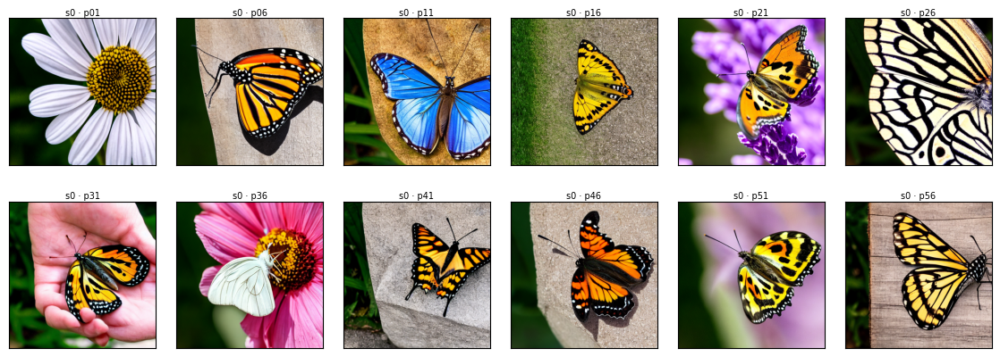

baseline, seed=0: 12 изображений, сетка 2×6


In [8]:
base_path = ARTIFACTS / 'task3_baseline.json'
base = json.loads(base_path.read_text(encoding='utf-8'))
results = base['results']

# --- выбираем один seed и все картинки с ним ---
seeds_available = sorted({r['seed'] for r in results})
SEED_TO_SHOW = seeds_available[0]
subset = [r for r in results if r['seed'] == SEED_TO_SHOW]
subset.sort(key=lambda r: r['index'])
print(f'seed={SEED_TO_SHOW}, картинок: {len(subset)}, доступные seeds: {seeds_available}')

# --- сетка 6×N, как в задании 1 ---
N = len(subset)
NCOLS = 6
NROWS = math.ceil(N / NCOLS)

fig, axes = plt.subplots(NROWS, NCOLS, figsize=(NCOLS * 2.4, NROWS * 2.4))
axes = axes.flatten()

for ax, item in zip(axes, subset):
    with Image.open(item['file_path']) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"s{item['seed']} · p{item['index']:02d}", fontsize=7, pad=2)

for ax in axes[N:]:
    ax.axis('off')

plt.subplots_adjust(wspace=0.03, hspace=0.25)
plt.show()

print(f'baseline, seed={SEED_TO_SHOW}: {N} изображений, сетка {NROWS}×{NCOLS}')

### Заморозка основы и конфигурации LoRA

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR.

**Результат.** Проверяемое состояние «Заморозка основы и конфигурации LoRA» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR» и его результат доступен следующему этапу.

In [9]:
if DEVICE != 'cuda':
    raise RuntimeError('LoRA требует GPU.')

# --- 1. три конфигурации rank/LR ---
LORA_CONFIGS = [
    {'name': 'r4_lr1e-4',  'rank': 4,  'lr': 1e-4},
    {'name': 'r8_lr1e-4',  'rank': 8,  'lr': 1e-4},
    {'name': 'r8_lr5e-5',  'rank': 8,  'lr': 5e-5},
]

# --- 2. тренировочный schedule ---
SCHEDULE = {
    'max_train_steps': 400,
    'checkpoint_steps': [200, 400],
    'batch_size': 1,
    'gradient_accumulation_steps': 1,
    'optimizer': 'adamw',
    'adam_beta1': 0.9, 'adam_beta2': 0.999,
    'adam_weight_decay': 1e-2, 'adam_epsilon': 1e-8,
    'lr_scheduler': 'constant',
    'lr_warmup_steps': 0,
    'max_grad_norm': 1.0,
    'mixed_precision': 'fp16',
    'resolution': 256 if FAST_DEV_RUN else 512,
    'seed': SEED,
}
if FAST_DEV_RUN:
    SCHEDULE['max_train_steps'] = 1
    SCHEDULE['checkpoint_steps'] = [1]
print('schedule:', json.dumps(SCHEDULE, indent=2))

# --- 3. загружаем SD 1.5 и замораживаем основу ---
pipe = StableDiffusionPipeline.from_pretrained(
    'runwayml/stable-diffusion-v1-5',
    torch_dtype=torch.float16,
    safety_checker=None, requires_safety_checker=False,
).to(DEVICE)

# Замораживаем всё: VAE, text encoder, UNet
pipe.vae.requires_grad_(False)
pipe.text_encoder.requires_grad_(False)
pipe.unet.requires_grad_(False)

def count_params(module):
    total = sum(p.numel() for p in module.parameters())
    train = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, train

vae_total, vae_train = count_params(pipe.vae)
te_total,  te_train  = count_params(pipe.text_encoder)
un_total,  un_train  = count_params(pipe.unet)

# --- 4. LoRA для каждой конфигурации на СВЕЖЕЙ копии UNet ---
def build_lora(unet, rank):
    return get_peft_model(unet, LoraConfig(
        r=rank, lora_alpha=rank,            # alpha=r — стандарт diffusers
        target_modules=['to_q', 'to_k', 'to_v', 'to_out.0'],
        lora_dropout=0.0, bias='none',
        init_lora_weights='gaussian',       # A~N(0,1/r), B=0 → BA=0 в начале
    ))

lora_info = []
for cfg in LORA_CONFIGS:
    # ВАЖНО: каждый раз — чистая копия base UNet.
    # pipe.unet обёртывать нельзя: вторая конфигурация наложилась бы на первую.
    unet_copy = copy.deepcopy(pipe.unet)
    unet_copy.requires_grad_(False)

    peft_unet = build_lora(unet_copy, cfg['rank'])
    total, train = count_params(peft_unet)
    lora_trainable = [n for n, p in peft_unet.named_parameters() if p.requires_grad]
    base_tensors   = [n for n, p in peft_unet.named_parameters() if not p.requires_grad]
    non_lora_trainable = [n for n in lora_trainable if 'lora' not in n.lower()]

    lora_info.append({
        'config': cfg,
        'unet_total_params': total,
        'unet_trainable_params': train,
        'lora_trainable_fraction': round(train / total, 6),
        'n_lora_tensors': len(lora_trainable),
        'n_frozen_tensors': len(base_tensors),
        'non_lora_trainable': non_lora_trainable[:5],
        'target_modules': ['to_q', 'to_k', 'to_v', 'to_out.0'],
        'lora_alpha': cfg['rank'],
        'lora_dropout': 0.0,
        'init': 'gaussian (A~N(0,1/r), B=0)',
    })

    # освобождаем память до следующей конфигурации
    del peft_unet, unet_copy
    torch.cuda.empty_cache()

# --- 5. проверки ---
errors = []
if vae_train != 0:  errors.append('VAE has trainable params')
if te_train != 0:   errors.append('text encoder has trainable params')
if un_train != 0:   errors.append('base UNet has trainable params before LoRA')

for info in lora_info:
    if info['unet_trainable_params'] == 0:
        errors.append(f"{info['config']['name']}: no trainable params")
    if info['non_lora_trainable']:
        errors.append(f"{info['config']['name']}: non-LoRA trainable: {info['non_lora_trainable']}")

if len(LORA_CONFIGS) != 3:
    errors.append(f'expected 3 configs, got {len(LORA_CONFIGS)}')
ranks = {c['rank'] for c in LORA_CONFIGS}
lrs   = {c['lr']   for c in LORA_CONFIGS}
if len(ranks) < 2 and len(lrs) < 2:
    errors.append('configs do not differ in rank or lr')

if SCHEDULE['checkpoint_steps'][-1] != SCHEDULE['max_train_steps']:
    errors.append('last checkpoint step != max_train_steps')
if not all(0 < s <= SCHEDULE['max_train_steps'] for s in SCHEDULE['checkpoint_steps']):
    errors.append('checkpoint_steps out of range')

# r8 должен давать ровно вдвое больше trainable, чем r4 (sanity check)
by_name = {info['config']['name']: info for info in lora_info}
if 'r4_lr1e-4' in by_name and 'r8_lr1e-4' in by_name:
    ratio = by_name['r8_lr1e-4']['unet_trainable_params'] / max(1, by_name['r4_lr1e-4']['unet_trainable_params'])
    if not (1.9 <= ratio <= 2.1):
        errors.append(f'r8/r4 trainable ratio = {ratio:.2f}, expected ~2.0')

# --- 6. артефакты ---
report = {
    'base_model': 'runwayml/stable-diffusion-v1-5',
    'device': str(DEVICE),
    'torch_dtype': 'float16',
    'freeze': {
        'vae':          {'total': vae_total, 'trainable': vae_train},
        'text_encoder': {'total': te_total,  'trainable': te_train},
        'base_unet':    {'total': un_total,  'trainable': un_train},
    },
    'schedule': SCHEDULE,
    'lora_configs': LORA_CONFIGS,
    'lora_details': lora_info,
    'errors': errors,
}
report['all_ok'] = len(errors) == 0

(ARTIFACTS / 'task4_lora_configs.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2))

(ARTIFACTS / 'task4_training_plan.json').write_text(json.dumps({
    'schedule': SCHEDULE,
    'configs': LORA_CONFIGS,
    'base_model': report['base_model'],
    'target_modules': ['to_q', 'to_k', 'to_v', 'to_out.0'],
}, ensure_ascii=False, indent=2))

# --- 7. вывод ---
print('\n--- Заморозка ---')
print(f'VAE          total={vae_total:,}  trainable={vae_train:,}')
print(f'text encoder total={te_total:,}  trainable={te_train:,}')
print(f'base UNet    total={un_total:,}  trainable={un_train:,}')

print('\n--- LoRA конфигурации ---')
for info in lora_info:
    c = info['config']
    print(f"{c['name']:12s} rank={c['rank']:2d} lr={c['lr']:.1e}  "
          f"trainable={info['unet_trainable_params']:,} "
          f"({info['lora_trainable_fraction']*100:.3f}% of UNet)  "
          f"tensors={info['n_lora_tensors']}  "
          f"non-lora-trainable={len(info['non_lora_trainable'])}")

if 'r4_lr1e-4' in by_name and 'r8_lr1e-4' in by_name:
    r4 = by_name['r4_lr1e-4']['unet_trainable_params']
    r8 = by_name['r8_lr1e-4']['unet_trainable_params']
    print(f'\nr8/r4 trainable ratio: {r8 / max(1, r4):.3f}  (ожидаем ~2.0)')

print('\n--- Schedule ---')
print(f"max_train_steps={SCHEDULE['max_train_steps']}  "
      f"checkpoints={SCHEDULE['checkpoint_steps']}  "
      f"batch={SCHEDULE['batch_size']}  "
      f"resolution={SCHEDULE['resolution']}  "
      f"mixed_precision={SCHEDULE['mixed_precision']}")

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {report["all_ok"]}')
print(f'artifacts: {ARTIFACTS}/task4_lora_configs.json, task4_training_plan.json')

assert report['all_ok'], f'Проверка не пройдена: {errors}'
print('\nOK: план обучения доступен следующему этапу (task4_training_plan.json).')

schedule: {
  "max_train_steps": 400,
  "checkpoint_steps": [
    200,
    400
  ],
  "batch_size": 1,
  "gradient_accumulation_steps": 1,
  "optimizer": "adamw",
  "adam_beta1": 0.9,
  "adam_beta2": 0.999,
  "adam_weight_decay": 0.01,
  "adam_epsilon": 1e-08,
  "lr_scheduler": "constant",
  "lr_warmup_steps": 0,
  "max_grad_norm": 1.0,
  "mixed_precision": "fp16",
  "resolution": 512,
  "seed": 64
}


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


--- Заморозка ---
VAE          total=83,653,863  trainable=0
text encoder total=123,060,480  trainable=0
base UNet    total=859,520,964  trainable=0

--- LoRA конфигурации ---
r4_lr1e-4    rank= 4 lr=1.0e-04  trainable=797,184 (0.093% of UNet)  tensors=256  non-lora-trainable=0
r8_lr1e-4    rank= 8 lr=1.0e-04  trainable=1,594,368 (0.185% of UNet)  tensors=256  non-lora-trainable=0
r8_lr5e-5    rank= 8 lr=5.0e-05  trainable=1,594,368 (0.185% of UNet)  tensors=256  non-lora-trainable=0

r8/r4 trainable ratio: 2.000  (ожидаем ~2.0)

--- Schedule ---
max_train_steps=400  checkpoints=[200, 400]  batch=1  resolution=512  mixed_precision=fp16

errors:  0
ALL_OK:  True
artifacts: /content/drive/MyDrive/lab13/artifacts/task4_lora_configs.json, task4_training_plan.json

OK: план обучения доступен следующему этапу (task4_training_plan.json).


### Оптимизация адаптеров и checkpoint

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге.

**Результат.** Проверяемое состояние «Оптимизация адаптеров и checkpoint» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге» и его результат доступен следующему этапу.

In [10]:
# ---------- 1. Проверка окружения и предыдущих заданий ----------

assert torch.cuda.is_available(), (
    "Для настоящего обучения нужна GPU: "
    "Colab -> Среда выполнения -> Сменить тип среды -> T4 GPU."
)

DEVICE = "cuda"
assert "ARTIFACTS" in globals(), "Сначала выполните начальные ячейки лабораторной."

TASK_DIR = ARTIFACTS / "task5_adapter_optimization"
TASK_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = ARTIFACTS / "task1_valid_images.json"
PLAN_PATH = ARTIFACTS / "task4_training_plan.json"

assert DATA_PATH.exists(), f"Не найден файл {DATA_PATH}"
assert PLAN_PATH.exists(), f"Не найден файл {PLAN_PATH}"

valid = json.loads(DATA_PATH.read_text(encoding="utf-8"))
plan = json.loads(PLAN_PATH.read_text(encoding="utf-8"))

CONFIGS = plan["configs"]
SCHEDULE = plan["schedule"]

assert len(CONFIGS) == 3, "Ожидаются три конфигурации LoRA."
assert SCHEDULE["max_train_steps"] == 400, (
    "Для полного эксперимента требуется 400 optimizer updates."
)

if globals().get("FAST_DEV_RUN", False):
    raise RuntimeError(
        "FAST_DEV_RUN=True — это smoke test, а не полный эксперимент. "
        "Установите FAST_DEV_RUN=False и повторите предыдущие задания."
    )

RESOLUTION = int(SCHEDULE["resolution"])
MAX_STEPS = int(SCHEDULE["max_train_steps"])
CHECKPOINT_STEPS = list(SCHEDULE["checkpoint_steps"])
SEED = int(SCHEDULE["seed"])

BASE_MODEL = plan.get(
    "base_model", "runwayml/stable-diffusion-v1-5"
)

print("GPU:", torch.cuda.get_device_name(0))
print("Изображений:", len(valid))
print("Конфигурации:", CONFIGS)
print("Шаги:", MAX_STEPS, "| checkpoints:", CHECKPOINT_STEPS)

assert len(valid) > 0, "Список обучающих изображений пуст."
assert all(s in CHECKPOINT_STEPS for s in [200, 400])
assert MAX_STEPS == 400

# Проверяем доступность файлов и подписей.
for item in valid:
    assert Path(item["file_path"]).is_file(), item["file_path"]
    assert item.get("caption"), (
        f"Отсутствует caption: {item.get('file_name')}"
    )

# ---------- 2. Один и тот же Dataset для всех адаптеров ----------

image_transform = transforms.Compose([
    transforms.Resize(
        RESOLUTION,
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.CenterCrop(RESOLUTION),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

def load_training_example(index, tokenizer):
    item = valid[index]

    with Image.open(item["file_path"]) as image:
        pixel_values = image_transform(image.convert("RGB"))

    tokens = tokenizer(
        item["caption"],
        padding="max_length",
        truncation=True,
        max_length=tokenizer.model_max_length,
        return_tensors="pt",
    ).input_ids[0]

    return pixel_values, tokens

# Порядок изображений фиксирован и одинаков для всех конфигураций.
# Перемешивание воспроизводимо; на каждом шаге используется
# тот же индекс независимо от rank и learning rate.
order_generator = torch.Generator().manual_seed(SEED)
image_order = torch.randperm(
    len(valid), generator=order_generator
).tolist()

# ---------- 3. Загружаем замороженные VAE и text encoder ----------

# Загружаем базовую SD 1.5. Исходный UNet используется как шаблон
# и не обновляется; каждый адаптер получает отдельную копию UNet.
pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16,
    safety_checker=None,
    requires_safety_checker=False,
).to(DEVICE)

pipe.set_progress_bar_config(disable=True)

pipe.vae.requires_grad_(False)
pipe.text_encoder.requires_grad_(False)
pipe.vae.eval()
pipe.text_encoder.eval()

tokenizer = pipe.tokenizer

# Уменьшаем расход GPU-памяти, если метод поддерживается.
try:
    pipe.enable_attention_slicing()
except Exception:
    pass

# Фиксируем версии для отчёта.
import diffusers, transformers, peft

versions = {
    "torch": torch.__version__,
    "diffusers": diffusers.__version__,
    "transformers": transformers.__version__,
    "peft": peft.__version__,
}

print("Versions:", versions)

# ---------- 4. Конфигурация LoRA и оптимизатора ----------

def make_lora_config(rank):
    return LoraConfig(
        r=int(rank),
        lora_alpha=int(rank),
        target_modules=["to_q", "to_k", "to_v", "to_out.0"],
        lora_dropout=0.0,
        bias="none",
        init_lora_weights="gaussian",
    )

def save_json(path, obj):
    path.write_text(
        json.dumps(obj, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

# Используем общий diffusion noise scheduler.
noise_scheduler = pipe.scheduler

training_results = []
checkpoint_index = []

# ---------- 5. Независимое обучение каждого адаптера ----------

for config_index, cfg in enumerate(CONFIGS):
    name = cfg["name"]
    rank = int(cfg["rank"])
    lr = float(cfg["lr"])

    print("\n" + "=" * 65)
    print(f"Обучение {name}: rank={rank}, lr={lr}")
    print("=" * 65)

    adapter_dir = TASK_DIR / name
    adapter_dir.mkdir(parents=True, exist_ok=True)

    # Независимые начальные состояния генераторов для эксперимента.
    # Seed одинаков для всех конфигураций.
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    # Свежая копия исходного UNet — предыдущий адаптер не используется.
    base_unet = copy.deepcopy(pipe.unet)
    base_unet.requires_grad_(False)
    base_unet.train()

    model = get_peft_model(base_unet, make_lora_config(rank))
    model.train()

    trainable_params = [
        p for p in model.parameters() if p.requires_grad
    ]
    assert trainable_params, "LoRA не содержит обучаемых параметров."

    # Проверяем, что обучаются только параметры LoRA.
    bad_params = [
        n for n, p in model.named_parameters()
        if p.requires_grad and "lora_" not in n.lower()
    ]
    assert not bad_params, f"Обнаружены лишние обучаемые параметры: {bad_params}"

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=lr,
        betas=(
            float(SCHEDULE["adam_beta1"]),
            float(SCHEDULE["adam_beta2"]),
        ),
        weight_decay=float(SCHEDULE["adam_weight_decay"]),
        eps=float(SCHEDULE["adam_epsilon"]),
    )

    scaler = torch.amp.GradScaler("cuda", enabled=True)

    # Кэшируем embeddings текстов: text encoder заморожен.
    # Кэширование не меняет набор изображений или число обновлений.
    caption_tokens = []
    for i in range(len(valid)):
        _, ids = load_training_example(i, tokenizer)
        caption_tokens.append(ids)

    with torch.no_grad():
        text_embeddings = []
        for ids in caption_tokens:
            emb = pipe.text_encoder(
                ids.unsqueeze(0).to(DEVICE)
            )[0]
            text_embeddings.append(emb.detach())

    # Фиксируем хеш и порядок обучающих файлов.
    dataset_fingerprint = hashlib.sha256(
        json.dumps(
            [
                {
                    "file": item["file_name"],
                    "sha256": item.get("sha256"),
                    "caption": item["caption"],
                }
                for item in valid
            ],
            ensure_ascii=False,
            sort_keys=True,
        ).encode("utf-8")
    ).hexdigest()

    losses = []
    successful_updates = 0
    start_time = time.time()

    def save_checkpoint(step):
        """Сохраняет LoRA, optimizer, scaler и RNG для checkpoint."""

        ckpt_dir = adapter_dir / f"checkpoint-{step}"
        ckpt_dir.mkdir(parents=True, exist_ok=True)

        # Переносимый адаптер: конфигурация PEFT и веса LoRA.
        model.save_pretrained(
            str(ckpt_dir / "adapter"),
            safe_serialization=True,
        )

        # Дополнительный явный файл весов LoRA.
        lora_state = {
            key: value.detach().cpu().contiguous()
            for key, value in model.state_dict().items()
            if "lora_" in key.lower()
        }
        assert lora_state, "Не найдены веса LoRA для сохранения."

        torch.save(
            lora_state,
            ckpt_dir / "lora_trainable_weights.pt",
        )

        # Состояние optimizer и динамического loss scaler.
        torch.save(
            optimizer.state_dict(),
            ckpt_dir / "optimizer.pt",
        )
        torch.save(
            scaler.state_dict(),
            ckpt_dir / "scaler.pt",
        )

        # Состояние RNG и позиция в обучении для воспроизводимости.
        torch.save(
            {
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_states": torch.cuda.get_rng_state_all(),
                "numpy_rng_state": np.random.get_state(),
                "python_rng_state": random.getstate(),
            },
            ckpt_dir / "rng_state.pt",
        )

        metadata = {
            "task": "Оптимизация адаптеров и checkpoint",
            "adapter_name": name,
            "base_model": BASE_MODEL,
            "rank": rank,
            "learning_rate": lr,
            "global_step": step,
            "max_train_steps": MAX_STEPS,
            "checkpoint_steps": CHECKPOINT_STEPS,
            "resolution": RESOLUTION,
            "seed": SEED,
            "optimizer": "AdamW",
            "lr_scheduler": "constant",
            "mixed_precision": "fp16",
            "loss": losses[-1] if losses else None,
            "dataset_size": len(valid),
            "dataset_fingerprint": dataset_fingerprint,
            "versions": versions,
            "optimizer_file": "optimizer.pt",
            "scaler_file": "scaler.pt",
            "lora_weights_file": "lora_trainable_weights.pt",
            "peft_adapter_dir": "adapter",
        }
        save_json(ckpt_dir / "checkpoint_metadata.json", metadata)

        entry = {
            "adapter_name": name,
            "rank": rank,
            "learning_rate": lr,
            "step": step,
            "checkpoint_dir": str(ckpt_dir),
            "metadata_file": str(
                ckpt_dir / "checkpoint_metadata.json"
            ),
            "adapter_dir": str(ckpt_dir / "adapter"),
            "optimizer_file": str(ckpt_dir / "optimizer.pt"),
            "scaler_file": str(ckpt_dir / "scaler.pt"),
            "weights_file": str(
                ckpt_dir / "lora_trainable_weights.pt"
            ),
        }
        checkpoint_index.append(entry)

        print(f"  Checkpoint сохранён: {ckpt_dir}")

    # Один цикл = один optimizer update при batch size 1.
    for step in range(1, MAX_STEPS + 1):
        dataset_index = image_order[(step - 1) % len(image_order)]

        pixel_values, _ = load_training_example(
            dataset_index, tokenizer
        )

        pixel_values = pixel_values.unsqueeze(0).to(
            device=DEVICE, dtype=torch.float16
        )
        encoder_hidden_states = text_embeddings[
            dataset_index
        ]

        optimizer.zero_grad(set_to_none=True)

        # VAE заморожен: латенты не требуют градиентов.
        with torch.no_grad():
            latents = pipe.vae.encode(pixel_values).latent_dist.sample()
            latents = latents * pipe.vae.config.scaling_factor

        # Одинаковые noise/timestep для соответствующего шага
        # во всех трёх конфигурациях.
        step_generator = torch.Generator(device=DEVICE).manual_seed(
            SEED + step
        )

        noise = torch.randn(
            latents.shape,
            generator=step_generator,
            device=DEVICE,
            dtype=latents.dtype,
        )

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (1,),
            generator=step_generator,
            device=DEVICE,
        ).long()

        noisy_latents = noise_scheduler.add_noise(
            latents, noise, timesteps
        )

        # SD 1.5 обучается предсказывать epsilon.
        # Это соответствует стандартному noise-prediction протоколу.
        with torch.autocast(
            device_type="cuda", dtype=torch.float16
        ):
            prediction = model(
                noisy_latents,
                timesteps,
                encoder_hidden_states=encoder_hidden_states,
                return_dict=False,
            )[0]

            target = noise_scheduler.get_velocity(
                latents, noise, timesteps
            ) if noise_scheduler.config.prediction_type == "v_prediction" else noise

            loss = F.mse_loss(
                prediction.float(),
                target.float(),
                reduction="mean",
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"{name}: loss стал NaN/Inf на шаге {step}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            trainable_params,
            float(SCHEDULE["max_grad_norm"]),
        )

        scale_before = scaler.get_scale()
        if step in (1, 2, 25, 200, 400):
          params_before = [
              p.detach().clone()
              for p in trainable_params
          ]
        scaler.step(optimizer)
        scaler.update()
        if step in (1, 2, 25, 200, 400):
          delta = sum(
              (before - after.detach()).abs().sum().item()
              for before, after in zip(params_before, trainable_params)
          )
          print(f"{name} | step={step} | изменение весов={delta:.10e}")
        scale_after = scaler.get_scale()

        # Не засчитываем пропущенное из-за overflow обновление.
        if scale_after < scale_before:
            optimizer.zero_grad(set_to_none=True)
            print(
                f"Предупреждение: overflow на шаге {step}; "
                "повторите эксперимент с более стабильной конфигурацией."
            )
            raise RuntimeError(
                f"GradScaler пропустил optimizer update на шаге {step}."
            )

        successful_updates += 1
        losses.append(float(loss.detach().cpu()))
        # Полная история loss по всем optimizer updates
        save_json(
            adapter_dir / "loss_history.json",
            {
                "adapter_name": name,
                "rank": rank,
                "learning_rate": lr,
                "steps": list(range(1, len(losses) + 1)),
                "loss": losses,
            },
        )

        if step == 1 or step % 25 == 0:
            print(
                f"{name} | step {step:03d}/{MAX_STEPS} | "
                f"loss={losses[-1]:.6f} | "
                f"scale={scaler.get_scale():.0f}"
            )

        if step in CHECKPOINT_STEPS:
            save_checkpoint(step)

    elapsed = time.time() - start_time

    assert successful_updates == MAX_STEPS
    assert all(
        (adapter_dir / f"checkpoint-{s}").is_dir()
        for s in CHECKPOINT_STEPS
    )

    result = {
        "adapter_name": name,
        "rank": rank,
        "learning_rate": lr,
        "optimizer_updates": successful_updates,
        "checkpoint_steps": CHECKPOINT_STEPS,
        "initial_loss": losses[0],
        "final_loss": losses[-1],
        "mean_loss": float(np.mean(losses)),
        "elapsed_sec": round(elapsed, 2),
        "dataset_fingerprint": dataset_fingerprint,
        "checkpoints": [
            str(adapter_dir / f"checkpoint-{s}")
            for s in CHECKPOINT_STEPS
        ],
    }

    training_results.append(result)
    save_json(adapter_dir / "training_metrics.json", result)

    print(
        f"Завершён {name}: updates={successful_updates}, "
        f"loss={losses[-1]:.6f}, time={elapsed / 60:.1f} min"
    )

    # Удаляем только текущую модель и связанные объекты.
    del model, base_unet, optimizer, scaler, trainable_params
    del text_embeddings, caption_tokens
    gc.collect()
    torch.cuda.empty_cache()

# ---------- 6. Сводный отчёт и передача следующему этапу ----------

assert len(training_results) == 3
assert all(
    result["optimizer_updates"] == MAX_STEPS
    for result in training_results
)

# У всех конфигураций должны совпадать данные, количество updates
# и контрольные шаги.
assert len({
    r["dataset_fingerprint"] for r in training_results
}) == 1

report = {
    "task": "Оптимизация адаптеров и checkpoint",
    "status": "completed",
    "base_model": BASE_MODEL,
    "seed": SEED,
    "resolution": RESOLUTION,
    "dataset_size": len(valid),
    "max_train_steps": MAX_STEPS,
    "checkpoint_steps": CHECKPOINT_STEPS,
    "versions": versions,
    "configs": CONFIGS,
    "results": training_results,
    "checkpoints": checkpoint_index,
}

save_json(TASK_DIR / "task5_training_report.json", report)
save_json(TASK_DIR / "task5_checkpoint_index.json", {
    "task": report["task"],
    "status": report["status"],
    "checkpoints": checkpoint_index,
})

print("\n" + "=" * 65)
print("ЗАДАНИЕ 5 ЗАВЕРШЕНО")
print("=" * 65)

for result in training_results:
    print(
        f"{result['adapter_name']:12s} "
        f"rank={result['rank']:2d} "
        f"lr={result['learning_rate']:.1e} "
        f"updates={result['optimizer_updates']:3d} "
        f"loss={result['final_loss']:.6f}"
    )

print("\nОтчёт:", TASK_DIR / "task5_training_report.json")
print("Индекс checkpoints:", TASK_DIR / "task5_checkpoint_index.json")
print("Каталог результатов:", TASK_DIR)

print("\nСостав каждого checkpoint:")
print("  adapter/                   — переносимые веса и конфигурация PEFT")
print("  lora_trainable_weights.pt   — явный файл весов LoRA")
print("  optimizer.pt                — состояние AdamW")
print("  scaler.pt                   — состояние GradScaler")
print("  rng_state.pt                — состояния генераторов")
print("  checkpoint_metadata.json    — метаданные и номер шага")

print("\nALL_OK: три адаптера обучены, checkpoints сохранены.")


GPU: Tesla T4
Изображений: 28
Конфигурации: [{'name': 'r4_lr1e-4', 'rank': 4, 'lr': 0.0001}, {'name': 'r8_lr1e-4', 'rank': 8, 'lr': 0.0001}, {'name': 'r8_lr5e-5', 'rank': 8, 'lr': 5e-05}]
Шаги: 400 | checkpoints: [200, 400]


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Versions: {'torch': '2.11.0+cu130', 'diffusers': '0.41.0', 'transformers': '5.20.2', 'peft': '0.21.2'}

Обучение r4_lr1e-4: rank=4, lr=0.0001
r4_lr1e-4 | step=1 | изменение весов=3.9596136927e+01
r4_lr1e-4 | step 001/400 | loss=0.359734 | scale=65536
r4_lr1e-4 | step=2 | изменение весов=3.5869225165e+01
r4_lr1e-4 | step=25 | изменение весов=1.2394104538e+01
r4_lr1e-4 | step 025/400 | loss=0.031064 | scale=65536
r4_lr1e-4 | step 050/400 | loss=0.003521 | scale=65536
r4_lr1e-4 | step 075/400 | loss=0.260107 | scale=65536
r4_lr1e-4 | step 100/400 | loss=0.079944 | scale=65536
r4_lr1e-4 | step 125/400 | loss=0.423476 | scale=65536
r4_lr1e-4 | step 150/400 | loss=0.015339 | scale=65536
r4_lr1e-4 | step 175/400 | loss=0.017616 | scale=65536
r4_lr1e-4 | step=200 | изменение весов=1.5321059706e+01
r4_lr1e-4 | step 200/400 | loss=0.123038 | scale=65536
  Checkpoint сохранён: /content/drive/MyDrive/lab13/artifacts/task5_adapter_optimization/r4_lr1e-4/checkpoint-200
r4_lr1e-4 | step 225/400 | los

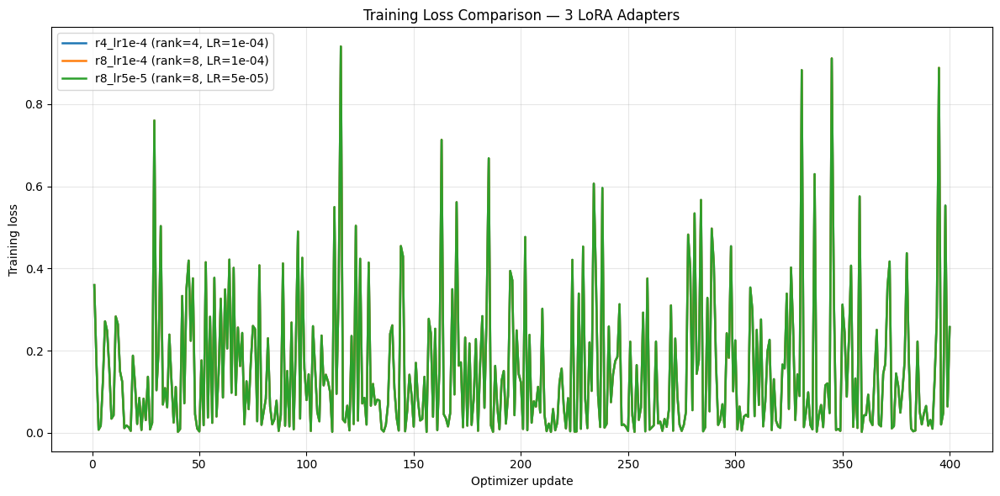

График сохранён: /content/drive/MyDrive/lab13/artifacts/task5_adapter_optimization/loss_comparison.png


In [11]:
TASK_DIR = ARTIFACTS / "task5_adapter_optimization"

ADAPTER_NAMES = [
    "r4_lr1e-4",
    "r8_lr1e-4",
    "r8_lr5e-5",
]

plt.figure(figsize=(12, 6))

for name in ADAPTER_NAMES:
    history_path = TASK_DIR / name / "loss_history.json"

    if not history_path.exists():
        print(f"Файл не найден: {history_path}")
        continue

    with open(history_path, "r", encoding="utf-8") as f:
        history = json.load(f)

    steps = history["steps"]
    losses = history["loss"]

    plt.plot(
        steps,
        losses,
        label=f'{name} (rank={history["rank"]}, LR={history["learning_rate"]:.0e})',
        linewidth=1.8,
    )

plt.xlabel("Optimizer update")
plt.ylabel("Training loss")
plt.title("Training Loss Comparison — 3 LoRA Adapters")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

output_path = TASK_DIR / "loss_comparison.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"График сохранён: {output_path}")


In [ ]:
'''
Добавил: 
1) кэширование VAE-латентов один раз и использование их во всех трёх экспериментах;
2) использование отдельного DDPMScheduler для обучения;
3) добавил cosine learning rate scheduler с 10 шагами warmup;
'''
# ------------------------------------------------------------
# 1. Проверка окружения и входных данных
# ------------------------------------------------------------

assert torch.cuda.is_available(), (
    "Для обучения необходима GPU: "
    "Colab -> Среда выполнения -> Сменить тип среды -> GPU."
)

DEVICE = "cuda"

assert "ARTIFACTS" in globals(), (
    "Сначала выполните начальные ячейки лабораторной."
)

TASK_DIR = ARTIFACTS / "task5_adapter_optimization"
TASK_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = ARTIFACTS / "task1_valid_images.json"
PLAN_PATH = ARTIFACTS / "task4_training_plan.json"

assert DATA_PATH.exists(), f"Не найден файл {DATA_PATH}"
assert PLAN_PATH.exists(), f"Не найден файл {PLAN_PATH}"

valid = json.loads(DATA_PATH.read_text(encoding="utf-8"))
plan = json.loads(PLAN_PATH.read_text(encoding="utf-8"))

CONFIGS = plan["configs"]
SCHEDULE = plan["schedule"]

assert len(CONFIGS) == 3, "Ожидаются три конфигурации LoRA."
assert SCHEDULE["max_train_steps"] == 400
assert len(valid) > 0, "Список изображений пуст."

RESOLUTION = int(SCHEDULE["resolution"])
MAX_STEPS = int(SCHEDULE["max_train_steps"])
CHECKPOINT_STEPS = list(SCHEDULE["checkpoint_steps"])
SEED = int(SCHEDULE["seed"])

BASE_MODEL = plan.get(
    "base_model",
    "runwayml/stable-diffusion-v1-5",
)

assert MAX_STEPS == 400
assert all(s in CHECKPOINT_STEPS for s in (200, 400))

for item in valid:
    assert Path(item["file_path"]).is_file(), item["file_path"]
    assert item.get("caption"), (
        f"Отсутствует caption у {item.get('file_name')}"
    )

print("GPU:", torch.cuda.get_device_name(0))
print("Изображений:", len(valid))
print("Конфигурации:", CONFIGS)
print("Шаги:", MAX_STEPS)
print("Checkpoints:", CHECKPOINT_STEPS)


# ------------------------------------------------------------
# 2. Воспроизводимость и подготовка изображений
# ------------------------------------------------------------

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


image_transform = transforms.Compose([
    transforms.Resize(
        RESOLUTION,
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.CenterCrop(RESOLUTION),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5],
    ),
])


def load_training_example(index, tokenizer):
    item = valid[index]

    with Image.open(item["file_path"]) as image:
        pixel_values = image_transform(image.convert("RGB"))

    tokens = tokenizer(
        item["caption"],
        padding="max_length",
        truncation=True,
        max_length=tokenizer.model_max_length,
        return_tensors="pt",
    ).input_ids[0]

    return pixel_values, tokens


# Фиксированный порядок: все конфигурации видят одинаковые изображения.
order_generator = torch.Generator().manual_seed(SEED)

image_order = torch.randperm(
    len(valid),
    generator=order_generator,
).tolist()


def save_json(path, obj):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    path.write_text(
        json.dumps(obj, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )


dataset_fingerprint = hashlib.sha256(
    json.dumps(
        [
            {
                "file": item["file_name"],
                "sha256": item.get("sha256"),
                "caption": item["caption"],
            }
            for item in valid
        ],
        ensure_ascii=False,
        sort_keys=True,
    ).encode("utf-8")
).hexdigest()


# ------------------------------------------------------------
# 3. Загрузка Stable Diffusion
# ------------------------------------------------------------

seed_everything(SEED)

pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL,
    torch_dtype=torch.float16,
    safety_checker=None,
    requires_safety_checker=False,
).to(DEVICE)

pipe.set_progress_bar_config(disable=True)

pipe.vae.requires_grad_(False)
pipe.text_encoder.requires_grad_(False)

pipe.vae.eval()
pipe.text_encoder.eval()

tokenizer = pipe.tokenizer

try:
    pipe.enable_attention_slicing()
except Exception as exc:
    print("Attention slicing не включён:", exc)

# Scheduler именно для обучения предсказанию шума.
noise_scheduler = DDPMScheduler.from_pretrained(
    BASE_MODEL,
    subfolder="scheduler",
)

prediction_type = noise_scheduler.config.prediction_type

assert prediction_type in ("epsilon", "v_prediction"), (
    f"Неподдерживаемый prediction_type: {prediction_type}"
)

versions = {
    "torch": torch.__version__,
    "diffusers": diffusers.__version__,
    "transformers": transformers.__version__,
    "peft": peft.__version__,
}

print("Versions:", versions)
print("Prediction type:", prediction_type)


# ------------------------------------------------------------
# 4. Конфигурация LoRA
# ------------------------------------------------------------

def make_lora_config(rank):
    return LoraConfig(
        r=int(rank),
        lora_alpha=int(rank),
        target_modules=[
            "to_q",
            "to_k",
            "to_v",
            "to_out.0",
        ],
        lora_dropout=0.0,
        bias="none",
        init_lora_weights="gaussian",
    )


# ------------------------------------------------------------
# 5. Кэшируем латенты и текстовые embeddings один раз
# ------------------------------------------------------------

print("\nКэширование латентов и текстовых embeddings...")

cached_latents = []
caption_tokens = []

# Используем отдельный seed на каждый объект.
# Латенты затем повторно используются во всех конфигурациях.
for i in range(len(valid)):
    pixel_values, ids = load_training_example(i, tokenizer)

    pixel_values = pixel_values.unsqueeze(0).to(
        device=DEVICE,
        dtype=pipe.vae.dtype,
    )

    latent_generator = torch.Generator(
        device=DEVICE
    ).manual_seed(SEED + 10_000 + i)

    with torch.no_grad():
        latent_dist = pipe.vae.encode(pixel_values).latent_dist

        latents = latent_dist.sample(
            generator=latent_generator
        )

        latents = latents * pipe.vae.config.scaling_factor

    cached_latents.append(latents.detach())
    caption_tokens.append(ids)

text_embeddings = []

with torch.no_grad():
    for ids in caption_tokens:
        emb = pipe.text_encoder(
            ids.unsqueeze(0).to(DEVICE)
        )[0]

        text_embeddings.append(emb.detach())

print("Закэшировано латентов:", len(cached_latents))
print("Закэшировано embeddings:", len(text_embeddings))


# ------------------------------------------------------------
# 6. Фиксированная оценка loss
# ------------------------------------------------------------

# Одна и та же выборка, те же латенты, шум и timestep
# для начальной модели и обоих checkpoint.
EVAL_IMAGES = min(8, len(cached_latents))


@torch.no_grad()
def evaluate_fixed_loss(model):
    was_training = model.training
    model.eval()

    eval_losses = []

    for i in range(EVAL_IMAGES):
        latents = cached_latents[i]

        noise_generator = torch.Generator(
            device=DEVICE
        ).manual_seed(SEED + 300_000 + i)

        timestep_generator = torch.Generator(
            device=DEVICE
        ).manual_seed(SEED + 400_000 + i)

        noise = torch.randn(
            latents.shape,
            generator=noise_generator,
            device=DEVICE,
            dtype=latents.dtype,
        )

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],),
            generator=timestep_generator,
            device=DEVICE,
        ).long()

        noisy_latents = noise_scheduler.add_noise(
            latents,
            noise,
            timesteps,
        )

        if prediction_type == "v_prediction":
            target = noise_scheduler.get_velocity(
                latents,
                noise,
                timesteps,
            )
        else:
            target = noise

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            prediction = model(
                noisy_latents,
                timesteps,
                encoder_hidden_states=text_embeddings[i],
                return_dict=False,
            )[0]

        eval_losses.append(
            F.mse_loss(
                prediction.float(),
                target.float(),
                reduction="mean",
            ).item()
        )

    if was_training:
        model.train()

    return float(np.mean(eval_losses))


# ------------------------------------------------------------
# 7. Обучение трёх независимых адаптеров
# ------------------------------------------------------------

training_results = []
checkpoint_index = []

WARMUP_STEPS = 10
EVAL_AT = sorted(set([0] + CHECKPOINT_STEPS))

for config_index, cfg in enumerate(CONFIGS):
    name = cfg["name"]
    rank = int(cfg["rank"])
    lr = float(cfg["lr"])

    print("\n" + "=" * 65)
    print(f"Обучение {name}: rank={rank}, lr={lr}")
    print("=" * 65)

    # Используем новый каталог, чтобы не смешивать старые результаты.
    adapter_dir = TASK_DIR / name
    adapter_dir.mkdir(parents=True, exist_ok=True)

    seed_everything(SEED)

    # Независимая копия исходного UNet для каждого адаптера.
    base_unet = copy.deepcopy(pipe.unet)
    base_unet.requires_grad_(False)

    model = get_peft_model(
        base_unet,
        make_lora_config(rank),
    )

    model.train()

    trainable_params = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    assert trainable_params, "Нет обучаемых параметров LoRA."

    bad_params = [
        n for n, p in model.named_parameters()
        if p.requires_grad and "lora_" not in n.lower()
    ]

    assert not bad_params, (
        f"Обнаружены параметры вне LoRA: {bad_params[:10]}"
    )

    trainable_count = sum(
        p.numel() for p in trainable_params
    )

    print("Trainable parameters:", f"{trainable_count:,}")
    print("Trainable dtype:", trainable_params[0].dtype)

    optimizer = torch.optim.AdamW(
        trainable_params,
        lr=lr,
        betas=(
            float(SCHEDULE["adam_beta1"]),
            float(SCHEDULE["adam_beta2"]),
        ),
        weight_decay=float(SCHEDULE["adam_weight_decay"]),
        eps=float(SCHEDULE["adam_epsilon"]),
    )

    lr_scheduler = get_scheduler(
        name="cosine",
        optimizer=optimizer,
        num_warmup_steps=WARMUP_STEPS,
        num_training_steps=MAX_STEPS,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=True,
    )

    losses = []
    grad_norms = []
    fixed_eval = {}
    successful_updates = 0
    start_time = time.time()

    # Оценка до обучения.
    fixed_eval[0] = evaluate_fixed_loss(model)

    print(
        f"{name} | fixed eval до обучения: "
        f"{fixed_eval[0]:.6f}"
    )

    def save_checkpoint(step):
        ckpt_dir = adapter_dir / f"checkpoint-{step}"
        ckpt_dir.mkdir(parents=True, exist_ok=True)

        # Переносимый PEFT-адаптер.
        model.save_pretrained(
            str(ckpt_dir / "adapter"),
            safe_serialization=True,
        )

        # Явная копия обучаемых весов.
        lora_state = {
            key: value.detach().cpu().contiguous()
            for key, value in model.state_dict().items()
            if "lora_" in key.lower()
        }

        assert lora_state, "Не найдены веса LoRA."

        torch.save(
            lora_state,
            ckpt_dir / "lora_trainable_weights.pt",
        )

        torch.save(
            optimizer.state_dict(),
            ckpt_dir / "optimizer.pt",
        )

        torch.save(
            lr_scheduler.state_dict(),
            ckpt_dir / "lr_scheduler.pt",
        )

        torch.save(
            scaler.state_dict(),
            ckpt_dir / "scaler.pt",
        )

        torch.save(
            {
                "torch_rng_state": torch.get_rng_state(),
                "cuda_rng_states": torch.cuda.get_rng_state_all(),
                "numpy_rng_state": np.random.get_state(),
                "python_rng_state": random.getstate(),
            },
            ckpt_dir / "rng_state.pt",
        )

        metadata = {
            "task": "LoRA adapter optimization",
            "adapter_name": name,
            "base_model": BASE_MODEL,
            "rank": rank,
            "learning_rate_initial": lr,
            "current_learning_rate": (
                lr_scheduler.get_last_lr()[0]
            ),
            "global_step": step,
            "max_train_steps": MAX_STEPS,
            "checkpoint_steps": CHECKPOINT_STEPS,
            "resolution": RESOLUTION,
            "seed": SEED,
            "optimizer": "AdamW",
            "lr_scheduler": "cosine",
            "warmup_steps": WARMUP_STEPS,
            "mixed_precision": "fp16",
            "prediction_type": prediction_type,
            "loss": losses[-1] if losses else None,
            "fixed_eval_loss": fixed_eval.get(step),
            "dataset_size": len(valid),
            "dataset_fingerprint": dataset_fingerprint,
            "versions": versions,
        }

        save_json(
            ckpt_dir / "checkpoint_metadata.json",
            metadata,
        )

        checkpoint_index.append({
            "adapter_name": name,
            "rank": rank,
            "learning_rate": lr,
            "step": step,
            "checkpoint_dir": str(ckpt_dir),
            "adapter_dir": str(ckpt_dir / "adapter"),
            "metadata_file": str(
                ckpt_dir / "checkpoint_metadata.json"
            ),
            "optimizer_file": str(ckpt_dir / "optimizer.pt"),
            "scheduler_file": str(
                ckpt_dir / "lr_scheduler.pt"
            ),
            "scaler_file": str(ckpt_dir / "scaler.pt"),
            "weights_file": str(
                ckpt_dir / "lora_trainable_weights.pt"
            ),
        })

        print("Checkpoint сохранён:", ckpt_dir)

    # --------------------------------------------------------
    # Основной цикл: один шаг = один optimizer update
    # --------------------------------------------------------

    for step in range(1, MAX_STEPS + 1):
        dataset_index = image_order[
            (step - 1) % len(image_order)
        ]

        latents = cached_latents[dataset_index]
        encoder_hidden_states = text_embeddings[dataset_index]

        optimizer.zero_grad(set_to_none=True)

        # Отдельные генераторы для шума и timestep.
        # Они одинаковы на соответствующем шаге у всех адаптеров.
        noise_generator = torch.Generator(
            device=DEVICE
        ).manual_seed(SEED + 100_000 + step)

        timestep_generator = torch.Generator(
            device=DEVICE
        ).manual_seed(SEED + 200_000 + step)

        noise = torch.randn(
            latents.shape,
            generator=noise_generator,
            device=DEVICE,
            dtype=latents.dtype,
        )

        timesteps = torch.randint(
            0,
            noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],),
            generator=timestep_generator,
            device=DEVICE,
        ).long()

        noisy_latents = noise_scheduler.add_noise(
            latents,
            noise,
            timesteps,
        )

        if prediction_type == "v_prediction":
            target = noise_scheduler.get_velocity(
                latents,
                noise,
                timesteps,
            )
        else:
            target = noise

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
        ):
            prediction = model(
                noisy_latents,
                timesteps,
                encoder_hidden_states=encoder_hidden_states,
                return_dict=False,
            )[0]

            loss = F.mse_loss(
                prediction.float(),
                target.float(),
                reduction="mean",
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"{name}: loss NaN/Inf на шаге {step}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        grad_norm = torch.nn.utils.clip_grad_norm_(
            trainable_params,
            max_norm=float(SCHEDULE["max_grad_norm"]),
        )

        if not torch.isfinite(grad_norm):
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(
                f"{name}: grad_norm NaN/Inf на шаге {step}"
            )

        grad_norms.append(float(grad_norm.detach().cpu()))

        scale_before = scaler.get_scale()

        scaler.step(optimizer)
        scaler.update()

        scale_after = scaler.get_scale()

        # При уменьшении scale GradScaler пропустил optimizer update.
        if scale_after < scale_before:
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(
                f"{name}: GradScaler пропустил обновление "
                f"на шаге {step}."
            )

        lr_scheduler.step()
        successful_updates += 1

        current_loss = float(loss.detach().cpu())
        losses.append(current_loss)

        # Сохраняем журнал периодически, чтобы не записывать JSON
        # после каждого шага.
        if step == 1 or step % 25 == 0:
            save_json(
                adapter_dir / "loss_history.json",
                {
                    "adapter_name": name,
                    "rank": rank,
                    "learning_rate_initial": lr,
                    "steps": list(range(1, len(losses) + 1)),
                    "loss": losses,
                    "grad_norm": grad_norms,
                },
            )

            print(
                f"{name} | step {step:03d}/{MAX_STEPS} | "
                f"loss={current_loss:.6f} | "
                f"lr={lr_scheduler.get_last_lr()[0]:.2e} | "
                f"grad_norm={grad_norms[-1]:.4f} | "
                f"scale={scaler.get_scale():.0f}"
            )

        # Checkpoint и fixed evaluation.
        if step in CHECKPOINT_STEPS:
            save_checkpoint(step)

            fixed_eval[step] = evaluate_fixed_loss(model)

            print(
                f"{name} | fixed eval step={step}: "
                f"{fixed_eval[step]:.6f}"
            )

            save_json(
                adapter_dir / "fixed_eval_history.json",
                {
                    "adapter_name": name,
                    "fixed_eval_loss": {
                        str(k): v
                        for k, v in fixed_eval.items()
                    },
                    "num_images": EVAL_IMAGES,
                    "seed": SEED,
                },
            )

    elapsed = time.time() - start_time

    assert successful_updates == MAX_STEPS

    # Финальная запись всей истории.
    save_json(
        adapter_dir / "loss_history.json",
        {
            "adapter_name": name,
            "rank": rank,
            "learning_rate_initial": lr,
            "steps": list(range(1, len(losses) + 1)),
            "loss": losses,
            "grad_norm": grad_norms,
        },
    )

    result = {
        "adapter_name": name,
        "rank": rank,
        "learning_rate": lr,
        "optimizer_updates": successful_updates,
        "checkpoint_steps": CHECKPOINT_STEPS,
        "initial_loss": losses[0],
        "final_loss": losses[-1],
        "mean_loss": float(np.mean(losses)),
        "initial_mean_loss_50": float(np.mean(losses[:50])),
        "final_mean_loss_50": float(np.mean(losses[-50:])),
        "fixed_eval_loss": {
            str(k): v for k, v in fixed_eval.items()
        },
        "mean_grad_norm": float(np.mean(grad_norms)),
        "elapsed_sec": round(elapsed, 2),
        "dataset_fingerprint": dataset_fingerprint,
        "checkpoints": [
            str(adapter_dir / f"checkpoint-{s}")
            for s in CHECKPOINT_STEPS
        ],
    }

    training_results.append(result)

    save_json(
        adapter_dir / "training_metrics.json",
        result,
    )

    print(
        f"\nЗавершён {name}: "
        f"updates={successful_updates}, "
        f"mean loss={result['mean_loss']:.6f}, "
        f"fixed eval 0/200/400="
        f"{fixed_eval[0]:.6f}/"
        f"{fixed_eval[200]:.6f}/"
        f"{fixed_eval[400]:.6f}, "
        f"time={elapsed / 60:.1f} min"
    )

    del model, base_unet, optimizer, lr_scheduler, scaler
    del trainable_params
    gc.collect()
    torch.cuda.empty_cache()


# ------------------------------------------------------------
# 8. Сводный отчёт
# ------------------------------------------------------------

assert len(training_results) == 3
assert all(
    r["optimizer_updates"] == MAX_STEPS
    for r in training_results
)

assert len({
    r["dataset_fingerprint"]
    for r in training_results
}) == 1

report = {
    "task": "LoRA adapter optimization",
    "status": "completed",
    "base_model": BASE_MODEL,
    "seed": SEED,
    "resolution": RESOLUTION,
    "dataset_size": len(valid),
    "max_train_steps": MAX_STEPS,
    "checkpoint_steps": CHECKPOINT_STEPS,
    "prediction_type": prediction_type,
    "optimizer": "AdamW",
    "lr_scheduler": "cosine",
    "warmup_steps": WARMUP_STEPS,
    "mixed_precision": "fp16",
    "fixed_eval_images": EVAL_IMAGES,
    "versions": versions,
    "configs": CONFIGS,
    "results": training_results,
    "checkpoints": checkpoint_index,
}

save_json(
    TASK_DIR / "task5_training_report.json",
    report,
)

save_json(
    TASK_DIR / "task5_checkpoint_index.json",
    {
        "task": report["task"],
        "status": report["status"],
        "checkpoints": checkpoint_index,
    },
)

print("\n" + "=" * 65)
print("ЗАДАНИЕ 5 ЗАВЕРШЕНО")
print("=" * 65)

for result in training_results:
    eval_loss = result["fixed_eval_loss"]

    print(
        f"{result['adapter_name']:14s} "
        f"rank={result['rank']:2d} "
        f"lr={result['learning_rate']:.1e} "
        f"updates={result['optimizer_updates']:3d} "
        f"mean={result['mean_loss']:.6f} "
        f"fixed={eval_loss['0']:.6f}"
        f" -> {eval_loss['200']:.6f}"
        f" -> {eval_loss['400']:.6f}"
    )

print("\nОтчёт:", TASK_DIR / "task5_training_report.json")
print("Индекс checkpoints:", TASK_DIR / "task5_checkpoint_index.json")
print("Результаты:", TASK_DIR)

print("\nALL_OK: три адаптера обучены и checkpoints сохранены.")


GPU: Tesla T4
Изображений: 28
Конфигурации: [{'name': 'r4_lr1e-4', 'rank': 4, 'lr': 0.0001}, {'name': 'r8_lr1e-4', 'rank': 8, 'lr': 0.0001}, {'name': 'r8_lr5e-5', 'rank': 8, 'lr': 5e-05}]
Шаги: 400
Checkpoints: [200, 400]


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Versions: {'torch': '2.11.0+cu130', 'diffusers': '0.41.0', 'transformers': '5.20.2', 'peft': '0.21.2'}
Prediction type: epsilon

Кэширование латентов и текстовых embeddings...
Закэшировано латентов: 28
Закэшировано embeddings: 28

Обучение r4_lr1e-4: rank=4, lr=0.0001
Trainable parameters: 797,184
Trainable dtype: torch.float32
r4_lr1e-4 | fixed eval до обучения: 0.104994
r4_lr1e-4 | step 001/400 | loss=0.307185 | lr=1.00e-05 | grad_norm=0.0628 | scale=65536
r4_lr1e-4 | step 025/400 | loss=0.300853 | lr=9.96e-05 | grad_norm=0.0905 | scale=65536
r4_lr1e-4 | step 050/400 | loss=0.017416 | lr=9.74e-05 | grad_norm=0.0097 | scale=65536
r4_lr1e-4 | step 075/400 | loss=0.455424 | lr=9.33e-05 | grad_norm=0.0953 | scale=65536
r4_lr1e-4 | step 100/400 | loss=0.003707 | lr=8.74e-05 | grad_norm=0.0039 | scale=65536
r4_lr1e-4 | step 125/400 | loss=0.009030 | lr=8.00e-05 | grad_norm=0.0075 | scale=65536
r4_lr1e-4 | step 150/400 | loss=0.015628 | lr=7.14e-05 | grad_norm=0.0114 | scale=65536
r4_lr1e-4

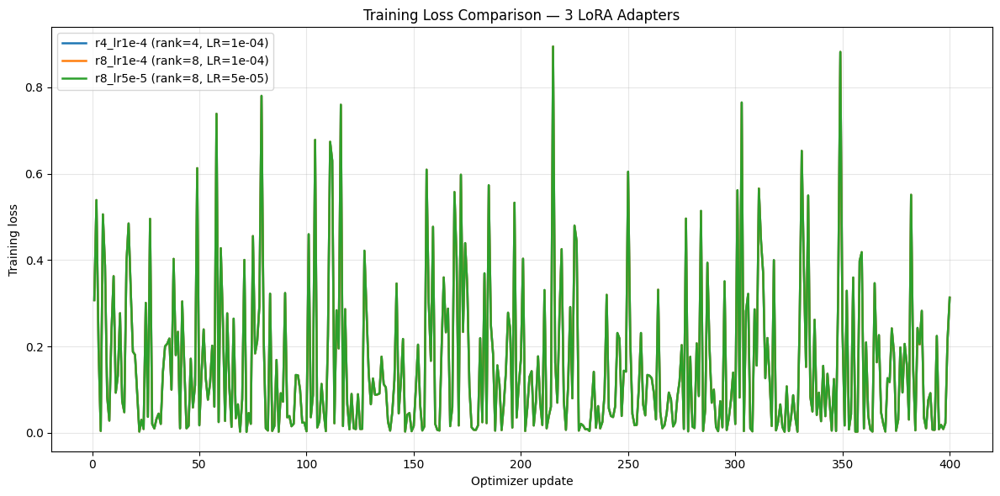

График сохранён: /content/drive/MyDrive/lab13/artifacts/task5_adapter_optimization/loss_comparison.png


In [13]:
TASK_DIR = ARTIFACTS / "task5_adapter_optimization"

ADAPTER_NAMES = [
    "r4_lr1e-4",
    "r8_lr1e-4",
    "r8_lr5e-5",
]

plt.figure(figsize=(12, 6))

for name in ADAPTER_NAMES:
    history_path = TASK_DIR / name / "loss_history.json"

    if not history_path.exists():
        print(f"Файл не найден: {history_path}")
        continue

    with open(history_path, "r", encoding="utf-8") as f:
        history = json.load(f)

    steps = history["steps"]
    losses = history["loss"]

    plt.plot(
        steps,
        losses,
        label=f'{name} (rank={history["rank"]}, LR={history["learning_rate_initial"]:.0e})',
        linewidth=1.8,
    )

plt.xlabel("Optimizer update")
plt.ylabel("Training loss")
plt.title("Training Loss Comparison — 3 LoRA Adapters")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

output_path = TASK_DIR / "loss_comparison.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print(f"График сохранён: {output_path}")


schedule: {
  "max_train_steps": 400,
  "checkpoint_steps": [
    200,
    400
  ],
  "batch_size": 1,
  "gradient_accumulation_steps": 1,
  "optimizer": "adamw",
  "adam_beta1": 0.9,
  "adam_beta2": 0.999,
  "adam_weight_decay": 0.01,
  "adam_epsilon": 1e-08,
  "lr_scheduler": "constant",
  "lr_warmup_steps": 0,
  "max_grad_norm": 1.0,
  "mixed_precision": "fp16",
  "resolution": 512,
  "seed": 64
}
configs : ['r4_lr1e-4', 'r8_lr1e-4', 'r8_lr5e-5']
train images: 28


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]


=== training r4_lr1e-4 (rank=4, lr=0.0001) ===


/tmp/ipykernel_711/4260614955.py:172: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print(f'[{name}] step {step}/{max_steps}  loss={float(loss):.4f}  '


[r4_lr1e-4] step 1/400  loss=0.2039  elapsed=0.5s
[r4_lr1e-4] step 50/400  loss=0.0529  elapsed=21.6s
[r4_lr1e-4] step 100/400  loss=0.1847  elapsed=43.9s
[r4_lr1e-4] step 150/400  loss=0.3007  elapsed=65.3s
[r4_lr1e-4] saved step0200  loss=0.0118
[r4_lr1e-4] step 200/400  loss=0.0118  elapsed=86.9s
[r4_lr1e-4] step 250/400  loss=0.0782  elapsed=108.5s
[r4_lr1e-4] step 300/400  loss=0.5198  elapsed=130.2s
[r4_lr1e-4] step 350/400  loss=0.0031  elapsed=151.6s
[r4_lr1e-4] saved step0400  loss=0.0357
[r4_lr1e-4] step 400/400  loss=0.0357  elapsed=173.3s

=== training r8_lr1e-4 (rank=8, lr=0.0001) ===
[r8_lr1e-4] step 1/400  loss=0.2039  elapsed=0.4s
[r8_lr1e-4] step 50/400  loss=0.0529  elapsed=21.3s
[r8_lr1e-4] step 100/400  loss=0.1846  elapsed=42.7s
[r8_lr1e-4] step 150/400  loss=0.3006  elapsed=64.1s
[r8_lr1e-4] saved step0200  loss=0.0118
[r8_lr1e-4] step 200/400  loss=0.0118  elapsed=85.8s
[r8_lr1e-4] step 250/400  loss=0.0782  elapsed=107.3s
[r8_lr1e-4] step 300/400  loss=0.5197  e

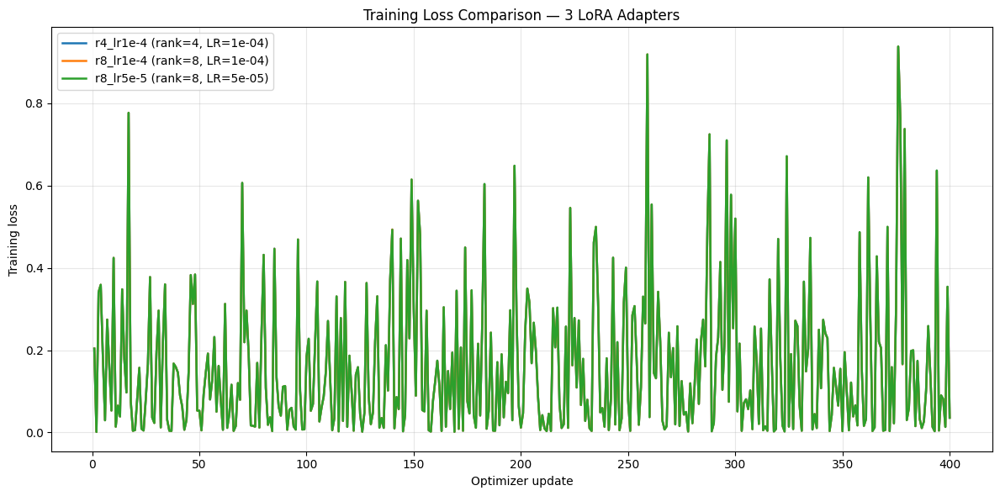

График сохранён: /content/drive/MyDrive/lab13/artifacts/task5_adapter_optimization/loss_comparison.png

errors:  0
ALL_OK:  True
artifacts: /content/drive/MyDrive/lab13/artifacts/task5_training_report.json
checkpoints: /content/drive/MyDrive/lab13/artifacts/lora_checkpoints/

OK: чекпоинты доступны следующему этапу.


In [14]:
PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
DATA_ROOT   = Path(globals().get('DATA_ROOT',   PROJECT_DIR / 'data'))
SEED        = int(globals().get('SEED', 64))
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
FAST_DEV_RUN = bool(globals().get('FAST_DEV_RUN', True))

if DEVICE != 'cuda':
    raise RuntimeError('LoRA требует GPU.')

CKPT_ROOT = ARTIFACTS / 'lora_checkpoints'
CKPT_ROOT.mkdir(parents=True, exist_ok=True)
TASK_DIR = ARTIFACTS / 'task5_adapter_optimization'
TASK_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. читаем план из задания 4 ---
plan_path = ARTIFACTS / 'task4_training_plan.json'
if not plan_path.exists():
    raise FileNotFoundError(f'Нет {plan_path}. Сначала выполните задание 4.')
plan = json.loads(plan_path.read_text(encoding='utf-8'))
SCHEDULE = plan['schedule']
CONFIGS  = plan['configs']
BASE_MODEL = plan['base_model']
TARGET_MODULES = plan['target_modules']
print('schedule:', json.dumps(SCHEDULE, indent=2))
print('configs :', [c['name'] for c in CONFIGS])

# --- 2. датасет ---
valid_path = ARTIFACTS / 'task1_valid_images.json'
if not valid_path.exists():
    raise FileNotFoundError(f'Нет {valid_path}. Сначала выполните задание 1.')
valid = json.loads(valid_path.read_text(encoding='utf-8'))
print(f'train images: {len(valid)}')

class ButterflyDataset(Dataset):
    def __init__(self, items, resolution, tokenizer):
        self.items, self.resolution, self.tokenizer = items, resolution, tokenizer
        self.tf = transforms.Compose([
            transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BILINEAR),
            transforms.CenterCrop(resolution),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        it = self.items[i]
        img = Image.open(it['file_path']).convert('RGB')
        pixel_values = self.tf(img)
        tok = self.tokenizer(
            it['caption'], padding='max_length', max_length=77,
            truncation=True, return_tensors='pt',
        )
        return {'pixel_values': pixel_values,
                'input_ids': tok.input_ids[0],
                'attention_mask': tok.attention_mask[0],
                'caption': it['caption']}

# --- 3. загружаем SD 1.5 и замораживаем основу ---
pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL, torch_dtype=torch.float16,
    safety_checker=None, requires_safety_checker=False,
).to(DEVICE)
pipe.vae.requires_grad_(False)
pipe.text_encoder.requires_grad_(False)
pipe.unet.requires_grad_(False)
pipe.vae.eval()
pipe.text_encoder.eval()

@torch.no_grad()
def encode_batch(batch):
    px = batch['pixel_values'].to(DEVICE, dtype=torch.float16)
    latents = pipe.vae.encode(px).latent_dist.sample() * pipe.vae.config.scaling_factor
    text = pipe.text_encoder(batch['input_ids'].to(DEVICE))[0]
    return latents, text, batch['attention_mask'].to(DEVICE)

# --- 4. обучение одной конфигурации ---
def train_one(config):
    name, rank, lr = config['name'], config['rank'], config['lr']
    out_dir = CKPT_ROOT / name
    out_dir.mkdir(parents=True, exist_ok=True)
    task_run_dir = TASK_DIR / name
    task_run_dir.mkdir(parents=True, exist_ok=True)

    torch.manual_seed(SEED)  # фиксируем init LoRA
    unet = copy.deepcopy(pipe.unet)
    unet.requires_grad_(False)
    peft_unet = get_peft_model(unet, LoraConfig(
        r=rank, lora_alpha=rank, target_modules=TARGET_MODULES,
        lora_dropout=0.0, bias='none', init_lora_weights='gaussian',
    ))
    peft_unet.train()

    trainable = [p for p in peft_unet.parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for p in trainable)

    optimizer = torch.optim.AdamW(
        trainable, lr=lr,
        betas=(SCHEDULE['adam_beta1'], SCHEDULE['adam_beta2']),
        weight_decay=SCHEDULE['adam_weight_decay'],
        eps=SCHEDULE['adam_epsilon'],
    )
    scaler = torch.amp.GradScaler('cuda') if SCHEDULE['mixed_precision'] == 'fp16' else None

    dataset = ButterflyDataset(valid, SCHEDULE['resolution'], pipe.tokenizer)
    g = torch.Generator().manual_seed(SEED)
    loader = DataLoader(dataset, batch_size=SCHEDULE['batch_size'], shuffle=True,
                        generator=g, drop_last=True, num_workers=0, pin_memory=True)

    noise_scheduler = DDPMScheduler.from_config(pipe.scheduler.config)
    max_steps = SCHEDULE['max_train_steps']
    ckpt_steps = set(SCHEDULE['checkpoint_steps'])
    grad_accum = SCHEDULE['gradient_accumulation_steps']

    history = []
    step = 0
    t0 = time.time()
    while step < max_steps:
        for batch in loader:
            with torch.no_grad():
                latents, text, mask = encode_batch(batch)

            noise = torch.randn_like(latents)
            bsz = latents.shape[0]
            timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps,
                                      (bsz,), device=DEVICE, dtype=torch.long)
            noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

            with torch.autocast('cuda', dtype=torch.float16, enabled=(scaler is not None)):
                pred = peft_unet(noisy_latents, timesteps,
                                 encoder_hidden_states=text).sample
                loss = F.mse_loss(pred.float(), noise.float(), reduction='mean')

            if scaler is not None:
                scaler.scale(loss).backward()
            else:
                loss.backward()

            step_here = step + 1
            if step_here % grad_accum == 0:
                if scaler is not None:
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(trainable, SCHEDULE['max_grad_norm'])
                    scaler.step(optimizer); scaler.update()
                else:
                    torch.nn.utils.clip_grad_norm_(trainable, SCHEDULE['max_grad_norm'])
                    optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            history.append({'step': step_here, 'loss': float(loss.detach().item()), 'lr': lr})

            if step_here in ckpt_steps:
                ckpt_dir = out_dir / f'step{step_here:04d}'
                ckpt_dir.mkdir(parents=True, exist_ok=True)
                peft_unet.save_pretrained(ckpt_dir / 'lora')
                torch.save({
                    'step': step_here,
                    'optimizer': optimizer.state_dict(),
                    'scaler': scaler.state_dict() if scaler else None,
                    'config': config,
                    'schedule': SCHEDULE,
                }, ckpt_dir / 'trainer_state.pt')
                (ckpt_dir / 'card.json').write_text(json.dumps({
                    'config': config, 'step': step_here,
                    'n_trainable': n_trainable,
                    'loss_last': float(loss.detach().item()),
                }, ensure_ascii=False, indent=2))
                print(f'[{name}] saved {ckpt_dir.name}  loss={float(loss):.4f}')

            step += 1
            if step % 50 == 0 or step == 1:
                print(f'[{name}] step {step}/{max_steps}  loss={float(loss):.4f}  '
                      f'elapsed={time.time()-t0:.1f}s')

            if step >= max_steps:
                break

    dt = time.time() - t0

    # --- история loss в формате, который читает график ---
    loss_history = {
        'name': name,
        'rank': rank,
        'learning_rate_initial': lr,
        'steps': [h['step'] for h in history],
        'loss': [h['loss'] for h in history],
        'final_loss': history[-1]['loss'] if history else None,
    }
    (task_run_dir / 'loss_history.json').write_text(
        json.dumps(loss_history, ensure_ascii=False, indent=2))

    del peft_unet, optimizer, scaler
    torch.cuda.empty_cache()

    return {
        'config': config,
        'n_trainable': n_trainable,
        'steps': step,
        'elapsed_sec': round(dt, 1),
        'sec_per_step': round(dt / max(1, step), 3),
        'history': history,
        'checkpoints': sorted(str(p) for p in out_dir.glob('step*')),
        'final_loss': history[-1]['loss'] if history else None,
        'loss_history_path': str(task_run_dir / 'loss_history.json'),
    }

# --- 5. обучаем три независимых адаптера ---
summary = []
for cfg in CONFIGS:
    print(f'\n=== training {cfg["name"]} (rank={cfg["rank"]}, lr={cfg["lr"]}) ===')
    summary.append(train_one(cfg))

# --- 6. артефакты ---
report = {'base_model': BASE_MODEL, 'schedule': SCHEDULE, 'runs': summary}
(ARTIFACTS / 'task5_training_report.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2))

print('\n--- Фактически измеренные значения ---')
for r in summary:
    c = r['config']
    print(f"{c['name']:12s} rank={c['rank']:2d} lr={c['lr']:.1e}  "
          f"steps={r['steps']:4d}  trainable={r['n_trainable']:,}  "
          f"sec/step={r['sec_per_step']:.3f}  "
          f"final_loss={r['final_loss']:.4f}  "
          f"ckpts={len(r['checkpoints'])}")

# --- 7. проверки ---
errors = []
for r in summary:
    if r['steps'] != SCHEDULE['max_train_steps']:
        errors.append(f"{r['config']['name']}: steps={r['steps']} != max_train_steps")
    if len(r['checkpoints']) != len(SCHEDULE['checkpoint_steps']):
        errors.append(f"{r['config']['name']}: ckpts={len(r['checkpoints'])} != "
                      f"{len(SCHEDULE['checkpoint_steps'])}")
    if math.isnan(r['final_loss']) or math.isinf(r['final_loss']):
        errors.append(f"{r['config']['name']}: loss is NaN/inf")
    for ckpt in r['checkpoints']:
        p = Path(ckpt)
        if not (p / 'lora').exists():
            errors.append(f'{ckpt}: missing lora/')
        if not (p / 'trainer_state.pt').exists():
            errors.append(f'{ckpt}: missing trainer_state.pt')

# sanity: loss'ы трёх конфигураций должны РАЗЛИЧАТЬСЯ
finals = [r['final_loss'] for r in summary]
if len(set(round(x, 4) for x in finals)) < 2:
    errors.append(f'final_loss одинаков у всех конфигураций: {finals} — LoRA не учится')

# --- 8. график loss ---
ADAPTER_NAMES = [c['name'] for c in CONFIGS]
plt.figure(figsize=(12, 6))
for name in ADAPTER_NAMES:
    history_path = TASK_DIR / name / 'loss_history.json'
    if not history_path.exists():
        print(f'Файл не найден: {history_path}')
        continue
    with open(history_path, 'r', encoding='utf-8') as f:
        h = json.load(f)
    plt.plot(h['steps'], h['loss'],
             label=f"{name} (rank={h['rank']}, LR={h['learning_rate_initial']:.0e})",
             linewidth=1.8)
plt.xlabel('Optimizer update')
plt.ylabel('Training loss')
plt.title('Training Loss Comparison — 3 LoRA Adapters')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
loss_png = TASK_DIR / 'loss_comparison.png'
plt.savefig(loss_png, dpi=200, bbox_inches='tight')
plt.show()
print(f'График сохранён: {loss_png}')

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
print(f'artifacts: {ARTIFACTS}/task5_training_report.json')
print(f'checkpoints: {CKPT_ROOT}/')

assert not errors, f'Обучение не прошло проверки: {errors[:5]}'
print('\nOK: чекпоинты доступны следующему этапу.')

### Признаки CLIP для независимой оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings.

**Результат.** Проверяемое состояние «Признаки CLIP для независимой оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings» и его результат доступен следующему этапу.

In [15]:
# ============================================================
# Генерация LoRA-картинок: только последний чекпоинт каждого адаптера
# ============================================================
import json, time, gc
from pathlib import Path

import torch
from diffusers import StableDiffusionPipeline

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
SEED        = int(globals().get('SEED', 64))
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
FAST_DEV_RUN = bool(globals().get('FAST_DEV_RUN', True))

if DEVICE != 'cuda':
    raise RuntimeError('Генерация LoRA требует GPU.')

GEN_ROOT  = ARTIFACTS / 'lora_generations'
CKPT_ROOT = ARTIFACTS / 'lora_checkpoints'
GEN_ROOT.mkdir(parents=True, exist_ok=True)

# --- план и prompts ---
plan = json.loads((ARTIFACTS / 'task4_training_plan.json').read_text(encoding='utf-8'))
CONFIGS    = plan['configs']
BASE_MODEL = plan['base_model']

held = json.loads((ARTIFACTS / 'task2_held_out_prompts.json').read_text(encoding='utf-8'))
prompts, seeds = held['prompts'], held['seeds']

# --- inference protocol — как в baseline ---
baseline   = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
GEN_KWARGS = baseline['inference_protocol']
print('inference protocol:', GEN_KWARGS)

# --- для каждого адаптера берём ПОСЛЕДНИЙ step ---
last_ckpts = []
for cfg in CONFIGS:
    name = cfg['name']
    step_dirs = sorted((CKPT_ROOT / name).glob('step*'))
    if not step_dirs:
        print(f'WARN: нет чекпоинтов для {name}')
        continue
    step_dir = step_dirs[-1]                      # последний (например step0400)
    lora_dir = step_dir / 'lora'
    weights = (list(lora_dir.glob('*.safetensors')) + list(lora_dir.glob('*.bin'))) \
              if lora_dir.exists() else []
    if not weights:
        print(f'WARN: в {lora_dir} нет весов')
        continue
    last_ckpts.append({
        'name': name, 'step': step_dir.name,
        'lora_dir': str(lora_dir),
        'weights_file': str(weights[0]),
        'rank': cfg['rank'], 'lr': cfg['lr'],
    })

print(f'\nпоследних чекпоинтов: {len(last_ckpts)}')
for c in last_ckpts:
    print(f"  {c['name']:12s} {c['step']:10s}  {Path(c['weights_file']).name}")

if not last_ckpts:
    raise RuntimeError('Нечего генерировать: нет валидных чекпоинтов.')

# в smoke — только 2 пары на чекпоинт
pairs = ([{'prompt': prompts[0], 'seed': seeds[0]},
          {'prompt': prompts[1], 'seed': seeds[0]}]
         if FAST_DEV_RUN else held['pairs'])

# --- грузим базу один раз ---
t0 = time.time()
pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL, torch_dtype=torch.float16,
    safety_checker=None, requires_safety_checker=False,
).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print(f'SD 1.5 загружена за {time.time()-t0:.1f} c')

# --- генерируем ---
summary = []
for ci, ckpt in enumerate(last_ckpts, 1):
    out_dir = GEN_ROOT / ckpt['name'] / ckpt['step']
    out_dir.mkdir(parents=True, exist_ok=True)

    try: pipe.unload_lora_weights()
    except Exception: pass

    t0 = time.time()
    try:
        pipe.load_lora_weights(ckpt['lora_dir'],
                               weight_name=Path(ckpt['weights_file']).name)
    except Exception as e:
        print(f'[load_lora_weights] fallback: {e}')
        pipe.load_lora_weights(ckpt['lora_dir'])
    load_dt = time.time() - t0
    pipe.to(DEVICE)

    results, t_gen = [], time.time()
    for i, pair in enumerate(pairs, 1):
        prompt, seed = pair['prompt'], pair['seed']
        gen = torch.Generator(device=DEVICE).manual_seed(seed)
        t0 = time.time()
        image = pipe(prompt, generator=gen, **GEN_KWARGS).images[0]
        dt = time.time() - t0

        fname = f'{ckpt["name"]}_{ckpt["step"]}_p{i:03d}_s{seed}.png'
        fpath = out_dir / fname
        image.save(fpath)
        results.append({'index': i, 'prompt': prompt, 'seed': seed,
                        'file_name': fname, 'file_path': str(fpath),
                        'gen_time_sec': round(dt, 2), 'size': list(image.size)})
        if i % 10 == 0 or i == 1:
            print(f'[{ci}/{len(last_ckpts)}] {ckpt["name"]}/{ckpt["step"]} '
                  f'{i}/{len(pairs)}  {dt:.1f}s')

    total_dt = time.time() - t_gen
    gen_meta = {
        'model': BASE_MODEL,
        'adapter': f'{ckpt["name"]}_{ckpt["step"]}',
        'lora_dir': ckpt['lora_dir'],
        'lora_weights_file': ckpt['weights_file'],
        'rank': ckpt['rank'], 'lr': ckpt['lr'],
        'inference_protocol': GEN_KWARGS,
        'global_seed': SEED,
        'load_time_sec': round(load_dt, 2),
        'total_time_sec': round(total_dt, 1),
    }
    (out_dir / 'generations.json').write_text(json.dumps(
        {'gen_meta': gen_meta, 'results': results}, ensure_ascii=False, indent=2))

    summary.append({**ckpt, 'n_images': len(results),
                    'load_time_sec': round(load_dt, 2),
                    'total_time_sec': round(total_dt, 1)})
    print(f'[{ci}/{len(last_ckpts)}] {ckpt["name"]}/{ckpt["step"]}: '
          f'{len(results)} картинок за {total_dt:.1f} c')

    gc.collect(); torch.cuda.empty_cache()

# --- сводка ---
report = {'base_model': BASE_MODEL, 'inference_protocol': GEN_KWARGS,
          'n_checkpoints': len(summary), 'checkpoints': summary}
(ARTIFACTS / 'task6_lora_generations_summary.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2))

print('\n--- измеренные значения ---')
for s in summary:
    print(f"{s['name']:12s} {s['step']:10s} n={s['n_images']:3d}  "
          f"load={s['load_time_sec']:.1f}s  gen={s['total_time_sec']:.1f}s")

errors = []
for s in summary:
    out_dir = GEN_ROOT / s['name'] / s['step']
    if not (out_dir / 'generations.json').exists():
        errors.append(f'{out_dir}: нет generations.json')
    if len(list(out_dir.glob('*.png'))) != s['n_images']:
        errors.append(f'{out_dir}: png != json')

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
print(f'generations: {GEN_ROOT}/')
assert not errors, f'Генерация не прошла проверки: {errors[:5]}'
print('\nOK: последние чекпоинты сгенерированы.')

inference protocol: {'num_inference_steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512}

последних чекпоинтов: 3
  r4_lr1e-4    step0400    adapter_model.safetensors
  r8_lr1e-4    step0400    adapter_model.safetensors
  r8_lr5e-5    step0400    adapter_model.safetensors


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


SD 1.5 загружена за 13.7 c
[1/3] r4_lr1e-4/step0400 1/60  5.5s
[1/3] r4_lr1e-4/step0400 10/60  5.5s
[1/3] r4_lr1e-4/step0400 20/60  5.7s
[1/3] r4_lr1e-4/step0400 30/60  5.6s
[1/3] r4_lr1e-4/step0400 40/60  5.6s
[1/3] r4_lr1e-4/step0400 50/60  5.6s
[1/3] r4_lr1e-4/step0400 60/60  5.6s
[1/3] r4_lr1e-4/step0400: 60 картинок за 344.0 c


No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


[2/3] r8_lr1e-4/step0400 1/60  5.6s
[2/3] r8_lr1e-4/step0400 10/60  5.6s
[2/3] r8_lr1e-4/step0400 20/60  5.6s
[2/3] r8_lr1e-4/step0400 30/60  5.6s
[2/3] r8_lr1e-4/step0400 40/60  5.6s
[2/3] r8_lr1e-4/step0400 50/60  5.6s
[2/3] r8_lr1e-4/step0400 60/60  5.6s
[2/3] r8_lr1e-4/step0400: 60 картинок за 343.2 c


No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


[3/3] r8_lr5e-5/step0400 1/60  5.6s
[3/3] r8_lr5e-5/step0400 10/60  5.6s
[3/3] r8_lr5e-5/step0400 20/60  5.7s
[3/3] r8_lr5e-5/step0400 30/60  5.6s
[3/3] r8_lr5e-5/step0400 40/60  5.7s
[3/3] r8_lr5e-5/step0400 50/60  5.6s
[3/3] r8_lr5e-5/step0400 60/60  5.6s
[3/3] r8_lr5e-5/step0400: 60 картинок за 343.8 c

--- измеренные значения ---
r4_lr1e-4    step0400   n= 60  load=0.0s  gen=344.0s
r8_lr1e-4    step0400   n= 60  load=0.1s  gen=343.2s
r8_lr5e-5    step0400   n= 60  load=0.0s  gen=343.8s

errors:  0
ALL_OK:  True
generations: /content/drive/MyDrive/lab13/artifacts/lora_generations/

OK: последние чекпоинты сгенерированы.


In [16]:
# ============================================================
# CLIP-эмбеддинги: baseline + последние чекпоинты
# ============================================================
import json, time
from pathlib import Path

import torch
import torch.nn.functional as F
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'

if DEVICE != 'cuda':
    raise RuntimeError('CLIP-фичи требует GPU.')

CLIP_DIR = ARTIFACTS / 'clip_features'
CLIP_DIR.mkdir(parents=True, exist_ok=True)
CLIP_MODEL_NAME = 'openai/clip-vit-base-patch32'

# --- CLIP ---
t0 = time.time()
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
print(f'CLIP: {CLIP_MODEL_NAME}  device={DEVICE}  ({time.time()-t0:.1f} c)')

# --- входы ---
held = json.loads((ARTIFACTS / 'task2_held_out_prompts.json').read_text(encoding='utf-8'))
prompts, seeds = held['prompts'], held['seeds']

train_imgs = json.loads((ARTIFACTS / 'task1_valid_images.json').read_text(encoding='utf-8'))
train_captions = [v['caption'] for v in train_imgs]

baseline = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
baseline_results = baseline['results']

# --- энкодеры ---
@torch.no_grad()
def encode_texts(texts):
    inputs = clip_processor(text=texts, return_tensors='pt', padding=True,
                            truncation=True, max_length=77)
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
    feats = clip_model.get_text_features(**inputs)
    if not torch.is_tensor(feats):
        feats = feats.pooler_output
    return F.normalize(feats, dim=-1)

@torch.no_grad()
def encode_images(paths, batch_size=32):
    outs = []
    for i in range(0, len(paths), batch_size):
        chunk = paths[i:i+batch_size]
        imgs = [Image.open(p).convert('RGB') for p in chunk]
        inputs = clip_processor(images=imgs, return_tensors='pt')
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        feats = clip_model.get_image_features(**inputs)
        if not torch.is_tensor(feats):
            feats = feats.pooler_output
        outs.append(F.normalize(feats, dim=-1))
    return torch.cat(outs, dim=0) if outs else torch.empty(0, 512, device=DEVICE)

# --- тексты и train ---
held_text_emb  = encode_texts(prompts)
train_text_emb = encode_texts(train_captions)
train_img_emb  = encode_images([v['file_path'] for v in train_imgs])
print(f'text: held={tuple(held_text_emb.shape)}, train={tuple(train_text_emb.shape)}')
print(f'train image: {tuple(train_img_emb.shape)}')

# --- baseline ---
baseline_img_emb = encode_images([r['file_path'] for r in baseline_results])
print(f'baseline image: {tuple(baseline_img_emb.shape)}')

# --- LoRA: только последние чекпоинты (по одному на адаптер) ---
GEN_ROOT = ARTIFACTS / 'lora_generations'
plan = json.loads((ARTIFACTS / 'task4_training_plan.json').read_text(encoding='utf-8'))
lora_sets = {}
for cfg in plan['configs']:
    name = cfg['name']
    step_dirs = sorted((GEN_ROOT / name).glob('step*'))
    if not step_dirs:
        print(f'WARN: нет генераций для {name}, пропускаю')
        continue
    step_dir = step_dirs[-1]
    gen_file = step_dir / 'generations.json'
    if not gen_file.exists():
        print(f'WARN: нет {gen_file}, пропускаю')
        continue
    data = json.loads(gen_file.read_text(encoding='utf-8'))
    key = f'{name}_{step_dir.name}'
    emb = encode_images([r['file_path'] for r in data['results']])
    lora_sets[key] = {'name': name, 'step': step_dir.name,
                      'results': data['results'], 'img_emb': emb,
                      'gen_meta': data.get('gen_meta', {})}
    print(f'LoRA {key}: {tuple(emb.shape)}')

if not lora_sets:
    raise RuntimeError('Нет LoRA-генераций. Сначала запустите блок 1.')

# --- проверки нормализации ---
def check_normalized(name, t):
    if t.numel() == 0: return True
    norms = t.norm(dim=-1)
    ok = torch.allclose(norms, torch.ones_like(norms), atol=1e-4)
    print(f'{name}: norm min={norms.min().item():.6f} max={norms.max().item():.6f} ok={ok}')
    return ok

errors = []
to_check = [('held_text', held_text_emb), ('train_text', train_text_emb),
            ('train_image', train_img_emb), ('baseline_image', baseline_img_emb)]
for k, v in lora_sets.items():
    to_check.append((f'{k}_image', v['img_emb']))
for nm, t in to_check:
    if not check_normalized(nm, t):
        errors.append(f'{nm}: not normalized')

# --- сохраняем ---
torch.save(held_text_emb.cpu(),   CLIP_DIR / 'held_text_emb.pt')
torch.save(train_text_emb.cpu(),  CLIP_DIR / 'train_text_emb.pt')
torch.save(train_img_emb.cpu(),   CLIP_DIR / 'train_image_emb.pt')
torch.save(baseline_img_emb.cpu(), CLIP_DIR / 'baseline_image_emb.pt')
for k, v in lora_sets.items():
    torch.save(v['img_emb'].cpu(), CLIP_DIR / f'{k}_image_emb.pt')

meta = {
    'model': CLIP_MODEL_NAME, 'device': str(DEVICE),
    'embed_dim': int(held_text_emb.shape[-1]),
    'normalize': 'L2, F.normalize(dim=-1)',
    'held_out_prompts': prompts, 'held_out_seeds': seeds,
    'train_captions': train_captions,
    'train_image_files': [v['file_path'] for v in train_imgs],
    'baseline_image_files': [r['file_path'] for r in baseline_results],
    'baseline_pair_keys': [{'prompt_idx': r['index'], 'seed': r['seed'], 'file': r['file_name']}
                           for r in baseline_results],
    'lora_sets': {k: {'name': v['name'], 'step': v['step'],
                      'n_images': len(v['results']),
                      'image_files': [r['file_path'] for r in v['results']],
                      'pair_keys': [{'prompt_idx': r['index'], 'seed': r['seed'],
                                     'file': r['file_name']} for r in v['results']],
                      'gen_meta': v['gen_meta']}
                  for k, v in lora_sets.items()},
    'shapes': {
        'held_text': list(held_text_emb.shape),
        'train_text': list(train_text_emb.shape),
        'train_image': list(train_img_emb.shape),
        'baseline_image': list(baseline_img_emb.shape),
        **{f'{k}_image': list(v['img_emb'].shape) for k, v in lora_sets.items()},
    },
}
(CLIP_DIR / 'clip_meta.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2))

# --- sanity по наборам ---
def sanity(label, img_emb, results):
    sim_full = held_text_emb @ img_emb.T
    per_pair = []
    for j, r in enumerate(results):
        p_idx = r['index'] - 1
        if 0 <= p_idx < len(prompts):
            per_pair.append(float(sim_full[p_idx, j]))
    per_pair = torch.tensor(per_pair)
    divs = []
    for p in range(1, len(prompts) + 1):
        idxs = [j for j, r in enumerate(results) if r['index'] == p]
        if len(idxs) < 2: continue
        e = img_emb[idxs]
        s = e @ e.T
        n = s.shape[0]
        off = (s.sum() - s.diagonal().sum()) / (n * (n - 1))
        divs.append(1.0 - float(off))
    div_mean = sum(divs) / len(divs) if divs else float('nan')
    memo = (img_emb @ train_img_emb.T).max(dim=-1).values
    print(f'{label:28s} n={img_emb.shape[0]:3d}  '
          f'CLIP_sim={per_pair.mean():.4f}  diversity={div_mean:.4f}  '
          f'memorization={memo.mean():.4f} (max={memo.max():.4f})')

print('\n--- Sanity ---')
sanity('baseline', baseline_img_emb, baseline_results)
for k, v in lora_sets.items():
    sanity(k, v['img_emb'], v['results'])

print('\n--- измеренные значения ---')
print(f'CLIP model:              {CLIP_MODEL_NAME}')
print(f'embed_dim:               {meta["embed_dim"]}')
print(f'held-out prompts:        {held_text_emb.shape[0]}')
print(f'train captions:          {train_text_emb.shape[0]}')
print(f'train images:            {train_img_emb.shape[0]}')
print(f'baseline images:         {baseline_img_emb.shape[0]}')
print(f'LoRA sets:               {len(lora_sets)}')
for k, v in lora_sets.items():
    print(f'  {k:28s} n={v["img_emb"].shape[0]}')
print(f'saved to:                {CLIP_DIR}')

n_train = min(len(train_img_emb), len(train_text_emb))
diag = (train_img_emb[:n_train] * train_text_emb[:n_train]).sum(dim=-1)
print(f'\ntrain img×text diagonal: mean={diag.mean().item():.3f}, '
      f'min={diag.min().item():.3f}, max={diag.max().item():.3f}')

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
assert not errors, f'CLIP-фичи не прошли проверки: {errors}'
print('\nOK: CLIP-эмбеддинги (baseline + 3 последних чекпоинта) готовы.')

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP: openai/clip-vit-base-patch32  device=cuda  (16.6 c)
text: held=(12, 512), train=(28, 512)
train image: (28, 512)
baseline image: (60, 512)
LoRA r4_lr1e-4_step0400: (60, 512)
LoRA r8_lr1e-4_step0400: (60, 512)
LoRA r8_lr5e-5_step0400: (60, 512)
held_text: norm min=1.000000 max=1.000000 ok=True
train_text: norm min=1.000000 max=1.000000 ok=True
train_image: norm min=1.000000 max=1.000000 ok=True
baseline_image: norm min=1.000000 max=1.000000 ok=True
r4_lr1e-4_step0400_image: norm min=1.000000 max=1.000000 ok=True
r8_lr1e-4_step0400_image: norm min=1.000000 max=1.000000 ok=True
r8_lr5e-5_step0400_image: norm min=1.000000 max=1.000000 ok=True

--- Sanity ---
baseline                     n= 60  CLIP_sim=0.2650  diversity=nan  memorization=0.8608 (max=0.9407)
r4_lr1e-4_step0400           n= 60  CLIP_sim=0.2650  diversity=nan  memorization=0.8608 (max=0.9407)
r8_lr1e-4_step0400           n= 60  CLIP_sim=0.2650  diversity=nan  memorization=0.8608 (max=0.9407)
r8_lr5e-5_step0400          

наборов для визуализации: 4
  baseline                     n=60
  r4_lr1e-4_step0400           n=60
  r8_lr1e-4_step0400           n=60
  r8_lr5e-5_step0400           n=60

=== baseline ===
TOP:
  cos=0.293  s=0  p1  a butterfly on a white daisy, macro photography
  cos=0.292  s=4  p10  a black and orange butterfly on a sunflower
  cos=0.291  s=1  p2  a monarch butterfly with orange wings resting on a leaf
  cos=0.288  s=3  p4  a yellow butterfly flying over green grass
BOTTOM:
  cos=0.214  s=2  p8  a white butterfly on a red flower, natural light
  cos=0.226  s=0  p11  a small butterfly on a dandelion in spring
  cos=0.234  s=2  p3  a blue morpho butterfly in a tropical forest
  cos=0.250  s=1  p7  a butterfly on a human hand in a garden


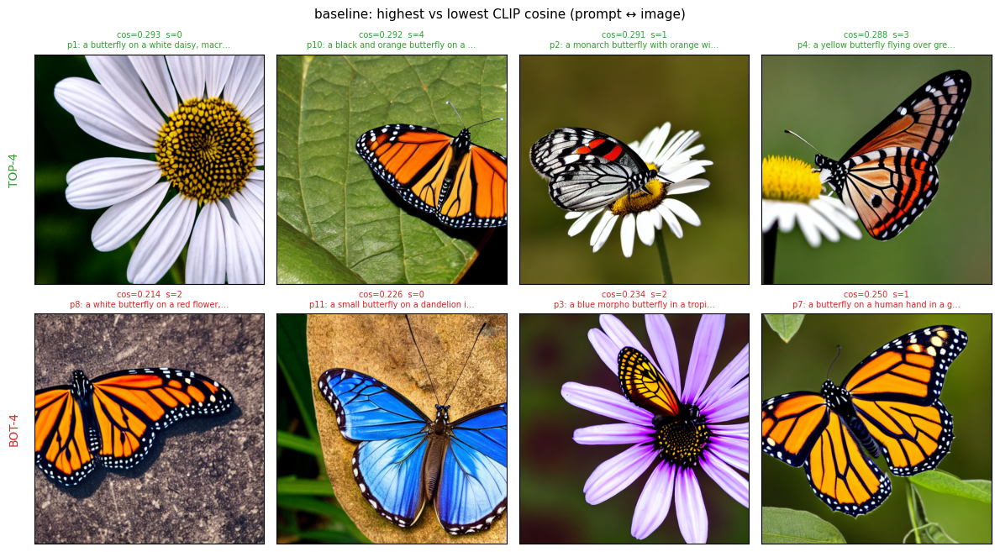

сохранено: /content/drive/MyDrive/lab13/artifacts/clip_features/baseline_top_bottom.png
baseline CLIP cosine по 12 картинкам: mean=0.2650, std=0.0268, min=0.2141, max=0.2932

=== r4_lr1e-4_step0400 ===
TOP:
  cos=0.293  s=0  p1  a butterfly on a white daisy, macro photography
  cos=0.292  s=4  p10  a black and orange butterfly on a sunflower
  cos=0.291  s=1  p2  a monarch butterfly with orange wings resting on a leaf
  cos=0.288  s=3  p4  a yellow butterfly flying over green grass
BOTTOM:
  cos=0.214  s=2  p8  a white butterfly on a red flower, natural light
  cos=0.226  s=0  p11  a small butterfly on a dandelion in spring
  cos=0.234  s=2  p3  a blue morpho butterfly in a tropical forest
  cos=0.250  s=1  p7  a butterfly on a human hand in a garden


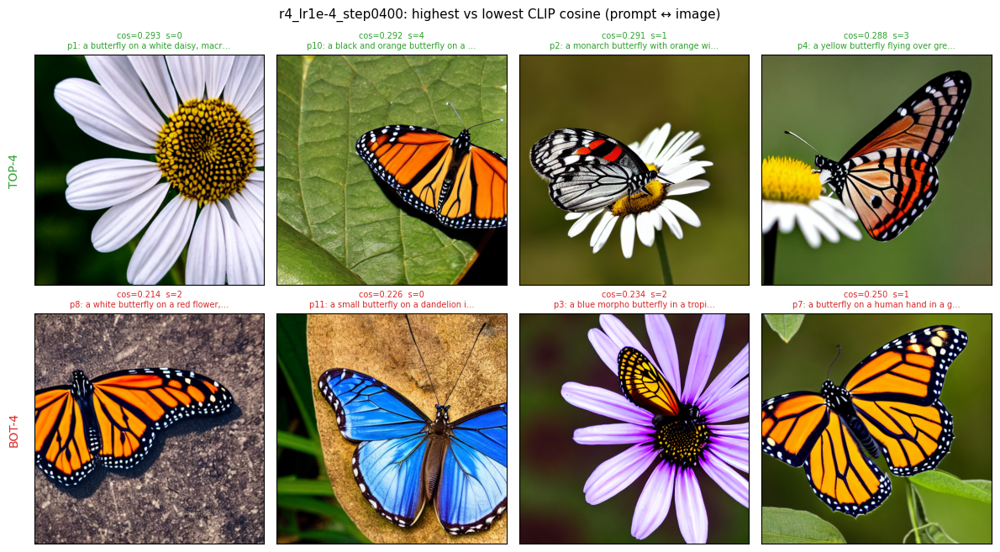

сохранено: /content/drive/MyDrive/lab13/artifacts/clip_features/r4_lr1e-4_step0400_top_bottom.png
r4_lr1e-4_step0400 CLIP cosine по 12 картинкам: mean=0.2650, std=0.0268, min=0.2141, max=0.2932

=== r8_lr1e-4_step0400 ===
TOP:
  cos=0.293  s=0  p1  a butterfly on a white daisy, macro photography
  cos=0.292  s=4  p10  a black and orange butterfly on a sunflower
  cos=0.291  s=1  p2  a monarch butterfly with orange wings resting on a leaf
  cos=0.288  s=3  p4  a yellow butterfly flying over green grass
BOTTOM:
  cos=0.214  s=2  p8  a white butterfly on a red flower, natural light
  cos=0.226  s=0  p11  a small butterfly on a dandelion in spring
  cos=0.234  s=2  p3  a blue morpho butterfly in a tropical forest
  cos=0.250  s=1  p7  a butterfly on a human hand in a garden


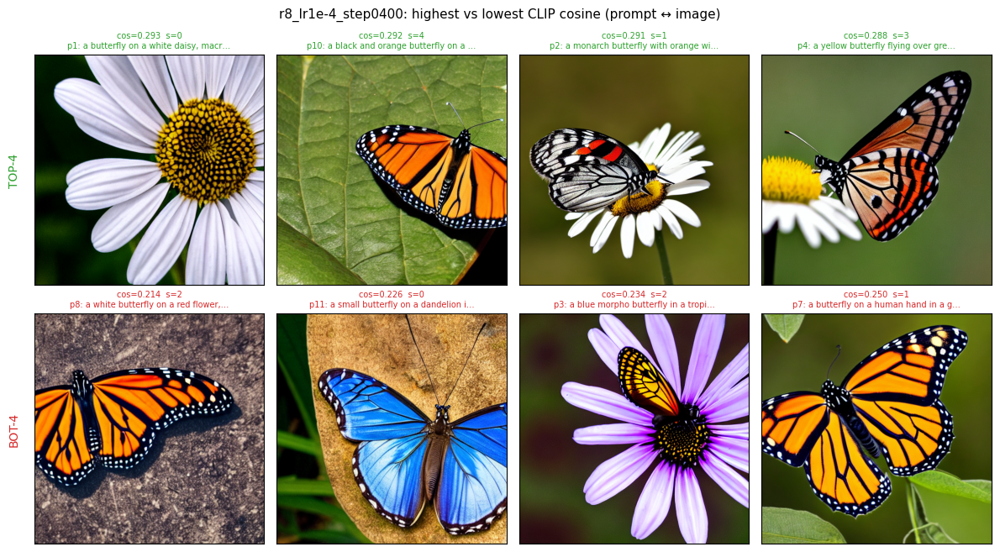

сохранено: /content/drive/MyDrive/lab13/artifacts/clip_features/r8_lr1e-4_step0400_top_bottom.png
r8_lr1e-4_step0400 CLIP cosine по 12 картинкам: mean=0.2650, std=0.0268, min=0.2141, max=0.2932

=== r8_lr5e-5_step0400 ===
TOP:
  cos=0.293  s=0  p1  a butterfly on a white daisy, macro photography
  cos=0.292  s=4  p10  a black and orange butterfly on a sunflower
  cos=0.291  s=1  p2  a monarch butterfly with orange wings resting on a leaf
  cos=0.288  s=3  p4  a yellow butterfly flying over green grass
BOTTOM:
  cos=0.214  s=2  p8  a white butterfly on a red flower, natural light
  cos=0.226  s=0  p11  a small butterfly on a dandelion in spring
  cos=0.234  s=2  p3  a blue morpho butterfly in a tropical forest
  cos=0.250  s=1  p7  a butterfly on a human hand in a garden


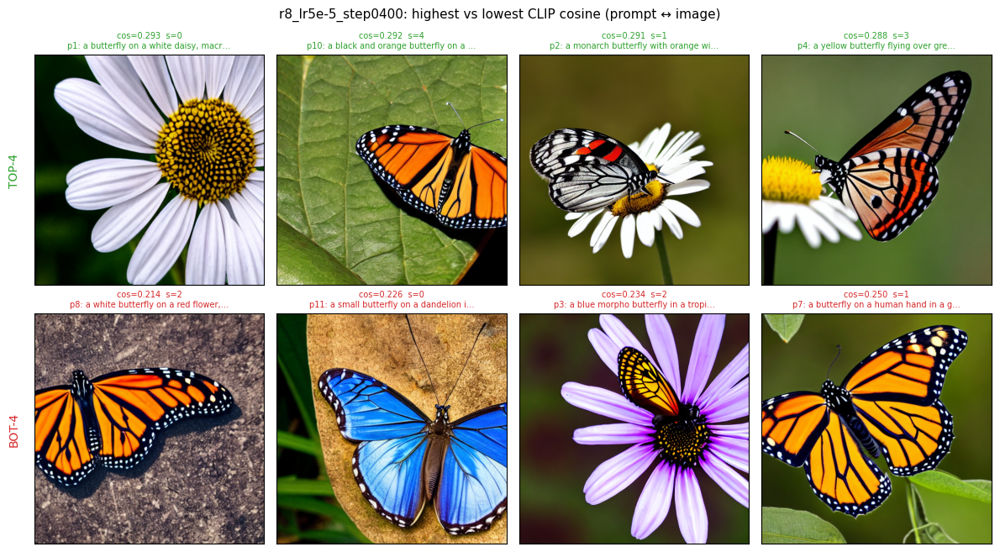

сохранено: /content/drive/MyDrive/lab13/artifacts/clip_features/r8_lr5e-5_step0400_top_bottom.png
r8_lr5e-5_step0400 CLIP cosine по 12 картинкам: mean=0.2650, std=0.0268, min=0.2141, max=0.2932

=== Сводка CLIP cosine ===
label                           n     mean      std      min      max
baseline                       12   0.2650   0.0268   0.2141   0.2932
r4_lr1e-4_step0400             12   0.2650   0.0268   0.2141   0.2932
r8_lr1e-4_step0400             12   0.2650   0.0268   0.2141   0.2932
r8_lr5e-5_step0400             12   0.2650   0.0268   0.2141   0.2932

сводка сохранена: /content/drive/MyDrive/lab13/artifacts/clip_features/top_bottom_summary.json


In [17]:
# ============================================================
# Top-4 / Bottom-4 по CLIP cosine для baseline и всех LoRA-наборов
# (один блок: цикл по всем наборам)
# ============================================================
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
CLIP_DIR    = ARTIFACTS / 'clip_features'

# --- собираем все наборы: baseline + lora_sets из clip_meta ---
meta = json.loads((CLIP_DIR / 'clip_meta.json').read_text(encoding='utf-8'))
prompts = meta['held_out_prompts']

# baseline
baseline_img_emb = torch.load(CLIP_DIR / 'baseline_image_emb.pt').to(held_text_emb.device)
baseline = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
baseline_results = baseline['results']

datasets = [{
    'label': 'baseline',
    'results': baseline_results,
    'img_emb': baseline_img_emb,
    'out_png': CLIP_DIR / 'baseline_top_bottom.png',
}]

# lora: по одному последнему чекпоинту на адаптер (из clip_meta['lora_sets'])
for key, info in meta.get('lora_sets', {}).items():
    emb_path = CLIP_DIR / f'{key}_image_emb.pt'
    if not emb_path.exists():
        print(f'WARN: нет {emb_path}, пропускаю {key}')
        continue
    gen_file = ARTIFACTS / 'lora_generations' / info['name'] / info['step'] / 'generations.json'
    if not gen_file.exists():
        print(f'WARN: нет {gen_file}, пропускаю {key}')
        continue
    results = json.loads(gen_file.read_text(encoding='utf-8'))['results']
    datasets.append({
        'label': key,
        'results': results,
        'img_emb': torch.load(emb_path).to(held_text_emb.device),
        'out_png': CLIP_DIR / f'{key}_top_bottom.png',
    })

print(f'наборов для визуализации: {len(datasets)}')
for d in datasets:
    print(f"  {d['label']:28s} n={len(d['results'])}")

# --- функция: top/bottom для одного набора ---
def top_bottom_plot(label, results, img_emb, out_png, K=4):
    pairs = []
    for j, r in enumerate(results):
        p_idx = r['index'] - 1
        if not (0 <= p_idx < len(prompts)):
            continue
        cos = float((held_text_emb[p_idx] @ img_emb[j]).item())
        pairs.append({'j': j, 'p_idx': p_idx, 'seed': r['seed'],
                      'prompt': prompts[p_idx], 'file_path': r['file_path'],
                      'cos': cos})
    if not pairs:
        print(f'{label}: нет пар, пропуск')
        return None

    pairs.sort(key=lambda x: x['cos'])
    k = min(K, len(pairs))
    low  = pairs[:k]
    high = pairs[-k:][::-1]

    print(f'\n=== {label} ===')
    print('TOP:')
    for x in high:
        print(f"  cos={x['cos']:.3f}  s={x['seed']}  p{x['p_idx']+1}  {x['prompt'][:60]}")
    print('BOTTOM:')
    for x in low:
        print(f"  cos={x['cos']:.3f}  s={x['seed']}  p{x['p_idx']+1}  {x['prompt'][:60]}")

    fig, axes = plt.subplots(2, k, figsize=(k * 3.0, 2 * 3.4))
    if k == 1:
        axes = axes.reshape(2, 1)

    def draw_row(ax_row, items, row_label, color):
        for col_i, x in enumerate(items):
            ax = ax_row[col_i]
            with Image.open(x['file_path']) as im:
                ax.imshow(im.convert('RGB'))
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f"cos={x['cos']:.3f}  s={x['seed']}\n"
                         f"p{x['p_idx']+1}: {x['prompt'][:34]}…",
                         fontsize=7, color=color)
        ax_row[0].set_ylabel(row_label, fontsize=10, color=color, labelpad=12)

    draw_row(axes[0], high, 'TOP-4', 'tab:green')
    draw_row(axes[1], low,  'BOT-4', 'tab:red')
    fig.suptitle(f'{label}: highest vs lowest CLIP cosine (prompt ↔ image)',
                 fontsize=11)
    plt.tight_layout()
    plt.savefig(out_png, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'сохранено: {out_png}')

    cos_all = np.array([x['cos'] for x in pairs])
    print(f'{label} CLIP cosine по {len(pairs)} картинкам: '
          f'mean={cos_all.mean():.4f}, std={cos_all.std():.4f}, '
          f'min={cos_all.min():.4f}, max={cos_all.max():.4f}')
    return {'label': label, 'n': len(pairs),
            'mean': float(cos_all.mean()), 'std': float(cos_all.std()),
            'min': float(cos_all.min()), 'max': float(cos_all.max()),
            'top': high, 'bottom': low}

# --- прогоняем по всем наборам ---
summaries = []
for d in datasets:
    s = top_bottom_plot(d['label'], d['results'], d['img_emb'], d['out_png'], K=4)
    if s is not None:
        summaries.append(s)

# --- общая сводка ---
print('\n=== Сводка CLIP cosine ===')
print(f"{'label':28s} {'n':>4s} {'mean':>8s} {'std':>8s} {'min':>8s} {'max':>8s}")
for s in summaries:
    print(f"{s['label']:28s} {s['n']:4d} {s['mean']:8.4f} {s['std']:8.4f} "
          f"{s['min']:8.4f} {s['max']:8.4f}")

(CLIP_DIR / 'top_bottom_summary.json').write_text(json.dumps({
    'prompts': prompts,
    'datasets': [{k: v for k, v in s.items() if k not in ('top', 'bottom')}
                 | {'top': s['top'], 'bottom': s['bottom']} for s in summaries],
}, ensure_ascii=False, indent=2))
print(f'\nсводка сохранена: {CLIP_DIR / "top_bottom_summary.json"}')

p1 бабочка на белой маргаритке, макросъемка

p10 черно-оранжевая бабочка на подсолнухе

p2 бабочка-монарх с оранжевыми крыльями, сидящая на листе

p4 желтая бабочка, летящая над землей. зеленая трава


p8 белая бабочка на красном цветке при естественном освещении

p11 маленькая бабочка на весеннем одуванчике

p3 голубая бабочка морфо в тропическом лесу

p7 бабочка на руке человека в саду

### Поиск ближайших обучающих изображений

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки.

**Результат.** Проверяемое состояние «Поиск ближайших обучающих изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки» и его результат доступен следующему этапу.

train image embeddings: (28, 512)  (0.4 c)

чекпоинтов для оценки: 4
  baseline                     n=60
  r4_lr1e-4_step0400           n=60
  r8_lr1e-4_step0400           n=60
  r8_lr5e-5_step0400           n=60

baseline                     nearest cos: mean=0.8608 max=0.9407  ≥0.8: 55  ≥0.9: 16

r4_lr1e-4_step0400           nearest cos: mean=0.8608 max=0.9407  ≥0.8: 55  ≥0.9: 16

r8_lr1e-4_step0400           nearest cos: mean=0.8608 max=0.9407  ≥0.8: 55  ≥0.9: 16

r8_lr5e-5_step0400           nearest cos: mean=0.8608 max=0.9407  ≥0.8: 55  ≥0.9: 16


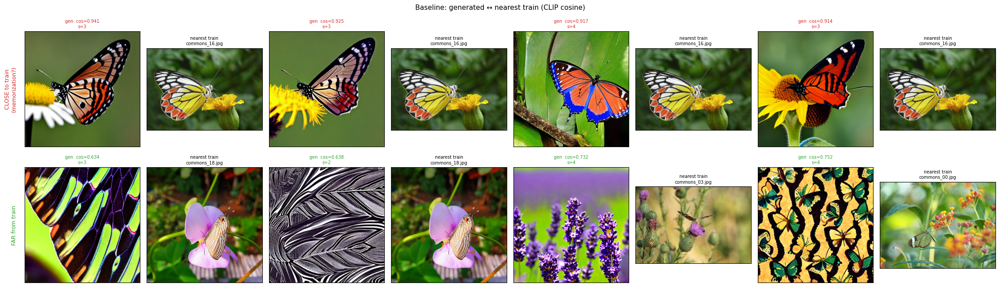


сохранено: /content/drive/MyDrive/lab13/artifacts/task7_nearest_train/baseline_nearest_train.png

--- Фактически измеренные значения (baseline) ---
train images:            28
generated images:        60
top-k:                   3
nearest cos mean ± std:  0.8608 ± 0.0578
nearest cos min / max:   0.6342 / 0.9407
n with cos >= 0.8:       55
n with cos >= 0.9:       16

checkpoints в наборе:    4  (['baseline', 'r4_lr1e-4_step0400', 'r8_lr1e-4_step0400', 'r8_lr5e-5_step0400'])
artifacts:
  /content/drive/MyDrive/lab13/artifacts/clip_features/nearest_train_baseline.json
  /content/drive/MyDrive/lab13/artifacts/clip_features/nearest_train_all.json
  /content/drive/MyDrive/lab13/artifacts/task7_eval_set.json
  /content/drive/MyDrive/lab13/artifacts/task7_nearest_train/baseline_nearest_train.png

errors:  0
ALL_OK:  True

OK: train-эмбеддинги и набор checkpoint зафиксированы.


In [18]:
from transformers import CLIPModel, CLIPProcessor

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE != 'cuda':
    raise RuntimeError('CLIP требует GPU.')

NEAREST_DIR = ARTIFACTS / 'task7_nearest_train'
NEAREST_DIR.mkdir(parents=True, exist_ok=True)
CLIP_DIR = ARTIFACTS / 'clip_features'
CLIP_MODEL_NAME = 'openai/clip-vit-base-patch32'
TOPK = 3

# --- 1. CLIP (если ещё не в памяти) ---
if 'clip_model' not in globals() or clip_model is None:
    clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE).eval()
    clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
    print(f'CLIP загружен: {CLIP_MODEL_NAME}, device={DEVICE}')

@torch.no_grad()
def encode_images(paths, batch_size=32):
    outs = []
    for i in range(0, len(paths), batch_size):
        chunk = paths[i:i+batch_size]
        imgs = [Image.open(p).convert('RGB') for p in chunk]
        inputs = clip_processor(images=imgs, return_tensors='pt')
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        feats = clip_model.get_image_features(**inputs)
        if not torch.is_tensor(feats):
            feats = feats.pooler_output
        outs.append(torch.nn.functional.normalize(feats, dim=-1))
    return torch.cat(outs, dim=0) if outs else torch.empty(0, 512, device=DEVICE)

# --- 2. train: эмбеддинги реальных изображений ---
train_imgs = json.loads((ARTIFACTS / 'task1_valid_images.json').read_text(encoding='utf-8'))
train_files = [v['file_path'] for v in train_imgs]
train_captions = [v['caption'] for v in train_imgs]

t0 = time.time()
train_img_emb = encode_images(train_files)          # [N_train, 512]
print(f'train image embeddings: {tuple(train_img_emb.shape)}  ({time.time()-t0:.1f} c)')

# сохраняем отдельно — это «зафиксированные» train-эмбеддинги для следующих этапов
torch.save(train_img_emb.cpu(), CLIP_DIR / 'train_image_emb_task7.pt')

# --- 3. фиксируем набор checkpoint для оценки ---
# baseline + все последние чекпоинты (по одному на адаптер), те же, что в task6
plan = json.loads((ARTIFACTS / 'task4_training_plan.json').read_text(encoding='utf-8'))
GEN_ROOT = ARTIFACTS / 'lora_generations'
meta = json.loads((CLIP_DIR / 'clip_meta.json').read_text(encoding='utf-8'))

baseline = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
baseline_results = baseline['results']
baseline_img_emb = torch.load(CLIP_DIR / 'baseline_image_emb.pt').to(DEVICE)

checkpoints = [{
    'key': 'baseline',
    'label': 'baseline (SD 1.5, no LoRA)',
    'adapter': None, 'step': None,
    'gen_results': baseline_results,
    'img_emb': baseline_img_emb,
}]

for cfg in plan['configs']:
    name = cfg['name']
    step_dirs = sorted((GEN_ROOT / name).glob('step*'))
    if not step_dirs:
        print(f'WARN: нет генераций для {name}, пропускаю')
        continue
    step_dir = step_dirs[-1]
    gen_file = step_dir / 'generations.json'
    if not gen_file.exists():
        print(f'WARN: нет {gen_file}, пропускаю')
        continue
    emb_path = CLIP_DIR / f'{name}_{step_dir.name}_image_emb.pt'
    if not emb_path.exists():
        print(f'WARN: нет {emb_path}, пропускаю')
        continue
    results = json.loads(gen_file.read_text(encoding='utf-8'))['results']
    checkpoints.append({
        'key': f'{name}_{step_dir.name}',
        'label': f'{name} @ {step_dir.name}',
        'adapter': name, 'step': step_dir.name,
        'gen_results': results,
        'img_emb': torch.load(emb_path).to(DEVICE),
    })

print(f'\nчекпоинтов для оценки: {len(checkpoints)}')
for c in checkpoints:
    print(f"  {c['key']:28s} n={len(c['gen_results'])}")

if len(checkpoints) < 2:
    print('WARN: только baseline — LoRA-чекпоинты ещё не сгенерированы/не посчитаны.')

# --- 4. поиск ближайших train для каждой сгенерированной картинки ---
def nearest_for_set(ckpt):
    emb = ckpt['img_emb']                     # [N_gen, 512]
    results = ckpt['gen_results']
    sims = emb @ train_img_emb.T              # [N_gen, N_train]
    topk_vals, topk_idx = sims.topk(TOPK, dim=-1)

    per_img = []
    for j, r in enumerate(results):
        p_idx = r['index'] - 1
        entry = {
            'gen_index': j,
            'gen_file': r['file_name'],
            'gen_path': r['file_path'],
            'prompt': r['prompt'],
            'prompt_idx': p_idx,
            'seed': r['seed'],
            'nearest': [
                {'rank': k + 1,
                 'train_file': train_imgs[int(topk_idx[j, k])]['file_name'],
                 'train_path': train_files[int(topk_idx[j, k])],
                 'train_caption': train_captions[int(topk_idx[j, k])],
                 'cos': float(topk_vals[j, k])}
                for k in range(TOPK)
            ],
            'nearest_cos': float(topk_vals[j, 0]),
        }
        per_img.append(entry)

    cos1 = np.array([e['nearest_cos'] for e in per_img])
    return per_img, {
        'key': ckpt['key'], 'label': ckpt['label'],
        'n_generated': len(per_img), 'n_train': len(train_files), 'topk': TOPK,
        'nearest_cos_mean': float(cos1.mean()),
        'nearest_cos_std': float(cos1.std()),
        'nearest_cos_min': float(cos1.min()),
        'nearest_cos_max': float(cos1.max()),
        'n_above_0_8': int((cos1 >= 0.8).sum()),
        'n_above_0_9': int((cos1 >= 0.9).sum()),
    }

nearest_all, summary = {}, []
for ck in checkpoints:
    per_img, stat = nearest_for_set(ck)
    nearest_all[ck['key']] = per_img
    summary.append(stat)
    print(f"\n{ck['key']:28s} nearest cos: mean={stat['nearest_cos_mean']:.4f} "
          f"max={stat['nearest_cos_max']:.4f}  "
          f"≥0.8: {stat['n_above_0_8']}  ≥0.9: {stat['n_above_0_9']}")

# --- 5. артефакты ---
(CLIP_DIR / 'nearest_train_baseline.json').write_text(json.dumps({
    'clip_model': CLIP_MODEL_NAME,
    'topk': TOPK,
    'train_files': train_files,
    'train_captions': train_captions,
    'per_image': nearest_all['baseline'],
    'summary': next(s for s in summary if s['key'] == 'baseline'),
}, ensure_ascii=False, indent=2))

(CLIP_DIR / 'nearest_train_all.json').write_text(json.dumps({
    'clip_model': CLIP_MODEL_NAME,
    'topk': TOPK,
    'train_files': train_files,
    'train_captions': train_captions,
    'checkpoints': [c['key'] for c in checkpoints],
    'per_image': nearest_all,
    'summary': summary,
}, ensure_ascii=False, indent=2))

# фиксируем список чекпоинтов — следующий этап читает именно его
eval_set = {
    'baseline': {'label': 'baseline (SD 1.5, no LoRA)',
                 'gen_json': str(ARTIFACTS / 'task3_baseline.json'),
                 'img_emb': str(CLIP_DIR / 'baseline_image_emb.pt'),
                 'n_images': len(baseline_results)},
    'lora': [{'key': c['key'], 'adapter': c['adapter'], 'step': c['step'],
              'gen_json': str(ARTIFACTS / 'lora_generations' / c['adapter'] / c['step'] / 'generations.json'),
              'img_emb': str(CLIP_DIR / f'{c["key"]}_image_emb.pt'),
              'n_images': len(c['gen_results'])}
             for c in checkpoints if c['key'] != 'baseline'],
    'train_image_emb': str(CLIP_DIR / 'train_image_emb_task7.pt'),
    'clip_model': CLIP_MODEL_NAME,
}
(ARTIFACTS / 'task7_eval_set.json').write_text(json.dumps(eval_set, ensure_ascii=False, indent=2))

# --- 6. визуализация: baseline, 4 самых «близких к train» и 4 самых «далёких» ---
base_per_img = nearest_all['baseline']
by_cos = sorted(base_per_img, key=lambda e: e['nearest_cos'])
K = min(4, len(by_cos))
low  = by_cos[:K]        # самые далёкие от train
high = by_cos[-K:][::-1] # самые близкие к train (подозрение на memorization)

fig, axes = plt.subplots(2, K * 2, figsize=(K * 2 * 2.8, 2 * 3.4))
if K == 1:
    axes = axes.reshape(2, 2)

def draw_pair(ax_gen, ax_train, e, row_label, color):
    with Image.open(e['gen_path']) as im:
        ax_gen.imshow(im.convert('RGB'))
    ax_gen.set_xticks([]); ax_gen.set_yticks([])
    ax_gen.set_title(f"gen  cos={e['nearest_cos']:.3f}\ns={e['seed']}",
                     fontsize=7, color=color)

    n = e['nearest'][0]
    with Image.open(n['train_path']) as im:
        ax_train.imshow(im.convert('RGB'))
    ax_train.set_xticks([]); ax_train.set_yticks([])
    ax_train.set_title(f"nearest train\n{n['train_file']}", fontsize=7)

for col_i in range(K):
    draw_pair(axes[0, col_i*2], axes[0, col_i*2+1], high[col_i], 'CLOSE', 'tab:red')
    draw_pair(axes[1, col_i*2], axes[1, col_i*2+1], low[col_i],  'FAR',   'tab:green')

axes[0, 0].set_ylabel('CLOSE to train\n(memorization?)', fontsize=9, color='tab:red', labelpad=12)
axes[1, 0].set_ylabel('FAR from train', fontsize=9, color='tab:green', labelpad=12)

fig.suptitle('Baseline: generated ↔ nearest train (CLIP cosine)', fontsize=11)
plt.tight_layout()
out_png = NEAREST_DIR / 'baseline_nearest_train.png'
plt.savefig(out_png, dpi=150, bbox_inches='tight')
plt.show()
print(f'\nсохранено: {out_png}')

# --- 7. измеренные значения ---
base_stat = next(s for s in summary if s['key'] == 'baseline')
print('\n--- Фактически измеренные значения (baseline) ---')
print(f'train images:            {len(train_files)}')
print(f'generated images:        {base_stat["n_generated"]}')
print(f'top-k:                   {TOPK}')
print(f'nearest cos mean ± std:  {base_stat["nearest_cos_mean"]:.4f} ± {base_stat["nearest_cos_std"]:.4f}')
print(f'nearest cos min / max:   {base_stat["nearest_cos_min"]:.4f} / {base_stat["nearest_cos_max"]:.4f}')
print(f'n with cos >= 0.8:       {base_stat["n_above_0_8"]}')
print(f'n with cos >= 0.9:       {base_stat["n_above_0_9"]}')
print(f'\ncheckpoints в наборе:    {len(checkpoints)}  ({[c["key"] for c in checkpoints]})')
print(f'artifacts:')
print(f'  {CLIP_DIR / "nearest_train_baseline.json"}')
print(f'  {CLIP_DIR / "nearest_train_all.json"}')
print(f'  {ARTIFACTS / "task7_eval_set.json"}')
print(f'  {out_png}')

# --- 8. проверки ---
errors = []
if train_img_emb.shape[0] != len(train_files):
    errors.append(f'train_img_emb: {train_img_emb.shape[0]} != {len(train_files)}')
if baseline_img_emb.shape[0] != len(baseline_results):
    errors.append(f'baseline_img_emb: {baseline_img_emb.shape[0]} != {len(baseline_results)}')
norms = train_img_emb.norm(dim=-1)
if not torch.allclose(norms, torch.ones_like(norms), atol=1e-4):
    errors.append('train_img_emb: not normalized')
for e in base_per_img:
    if len(e['nearest']) != TOPK:
        errors.append(f'{e["gen_file"]}: nearest != {TOPK}')
        break
    if not all(0 <= n['cos'] <= 1.0001 for n in e['nearest']):
        errors.append(f'{e["gen_file"]}: cos out of range')
        break

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
assert not errors, f'Проверка не пройдена: {errors[:5]}'
print('\nOK: train-эмбеддинги и набор checkpoint зафиксированы.')

### Парные генерации и измеримые показатели

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA.

**Результат.** Проверяемое состояние «Парные генерации и измеримые показатели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA» и его результат доступен следующему этапу.

  [baseline] prompt_idx восстановлен у 60 записей
  [r4_lr1e-4_step0400] prompt_idx восстановлен у 60 записей
  [r8_lr1e-4_step0400] prompt_idx восстановлен у 60 записей
  [r8_lr5e-5_step0400] prompt_idx восстановлен у 60 записей

наборов: 4
  baseline                     lora=False  n=60
  r4_lr1e-4_step0400           lora=True  n=60
  r8_lr1e-4_step0400           lora=True  n=60
  r8_lr5e-5_step0400           lora=True  n=60

пар (prompt_idx, seed): 60  — одинаковы во всех наборах
  baseline                     text=0.3251±0.0237  div=0.1011  nearest=0.8608 (max=0.941, ≥0.9: 16)
  r4_lr1e-4_step0400           text=0.3251±0.0237  div=0.1011  nearest=0.8608 (max=0.941, ≥0.9: 16)
  r8_lr1e-4_step0400           text=0.3251±0.0237  div=0.1011  nearest=0.8608 (max=0.941, ≥0.9: 16)
  r8_lr5e-5_step0400           text=0.3251±0.0237  div=0.1011  nearest=0.8608 (max=0.941, ≥0.9: 16)

посчитано за 0.2 c

train↔train background: mean=0.693, median=0.730, p90=0.821, max=0.890

--- Сводка (baselin

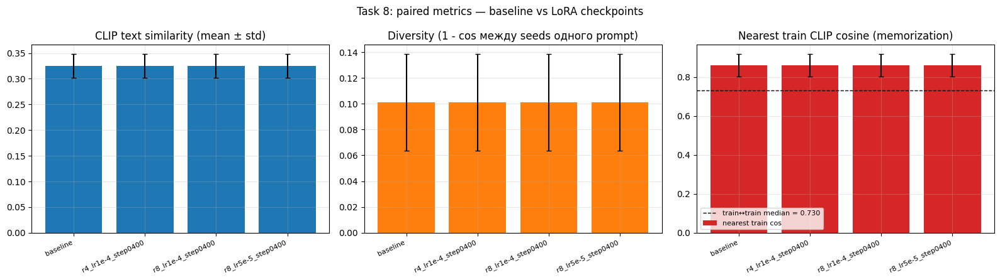

график сохранён: /content/drive/MyDrive/lab13/artifacts/task8_metrics/metrics_comparison.png

--- Фактически измеренные значения ---
CLIP:                    openai/clip-vit-base-patch32
наборов:                 4
baseline is LoRA:        False
пар (prompt_idx, seed):  60
text_sim baseline:       0.3251
diversity baseline:      0.1011
nearest baseline:        0.8608 (max=0.9407)
train↔train median:      0.7303
saved:
  /content/drive/MyDrive/lab13/artifacts/task8_metrics/metrics_all.json
  /content/drive/MyDrive/lab13/artifacts/task8_metrics/metrics_baseline.json
  /content/drive/MyDrive/lab13/artifacts/task8_metrics/metrics_comparison.png

errors:  0
ALL_OK:  True

OK: парные метрики сохранены, baseline чист (без LoRA).


In [ ]:
# ============================================================
# Парные генерации и измеримые показатели
# (без перегенерации: prompt_idx восстанавливается по prompt-строке)
# ============================================================
import json, time
from pathlib import Path

import torch
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'

METRICS_DIR = ARTIFACTS / 'task8_metrics'
METRICS_DIR.mkdir(parents=True, exist_ok=True)
CLIP_DIR = ARTIFACTS / 'clip_features'

# --- 1. эмбеддинги и метаданные ---
held_text_emb    = torch.load(CLIP_DIR / 'held_text_emb.pt').to(DEVICE)
train_img_emb    = torch.load(CLIP_DIR / 'train_image_emb_task7.pt').to(DEVICE)
baseline_img_emb = torch.load(CLIP_DIR / 'baseline_image_emb.pt').to(DEVICE)

meta = json.loads((CLIP_DIR / 'clip_meta.json').read_text(encoding='utf-8'))
prompts = meta['held_out_prompts']
n_prompts = len(prompts)
prompt_to_idx = {p: i for i, p in enumerate(prompts)}

train_files = [v['file_path'] for v in json.loads(
    (ARTIFACTS / 'task1_valid_images.json').read_text(encoding='utf-8'))]

eval_set = json.loads((ARTIFACTS / 'task7_eval_set.json').read_text(encoding='utf-8'))
baseline = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
baseline_results = baseline['results']

# --- 2. восстановление prompt_idx (без перегенерации) ---
def resolve_prompt_idx(r):
    """Вернуть 0-based prompt_idx для записи results.
    Приоритет: явный prompt_idx -> сопоставление по prompt-строке
    -> fallback на index-1 (если он в диапазоне)."""
    if 'prompt_idx' in r and isinstance(r['prompt_idx'], int):
        v = r['prompt_idx']
        if 0 <= v < n_prompts:
            return v
    p = r.get('prompt')
    if isinstance(p, str) and p in prompt_to_idx:
        return prompt_to_idx[p]
    idx = int(r.get('index', 0)) - 1
    return idx if 0 <= idx < n_prompts else None

# прогоним по baseline и всем LoRA, сложим prompt_idx в сами results
def attach_prompt_idx(results, source_label):
    fixed = 0
    for r in results:
        p_idx = resolve_prompt_idx(r)
        if p_idx is None:
            raise ValueError(f'{source_label}: не удалось определить prompt_idx для {r}')
        if r.get('prompt_idx') != p_idx:
            r['prompt_idx'] = p_idx
            fixed += 1
    if fixed:
        print(f'  [{source_label}] prompt_idx восстановлен у {fixed} записей')
    return results

baseline_results = attach_prompt_idx(baseline_results, 'baseline')

# --- 3. наборы: baseline + LoRA ---
datasets = [{
    'key': 'baseline',
    'label': 'baseline (SD 1.5, no LoRA)',
    'is_lora': False,
    'results': baseline_results,
    'img_emb': baseline_img_emb,
}]

for item in eval_set['lora']:
    key = item['key']
    emb_path = CLIP_DIR / f'{key}_image_emb.pt'
    gen_path = Path(item['gen_json'])
    if not emb_path.exists() or not gen_path.exists():
        print(f'WARN: пропускаю {key} (нет emb или gen json)')
        continue
    results = json.loads(gen_path.read_text(encoding='utf-8'))['results']
    results = attach_prompt_idx(results, key)
    datasets.append({
        'key': key, 'label': key, 'is_lora': True,
        'results': results,
        'img_emb': torch.load(emb_path).to(DEVICE),
    })

print(f'\nнаборов: {len(datasets)}')
for d in datasets:
    print(f"  {d['key']:28s} lora={d['is_lora']}  n={len(d['results'])}")

# --- 4. проверка: baseline без LoRA, парность ---
errors = []
if datasets[0]['is_lora']:
    errors.append('baseline помечен как LoRA')
if 'adapter' in baseline and baseline['adapter'] is not None:
    errors.append(f'baseline.json содержит adapter={baseline["adapter"]}')
for r in baseline_results:
    fp = str(r.get('file_path', '')).lower()
    fn = str(r.get('file_name', '')).lower()
    if 'lora' in fp or 'lora' in fn:
        errors.append(f'baseline: имя файла содержит lora: {r["file_name"]}')
        break

def pair_keys(results):
    return sorted((int(r['prompt_idx']), int(r['seed'])) for r in results)

base_keys = pair_keys(baseline_results)
for d in datasets[1:]:
    if pair_keys(d['results']) != base_keys:
        errors.append(f'{d["key"]}: пары (prompt_idx, seed) не совпадают с baseline')

if errors:
    print('\n!!! ОШИБКИ СРАЗУ:')
    for e in errors: print('  ', e)
    raise RuntimeError('Парность/чистота baseline нарушены — метрики несравнимы.')

print(f'\nпар (prompt_idx, seed): {len(base_keys)}  — одинаковы во всех наборах')

# --- 5. метрики ---
def compute_metrics(results, img_emb):
    n = len(results)
    p_idx_arr = np.array([int(r['prompt_idx']) for r in results])

    sims_text = np.array([
        float((held_text_emb[p_idx_arr[j]] @ img_emb[j]).item())
        for j in range(n)
    ])

    # diversity по промптам
    divs_per_prompt = {}
    for p in range(n_prompts):
        idxs = [j for j in range(n) if p_idx_arr[j] == p]
        if len(idxs) < 2:
            continue
        e = img_emb[idxs]
        s = e @ e.T
        m = s.shape[0]
        off = (s.sum() - s.diagonal().sum()) / (m * (m - 1))
        divs_per_prompt[p] = 1.0 - float(off)

    # nearest train
    sims_train = img_emb @ train_img_emb.T
    nearest_vals, nearest_idx = sims_train.max(dim=-1)

    per_prompt_sim = {}
    for p in range(n_prompts):
        vals = sims_text[p_idx_arr == p]
        if len(vals):
            per_prompt_sim[p] = float(vals.mean())

    return {
        'n_images': n,
        'text_sim': {
            'mean': float(sims_text.mean()),
            'std':  float(sims_text.std()),
            'median': float(np.median(sims_text)),
            'min': float(sims_text.min()),
            'max': float(sims_text.max()),
            'per_prompt': {f'p{p+1}': v for p, v in per_prompt_sim.items()},
        },
        'diversity': {
            'mean': float(np.mean(list(divs_per_prompt.values())))
                    if divs_per_prompt else float('nan'),
            'std':  float(np.std(list(divs_per_prompt.values())))
                    if divs_per_prompt else float('nan'),
            'per_prompt': {f'p{p+1}': v for p, v in divs_per_prompt.items()},
            'n_prompts': len(divs_per_prompt),
        },
        'nearest_train': {
            'mean': float(nearest_vals.mean()),
            'std':  float(nearest_vals.std()),
            'min':  float(nearest_vals.min()),
            'max':  float(nearest_vals.max()),
            'p90':  float(torch.quantile(nearest_vals, 0.9)),
            'n_ge_0_8': int((nearest_vals >= 0.8).sum()),
            'n_ge_0_9': int((nearest_vals >= 0.9).sum()),
            'per_image': [
                {'gen_file': results[j]['file_name'],
                 'prompt_idx': int(p_idx_arr[j]),
                 'seed': int(results[j]['seed']),
                 'nearest_cos': float(nearest_vals[j]),
                 'nearest_train_file': train_files[int(nearest_idx[j])]}
                for j in range(n)
            ],
        },
        'per_pair': [
            {'prompt_idx': int(p_idx_arr[j]), 'seed': int(results[j]['seed']),
             'gen_file': results[j]['file_name'],
             'text_sim': float(sims_text[j]),
             'nearest_train_cos': float(nearest_vals[j]),
             'nearest_train_file': train_files[int(nearest_idx[j])]}
            for j in range(n)
        ],
    }

# --- 6. считаем для всех наборов ---
t0 = time.time()
all_metrics = {}
for d in datasets:
    m = compute_metrics(d['results'], d['img_emb'])
    m['label'] = d['label']
    m['is_lora'] = d['is_lora']
    all_metrics[d['key']] = m
    print(f"  {d['key']:28s} "
          f"text={m['text_sim']['mean']:.4f}±{m['text_sim']['std']:.4f}  "
          f"div={m['diversity']['mean']:.4f}  "
          f"nearest={m['nearest_train']['mean']:.4f} "
          f"(max={m['nearest_train']['max']:.3f}, ≥0.9: {m['nearest_train']['n_ge_0_9']})")
print(f'\nпосчитано за {time.time()-t0:.1f} c')

# --- 7. train↔train фон ---
train_sim = train_img_emb @ train_img_emb.T
train_sim.fill_diagonal_(0)
train_background = {
    'mean':   float(train_sim.mean()),
    'median': float(train_sim.median()),
    'p90':    float(torch.quantile(train_sim.flatten(), 0.9)),
    'max':    float(train_sim.max()),
}
print(f"\ntrain↔train background: mean={train_background['mean']:.3f}, "
      f"median={train_background['median']:.3f}, "
      f"p90={train_background['p90']:.3f}, max={train_background['max']:.3f}")

# --- 8. артефакты ---
out = {
    'clip_model': eval_set['clip_model'],
    'prompts': prompts,
    'seeds': sorted({int(r['seed']) for r in baseline_results}),
    'n_pairs': len(base_keys),
    'baseline_is_lora': datasets[0]['is_lora'],
    'pairs_match_across_datasets': True,
    'train_background': train_background,
    'datasets': {k: {kk: vv for kk, vv in v.items() if kk != 'per_pair'}
                 for k, v in all_metrics.items()},
    'per_pair': {k: v['per_pair'] for k, v in all_metrics.items()},
}
(METRICS_DIR / 'metrics_all.json').write_text(json.dumps(out, ensure_ascii=False, indent=2))
(METRICS_DIR / 'metrics_baseline.json').write_text(json.dumps(
    {**all_metrics['baseline'], 'train_background': train_background},
    ensure_ascii=False, indent=2))

# --- 9. сводная таблица ---
print('\n--- Сводка (baseline + LoRA) ---')
print(f"{'dataset':28s} {'text_sim':>18s} {'diversity':>12s} {'nearest_train':>18s} {'≥0.9':>5s}")
for k, m in all_metrics.items():
    print(f"{k:28s} "
          f"{m['text_sim']['mean']:.4f}±{m['text_sim']['std']:.4f}   "
          f"{m['diversity']['mean']:>10.4f}   "
          f"{m['nearest_train']['mean']:.4f}±{m['nearest_train']['std']:.4f}   "
          f"{m['nearest_train']['n_ge_0_9']:5d}")

# --- 10. график ---
keys = list(all_metrics.keys())
x = np.arange(len(keys))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].bar(x, [all_metrics[k]['text_sim']['mean'] for k in keys],
            yerr=[all_metrics[k]['text_sim']['std'] for k in keys],
            color='tab:blue', capsize=3)
axes[0].set_title('CLIP text similarity (mean ± std)')
axes[0].set_xticks(x); axes[0].set_xticklabels(keys, rotation=25, ha='right', fontsize=8)
axes[0].grid(True, alpha=0.3); axes[0].axhline(0, color='k', lw=0.5)

axes[1].bar(x, [all_metrics[k]['diversity']['mean'] for k in keys],
            yerr=[all_metrics[k]['diversity']['std'] for k in keys],
            color='tab:orange', capsize=3)
axes[1].set_title('Diversity (1 - cos между seeds одного prompt)')
axes[1].set_xticks(x); axes[1].set_xticklabels(keys, rotation=25, ha='right', fontsize=8)
axes[1].grid(True, alpha=0.3); axes[1].axhline(0, color='k', lw=0.5)

axes[2].bar(x, [all_metrics[k]['nearest_train']['mean'] for k in keys],
            yerr=[all_metrics[k]['nearest_train']['std'] for k in keys],
            color='tab:red', capsize=3, label='nearest train cos')
axes[2].axhline(train_background['median'], color='k', ls='--', lw=1,
                label=f'train↔train median = {train_background["median"]:.3f}')
axes[2].set_title('Nearest train CLIP cosine (memorization)')
axes[2].set_xticks(x); axes[2].set_xticklabels(keys, rotation=25, ha='right', fontsize=8)
axes[2].grid(True, alpha=0.3); axes[2].legend(fontsize=8)

fig.suptitle('Task 8: paired metrics — baseline vs LoRA checkpoints', fontsize=12)
plt.tight_layout()
png_path = METRICS_DIR / 'metrics_comparison.png'
plt.savefig(png_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'график сохранён: {png_path}')

# --- 11. измеренные значения + проверки ---
print('\n--- Фактически измеренные значения ---')
print(f'CLIP:                    {eval_set["clip_model"]}')
print(f'наборов:                 {len(all_metrics)}')
print(f'baseline is LoRA:        {datasets[0]["is_lora"]}')
print(f'пар (prompt_idx, seed):  {len(base_keys)}')
print(f'text_sim baseline:       {all_metrics["baseline"]["text_sim"]["mean"]:.4f}')
print(f'diversity baseline:      {all_metrics["baseline"]["diversity"]["mean"]:.4f}')
print(f'nearest baseline:        {all_metrics["baseline"]["nearest_train"]["mean"]:.4f} '
      f'(max={all_metrics["baseline"]["nearest_train"]["max"]:.4f})')
print(f'train↔train median:      {train_background["median"]:.4f}')
print(f'saved:')
print(f'  {METRICS_DIR / "metrics_all.json"}')
print(f'  {METRICS_DIR / "metrics_baseline.json"}')
print(f'  {png_path}')

errors = []
if datasets[0]['is_lora']:
    errors.append('baseline помечен LoRA')
if baseline.get('adapter') is not None:
    errors.append('baseline adapter is not None')
for k, m in all_metrics.items():
    if not (0 <= m['text_sim']['mean'] <= 1):
        errors.append(f'{k}: text_sim out of [0,1]')
    if m['diversity']['mean'] < 0:
        errors.append(f'{k}: diversity < 0')
    if not (0 <= m['nearest_train']['mean'] <= 1):
        errors.append(f'{k}: nearest_train out of [0,1]')
    if len(m['per_pair']) != len(base_keys):
        errors.append(f'{k}: per_pair={len(m["per_pair"])} != {len(base_keys)}')

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
assert not errors, f'Проверка не пройдена: {errors[:5]}'
print('\nOK: парные метрики сохранены, baseline чист (без LoRA).')

### Слепая таблица оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов.

**Результат.** Проверяемое состояние «Слепая таблица оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов» и его результат доступен следующему этапу.

In [23]:
# ============================================================
# Слепая таблица оценки для реальных экспертов
# ============================================================
import json, random, shutil, csv
from pathlib import Path
from collections import defaultdict

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
SEED        = int(globals().get('SEED', 64))

BLIND_DIR = ARTIFACTS / 'task9_blind_eval'
BLIND_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. входы ---
eval_set = json.loads((ARTIFACTS / 'task7_eval_set.json').read_text(encoding='utf-8'))
baseline = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
held     = json.loads((ARTIFACTS / 'task2_held_out_prompts.json').read_text(encoding='utf-8'))
prompts  = held['prompts']
n_prompts = len(prompts)
prompt_to_idx = {p: i for i, p in enumerate(prompts)}

def resolve_prompt_idx(r):
    """0-based prompt_idx: явный prompt_idx -> prompt-строка -> index-1 (если в диапазоне)."""
    if 'prompt_idx' in r and isinstance(r['prompt_idx'], int):
        v = r['prompt_idx']
        if 0 <= v < n_prompts:
            return v
    p = r.get('prompt')
    if isinstance(p, str) and p in prompt_to_idx:
        return prompt_to_idx[p]
    idx = int(r.get('index', 0)) - 1
    return idx if 0 <= idx < n_prompts else None

def attach_prompt_idx(results, label):
    for r in results:
        p_idx = resolve_prompt_idx(r)
        if p_idx is None:
            raise ValueError(f'{label}: не удалось определить prompt_idx для {r}')
        r['prompt_idx'] = p_idx
    return results

# --- 2. собираем все картинки: baseline + LoRA ---
items = []

baseline_results = attach_prompt_idx(baseline['results'], 'baseline')
for r in baseline_results:
    items.append({
        'source': 'baseline',
        'source_label': 'baseline (SD 1.5, no LoRA)',
        'file_path': r['file_path'],
        'file_name': r['file_name'],
        'prompt_idx': r['prompt_idx'],
        'seed': int(r['seed']),
    })

for entry in eval_set['lora']:
    key = entry['key']
    gen_path = Path(entry['gen_json'])
    if not gen_path.exists():
        print(f'WARN: нет {gen_path}, пропускаю {key}')
        continue
    data = json.loads(gen_path.read_text(encoding='utf-8'))
    results = attach_prompt_idx(data['results'], key)
    for r in results:
        items.append({
            'source': key,
            'source_label': key,
            'file_path': r['file_path'],
            'file_name': r['file_name'],
            'prompt_idx': r['prompt_idx'],
            'seed': int(r['seed']),
        })

print(f'всего картинок: {len(items)}')
by_source = defaultdict(int)
for it in items: by_source[it['source']] += 1
for k, v in by_source.items(): print(f'  {k:28s} {v}')

# --- 3. перемешиваем (воспроизводимо) ---
rng = random.Random(SEED)
order = list(range(len(items)))
rng.shuffle(order)

# --- 4. копируем картинки под слепыми именами ---
img_dir = BLIND_DIR / 'images'
img_dir.mkdir(parents=True, exist_ok=True)

rows = []
for new_i, old_i in enumerate(order, 1):
    it = items[old_i]
    blind_id = f'img_{new_i:04d}'
    dst = img_dir / f'{blind_id}{Path(it["file_path"]).suffix}'
    if not dst.exists():
        shutil.copy2(it['file_path'], dst)
    rows.append({
        'blind_id': blind_id,
        'image_path': str(dst.relative_to(BLIND_DIR)),
        'prompt': prompts[it['prompt_idx']],
        'prompt_idx': it['prompt_idx'],
        'seed': it['seed'],
        '_source': it['source'],
        '_source_label': it['source_label'],
        '_original_file': it['file_name'],
    })

# --- 5. таблица для экспертов (без источника и без метрик) ---
headers = ['blind_id', 'image_path', 'prompt', 'seed',
           'score_quality_1_5', 'score_prompt_fit_1_5',
           'score_artifacts_1_5', 'comment']
with (BLIND_DIR / 'evaluation_sheet.csv').open('w', newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fieldnames=headers)
    w.writeheader()
    for r in rows:
        w.writerow({
            'blind_id': r['blind_id'],
            'image_path': r['image_path'],
            'prompt': r['prompt'],
            'seed': r['seed'],
            'score_quality_1_5': '',
            'score_prompt_fit_1_5': '',
            'score_artifacts_1_5': '',
            'comment': '',
        })

# --- 6. ключ (хранится отдельно, эксперту не показывать) ---
mapping = {}
for r in rows:
    mapping[r['blind_id']] = {
        'source': r['_source'],
        'source_label': r['_source_label'],
        'original_file': r['_original_file'],
        'prompt_idx': r['prompt_idx'],
        'seed': r['seed'],
    }
key = {
    'seed': SEED,
    'n_images': len(rows),
    'sources': sorted(by_source.keys()),
    'mapping': mapping,
}
(BLIND_DIR / 'blind_key.json').write_text(json.dumps(key, ensure_ascii=False, indent=2))

# --- 7. инструкция эксперту ---
instructions = """# Слепая оценка сгенерированных изображений

## Что оценивать
В папке `images/` — картинки, сгенерированные разными моделями по одним и тем же промптам.
Источник каждой картинки скрыт. Ваша задача — оценить её **по трём шкалам** от 1 до 5.

## Шкалы
1. **score_quality_1_5** — общее визуальное качество:
   1 = артефакты, нечитаемо; 3 = приемлемо; 5 = чисто, реалистично.
2. **score_prompt_fit_1_5** — соответствие промпту (см. колонку `prompt`):
   1 = совсем не про это; 3 = частично; 5 = точно про это.
3. **score_artifacts_1_5** — отсутствие артефактов:
   1 = сильные артефакты; 3 = мелкие; 5 = чисто.

## Как заполнять
Откройте `evaluation_sheet.csv`, для каждой строки впишите числа в три колонки
`score_*` и, по желанию, комментарий. Не меняйте `blind_id`, `image_path`, `prompt`.
Сохраните файл как `evaluation_sheet_filled.csv` в той же папке.

## Важно
- Не пытайтесь угадать, какая картинка от какой модели — оценивайте только то, что видите.
- Оценивайте все строки; пропуски снизят качество анализа.
- Промпт в колонке `prompt` — это то, по чему генерировалась картинка; сравнивайте с ним.
"""
(BLIND_DIR / 'README.md').write_text(instructions, encoding='utf-8')

# --- 8. проверки ---
errors = []
if len(rows) == 0:
    errors.append('нет картинок')

for r in rows:
    p = BLIND_DIR / r['image_path']
    if not p.exists():
        errors.append(f'{p} не существует')
        break

with (BLIND_DIR / 'evaluation_sheet.csv').open(encoding='utf-8') as f:
    reader = list(csv.DictReader(f))
if len(reader) != len(rows):
    errors.append(f'sheet rows {len(reader)} != {len(rows)}')
for row in reader:
    if any(row[k] != '' for k in ('score_quality_1_5', 'score_prompt_fit_1_5', 'score_artifacts_1_5')):
        errors.append('в sheet есть заполненные оценки (должны быть пустыми)')
        break

if set(key['mapping'].keys()) != {r['blind_id'] for r in rows}:
    errors.append('mapping не совпадает с blind_id')

sources_seq = [key['mapping'][f'img_{i:04d}']['source'] for i in range(1, len(rows) + 1)]
runs = sum(1 for a, b in zip(sources_seq, sources_seq[1:]) if a == b)
if runs > len(rows) * 0.6:
    errors.append(f'похоже, не перемешано: {runs} подряд идущих одинаковых источников')

# --- 9. измеренные значения ---
print('\n--- Фактически измеренные значения ---')
print(f'всего картинок:         {len(rows)}')
print(f'источников:             {len(by_source)}')
print(f'  ' + ', '.join(f'{k}={v}' for k, v in sorted(by_source.items())))
print(f'уникальных prompts:     {len({r["prompt_idx"] for r in rows})}')
print(f'уникальных seeds:       {len({r["seed"] for r in rows})}')
print(f'пар (prompt_idx, seed): {len({(r["prompt_idx"], r["seed"]) for r in rows})}')
print(f'\nфайлы:')
print(f'  {BLIND_DIR / "evaluation_sheet.csv"}   ({len(reader)} строк, оценки пустые)')
print(f'  {BLIND_DIR / "blind_key.json"}         (соответствие blind_id → источник)')
print(f'  {BLIND_DIR / "README.md"}              (инструкция эксперту)')
print(f'  {img_dir}/                            ({len(list(img_dir.glob("*")))} файлов)')

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
assert not errors, f'Проверка не пройдена: {errors[:5]}'
print('\nOK: слепая таблица готова к раздаче экспертам.')

всего картинок: 240
  baseline                     60
  r4_lr1e-4_step0400           60
  r8_lr1e-4_step0400           60
  r8_lr5e-5_step0400           60

--- Фактически измеренные значения ---
всего картинок:         240
источников:             4
  baseline=60, r4_lr1e-4_step0400=60, r8_lr1e-4_step0400=60, r8_lr5e-5_step0400=60
уникальных prompts:     12
уникальных seeds:       5
пар (prompt_idx, seed): 60

файлы:
  /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/evaluation_sheet.csv   (240 строк, оценки пустые)
  /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/blind_key.json         (соответствие blind_id → источник)
  /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/README.md              (инструкция эксперту)
  /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/images/                            (240 файлов)

errors:  0
ALL_OK:  True

OK: слепая таблица готова к раздаче экспертам.


заполненных таблиц: 1
  evaluation_sheet_filled.csv
файлов пропущено: 0
строк без полной оценки (в т.ч. нули): 180
валидных записей: 60

--- Экспертные оценки по источникам (mean ± std) ---
source                              quality     prompt_fit      artifacts
baseline                     4.95±0.22   4.57±0.64   4.60±0.66

--- CLIP-метрики vs экспертный prompt_fit ---
source                        CLIP text_sim  expert prompt_fit
baseline                              0.325               4.57


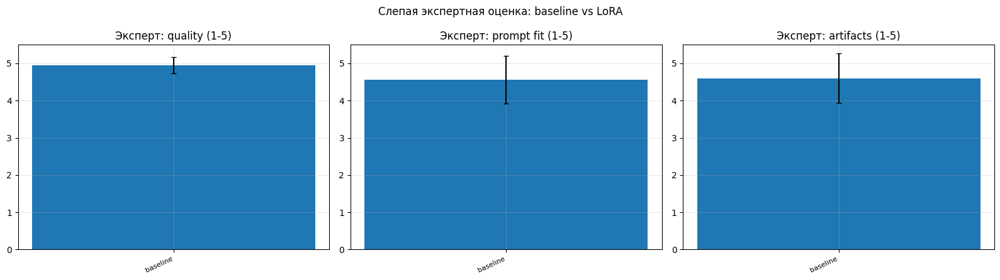


график сохранён: /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/blind_results.png


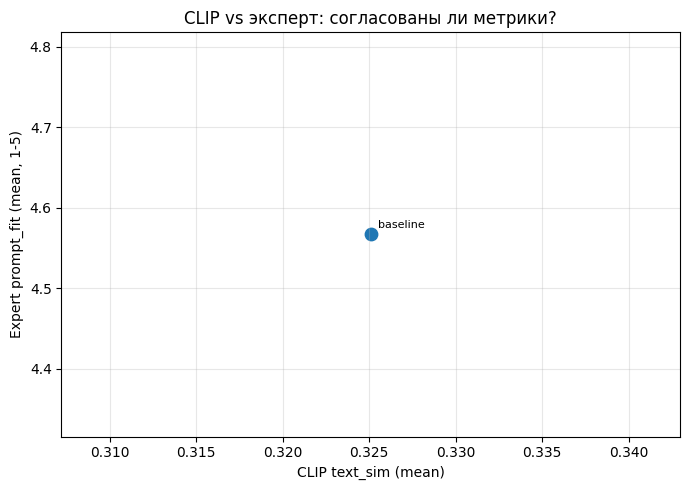

график сохранён: /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/clip_vs_expert.png

saved: /content/drive/MyDrive/lab13/artifacts/task9_blind_eval/blind_results.json


In [33]:
import csv, json
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/home/user/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
BLIND_DIR   = ARTIFACTS / 'task9_blind_eval'
METRICS_DIR = ARTIFACTS / 'task8_metrics'

# --- 1. ключ и заполненные таблицы ---
key = json.loads((BLIND_DIR / 'blind_key.json').read_text(encoding='utf-8'))['mapping']

filled_files = sorted(
    p for p in BLIND_DIR.glob('evaluation_sheet_filled*.csv')
    if not p.name.startswith('~$') and p.stat().st_size > 0      # FIX: отсечь временные/пустые
)
if not filled_files:
    raise FileNotFoundError(
        'Нет evaluation_sheet_filled*.csv. Эксперт должен сохранить '
        'заполненную таблицу в task9_blind_eval/.')

print(f'заполненных таблиц: {len(filled_files)}')
for f in filled_files: print(f'  {f.name}')

# --- 2. читаем и объединяем ---
SCALES = ['score_quality_1_5', 'score_prompt_fit_1_5', 'score_artifacts_1_5']
records = []   # (expert_id, blind_id, source, scales)
skipped_files, skipped_rows = [], 0                                # FIX: диагностика
for f in filled_files:
    expert = f.stem.replace('evaluation_sheet_filled', '').strip(' _()-') or 'expert1'  # FIX: нормализация имени
    with f.open(encoding='utf-8-sig', newline='') as fh:          # FIX: utf-8-sig + newline
        reader = csv.DictReader(fh)
        if 'blind_id' not in (reader.fieldnames or []):           # FIX: не падать с KeyError
            skipped_files.append((f.name, reader.fieldnames))
            continue
        for row in reader:
            bid = (row.get('blind_id') or '').strip()             # FIX: .get
            if not bid or bid not in key:
                continue
            scores = {}
            missing = []
            for s in SCALES:
                v = (row.get(s) or '').strip()
                try:
                    iv = int(v)
                except ValueError:
                    missing.append(s); continue
                if not (1 <= iv <= 5):                            # FIX: 0 = «не оценено» -> пропуск
                    missing.append(s); continue
                scores[s] = iv
            if missing:
                skipped_rows += 1                                 # FIX: счётчик пропусков
                continue
            info = key[bid]
            source = info['source'] if isinstance(info, dict) else info  # FIX: устойчиво к формату key
            records.append({
                'expert': expert, 'blind_id': bid,
                'source': source,
                **scores,
            })

print(f'файлов пропущено: {len(skipped_files)}')
for name, fields in skipped_files:
    print(f'  {name}: поля={fields}')
print(f'строк без полной оценки (в т.ч. нули): {skipped_rows}')
print(f'валидных записей: {len(records)}')

if not records:
    raise RuntimeError('Не удалось прочитать ни одной полной оценки.')

# --- 3. по источникам: mean ± std по каждой шкале ---
by_source = defaultdict(lambda: defaultdict(list))
by_expert_source = defaultdict(lambda: defaultdict(list))
for r in records:
    for s in SCALES:
        by_source[r['source']][s].append(r[s])
        by_expert_source[(r['expert'], r['source'])][s].append(r[s])

summary = {}
for src, sc in by_source.items():
    summary[src] = {
        s: {'mean': float(np.mean(v)), 'std': float(np.std(v)), 'n': len(v)}
        for s, v in sc.items()
    }

# --- 4. согласие между экспертами (если ≥2) ---
experts = sorted({r['expert'] for r in records})
agreement = None
if len(experts) >= 2:
    from scipy.stats import spearmanr
    pairs = []
    for i in range(len(experts)):
        for j in range(i + 1, len(experts)):
            e1, e2 = experts[i], experts[j]
            m1 = {r['blind_id']: r['score_prompt_fit_1_5'] for r in records if r['expert'] == e1}
            m2 = {r['blind_id']: r['score_prompt_fit_1_5'] for r in records if r['expert'] == e2}
            common = sorted(set(m1) & set(m2))
            if len(common) < 5: continue
            if len({m1[b] for b in common}) < 2 or len({m2[b] for b in common}) < 2:  # FIX: константа -> nan
                continue
            rho, _ = spearmanr([m1[b] for b in common], [m2[b] for b in common])
            pairs.append({'expert_a': e1, 'expert_b': e2, 'n': len(common), 'spearman': float(rho)})
    agreement = pairs

# --- 5. сравниваем с CLIP-метриками ---
clip_metrics = {}
mp = METRICS_DIR / 'metrics_all.json'
if mp.exists():
    data = json.loads(mp.read_text(encoding='utf-8'))
    for src, m in data['datasets'].items():
        clip_metrics[src] = {
            'text_sim': m['text_sim']['mean'],
            'diversity': m['diversity']['mean'],
            'nearest_train': m['nearest_train']['mean'],
        }

# --- 6. сохраняем ---
out = {
    'n_records': len(records),
    'experts': experts,
    'scales': SCALES,
    'by_source': summary,
    'by_expert_source': {f'{e}|{s}': {k: {'mean': float(np.mean(v)), 'n': len(v)}
                                       for k, v in sc.items()}
                         for (e, s), sc in by_expert_source.items()},
    'agreement': agreement,
    'clip_metrics': clip_metrics,
}
(BLIND_DIR / 'blind_results.json').write_text(json.dumps(out, ensure_ascii=False, indent=2))

# --- 7. печать ---
print('\n--- Экспертные оценки по источникам (mean ± std) ---')
print(f"{'source':28s} {'quality':>14s} {'prompt_fit':>14s} {'artifacts':>14s}")
for src in sorted(summary):
    s = summary[src]
    print(f"{src:28s} "
          f"{s['score_quality_1_5']['mean']:.2f}±{s['score_quality_1_5']['std']:.2f}   "
          f"{s['score_prompt_fit_1_5']['mean']:.2f}±{s['score_prompt_fit_1_5']['std']:.2f}   "
          f"{s['score_artifacts_1_5']['mean']:.2f}±{s['score_artifacts_1_5']['std']:.2f}")

if agreement:
    print('\n--- Согласие между экспертами (Spearman по prompt_fit) ---')
    for p in agreement:
        print(f"  {p['expert_a']} ↔ {p['expert_b']}: rho={p['spearman']:.3f} (n={p['n']})")

if clip_metrics:
    print('\n--- CLIP-метрики vs экспертный prompt_fit ---')
    print(f"{'source':28s} {'CLIP text_sim':>14s} {'expert prompt_fit':>18s}")
    for src in sorted(summary):
        c = clip_metrics.get(src, {}).get('text_sim', float('nan'))
        e = summary[src]['score_prompt_fit_1_5']['mean']
        print(f"{src:28s} {c:>14.3f} {e:>18.2f}")

# --- 8. графики ---
sources = sorted(summary)
x = np.arange(len(sources))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, scale, title in zip(
    axes,
    SCALES,
    ['Эксперт: quality (1-5)', 'Эксперт: prompt fit (1-5)', 'Эксперт: artifacts (1-5)']
):
    means = [summary[s][scale]['mean'] for s in sources]
    stds  = [summary[s][scale]['std'] for s in sources]
    ax.bar(x, means, yerr=stds, capsize=3, color='tab:blue')
    ax.set_xticks(x); ax.set_xticklabels(sources, rotation=25, ha='right', fontsize=8)
    ax.set_title(title); ax.set_ylim(0, 5.5); ax.grid(True, alpha=0.3)

fig.suptitle('Слепая экспертная оценка: baseline vs LoRA', fontsize=12)
plt.tight_layout()
png = BLIND_DIR / 'blind_results.png'
plt.savefig(png, dpi=150, bbox_inches='tight')
plt.show()
print(f'\nграфик сохранён: {png}')

# scatter: CLIP vs эксперт
if clip_metrics:
    xs, ys, labels = [], [], []
    for s in sources:
        c = clip_metrics.get(s, {}).get('text_sim')
        if c is None: continue
        xs.append(c); ys.append(summary[s]['score_prompt_fit_1_5']['mean']); labels.append(s)
    fig2, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(xs, ys, s=80)
    for xi, yi, lab in zip(xs, ys, labels):
        ax.annotate(lab, (xi, yi), fontsize=8, xytext=(5, 5), textcoords='offset points')
    ax.set_xlabel('CLIP text_sim (mean)')
    ax.set_ylabel('Expert prompt_fit (mean, 1-5)')
    ax.set_title('CLIP vs эксперт: согласованы ли метрики?')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    png2 = BLIND_DIR / 'clip_vs_expert.png'
    plt.savefig(png2, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'график сохранён: {png2}')

print(f'\nsaved: {BLIND_DIR / "blind_results.json"}')

In [31]:
import csv
csv_path = BLIND_DIR / "evaluation_sheet_filled.csv"

with open(csv_path, "r", encoding="utf-8-sig", newline="") as fh:
    sample = fh.read(4096)
    fh.seek(0)
    try:
        dialect = csv.Sniffer().sniff(sample, delimiters=",;\t")
        print("Разделитель:", repr(dialect.delimiter))
    except csv.Error:
        dialect = csv.excel
        print("Sniffer не сработал, беру запятую")

    reader = csv.DictReader(fh, dialect=dialect)
    print("Поля:", reader.fieldnames)
    first = next(reader, None)
    print("Первая строка:", first)

Разделитель: ','
Поля: ['blind_id', 'image_path', 'prompt', 'seed', 'score_quality_1_5', 'score_prompt_fit_1_5', 'score_artifacts_1_5', 'comment']
Первая строка: {'blind_id': 'img_0001', 'image_path': 'images/img_0001.png', 'prompt': 'a close-up of a butterfly wing pattern', 'seed': '4', 'score_quality_1_5': '0', 'score_prompt_fit_1_5': '0', 'score_artifacts_1_5': '0', 'comment': ''}


/tmp/ipykernel_711/1965669249.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(text_vals, labels=labels_short, showmeans=True)
/tmp/ipykernel_711/1965669249.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(div_vals, labels=labels_short, showmeans=True)
/tmp/ipykernel_711/1965669249.py:49: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot(near_vals, labels=labels_short, showmeans=True)


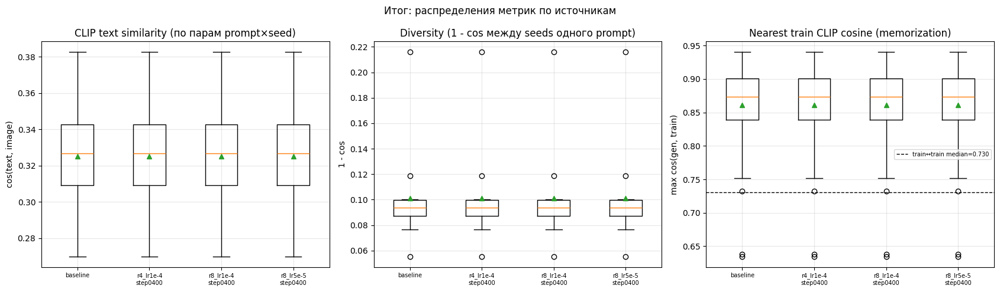

saved: /content/drive/MyDrive/lab13/artifacts/task8_metrics/final_boxplots.png


In [34]:
# ============================================================
# Итоговая визуализация: boxplots по трём метрикам
# ============================================================
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/home/user/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
METRICS_DIR = ARTIFACTS / 'task8_metrics'

# --- 1. загружаем метрики ---
m_all = json.loads((METRICS_DIR / 'metrics_all.json').read_text(encoding='utf-8'))
datasets = m_all['datasets']
per_pair = m_all.get('per_pair', {})
train_bg = m_all.get('train_background', {})

keys = list(datasets.keys())
if 'baseline' in keys:
    keys = ['baseline'] + [k for k in keys if k != 'baseline']
labels_short = [k.replace('_step', '\nstep') for k in keys]

# --- 2. данные по каждой метрике ---
def per_pair_values(key, field):
    return [p[field] for p in per_pair.get(key, []) if field in p]

text_vals = [per_pair_values(k, 'text_sim')          for k in keys]
near_vals = [per_pair_values(k, 'nearest_train_cos') for k in keys]
div_vals  = [list(datasets[k]['diversity'].get('per_prompt', {}).values())
             for k in keys]

# --- 3. boxplots ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].boxplot(text_vals, labels=labels_short, showmeans=True)
axes[0].set_title('CLIP text similarity (по парам prompt×seed)')
axes[0].set_ylabel('cos(text, image)')
axes[0].grid(True, alpha=0.3)
axes[0].tick_params(axis='x', labelsize=7)

axes[1].boxplot(div_vals, labels=labels_short, showmeans=True)
axes[1].set_title('Diversity (1 - cos между seeds одного prompt)')
axes[1].set_ylabel('1 - cos')
axes[1].grid(True, alpha=0.3)
axes[1].tick_params(axis='x', labelsize=7)

axes[2].boxplot(near_vals, labels=labels_short, showmeans=True)
if 'median' in train_bg:
    axes[2].axhline(train_bg['median'], color='k', ls='--', lw=1,
                    label=f"train↔train median={train_bg['median']:.3f}")
    axes[2].legend(fontsize=7)
axes[2].set_title('Nearest train CLIP cosine (memorization)')
axes[2].set_ylabel('max cos(gen, train)')
axes[2].grid(True, alpha=0.3)
axes[2].tick_params(axis='x', labelsize=7)

fig.suptitle('Итог: распределения метрик по источникам', fontsize=12)
plt.tight_layout()
out_png = METRICS_DIR / 'final_boxplots.png'
plt.savefig(out_png, dpi=150, bbox_inches='tight')
plt.show()
print(f'saved: {out_png}')

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

базовая конфигурация: rank=4, lr=0.0001, steps=400
train: 28 изображений, у каждого — 2 caption (good/bad)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[ablation F] step 1/400  loss=0.2045
[ablation F] step 50/400  loss=0.0530
[ablation F] step 100/400  loss=0.1846
[ablation F] step 150/400  loss=0.3024
[ablation F] step 200/400  loss=0.0117
[ablation F] step 250/400  loss=0.0782
[ablation F] step 300/400  loss=0.5198
[ablation F] step 350/400  loss=0.0033
[ablation F] step 400/400  loss=0.0359
обучение: 180.1 c, n_trainable=797,184, final_loss=0.0359


No LoRA keys associated to UNet2DConditionModel found with the prefix='unet'. This is safe to ignore if LoRA state dict didn't originally have any UNet2DConditionModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


сгенерировано: 60 за 343.6 c


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

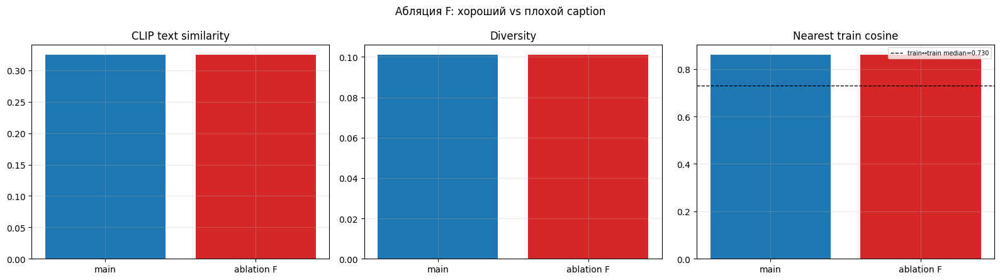


--- Абляция F: измеренные значения ---
rank=4  lr=0.0001  steps=400  n_images=60
text_sim        : 0.3251 ± 0.0237
diversity       : 0.1011 ± 0.0376
nearest_train   : 0.8608 (max=0.9407, ≥0.9: 16)

--- Сравнение с основным (r4_lr1e-4_step0400) ---
text_sim      : main=0.3251  abl=0.3251  Δ=+0.0000
diversity     : main=0.1011  abl=0.1011  Δ=+0.0000
nearest_train : main=0.8608  abl=0.8608  Δ=+0.0000

train↔train median: 0.7303

--- Интерпретация ---
Гипотеза: подмешивание неверных captions заставит LoRA игнорировать текст.
  • изменения в пределах шума — гипотеза не подтвердилась
  • nearest_train=0.861 vs train↔train median=0.730: выше фона — возможна memorization

saved to: /content/drive/MyDrive/lab13/artifacts/bonus_ablation_F
  lora/, loss_history.json, generations/, generations.json, comparison.json, ablation_F_comparison.png


In [37]:
# ============================================================
# Бонус. Абляция F: «плохой» vs «хороший» caption
# Гипотеза (до эксперимента): если в train captions подмешать
# намеренно неверные описания (50/50), LoRA перестанет полагаться
# на текст и будет опираться на визуальный сигнал.
# Ожидаем: text_sim ↓↓, diversity ↑, nearest_train ↑
# (по сравнению с основным экспериментом при том же rank/LR).
# ============================================================
PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/home/user/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
DATA_ROOT   = Path(globals().get('DATA_ROOT',   PROJECT_DIR / 'data'))
SEED        = int(globals().get('SEED', 64))
DEVICE      = 'cuda' if torch.cuda.is_available() else 'cpu'
FAST_DEV_RUN = bool(globals().get('FAST_DEV_RUN', True))

if DEVICE != 'cuda':
    raise RuntimeError('Абляция требует GPU.')

ABL_DIR = ARTIFACTS / 'bonus_ablation_F'
ABL_DIR.mkdir(parents=True, exist_ok=True)

# --- 0. какой rank/LR взять за базу сравнения (совпадает с основным) ---
plan = json.loads((ARTIFACTS / 'task4_training_plan.json').read_text(encoding='utf-8'))
SCHEDULE = dict(plan['schedule'])
SCHEDULE['max_train_steps'] = 1 if FAST_DEV_RUN else SCHEDULE['max_train_steps']
SCHEDULE['checkpoint_steps'] = [SCHEDULE['max_train_steps']]
BASE_CFG = next(c for c in plan['configs'] if c['name'] == 'r4_lr1e-4')
RANK, LR = BASE_CFG['rank'], BASE_CFG['lr']
TARGET_MODULES = plan['target_modules']
BASE_MODEL = plan['base_model']
print(f'базовая конфигурация: rank={RANK}, lr={LR}, steps={SCHEDULE["max_train_steps"]}')

# --- 1. данные: train + «плохие» captions ---
train_imgs = json.loads((ARTIFACTS / 'task1_valid_images.json').read_text(encoding='utf-8'))
held = json.loads((ARTIFACTS / 'task2_held_out_prompts.json').read_text(encoding='utf-8'))
prompts, seeds = held['prompts'], held['seeds']

# «плохие» captions: намеренно неверные описания (не бабочка)
# для каждого train-изображения детерминированно по индексу
BAD_POOL = [
    'a photo of a bird on a branch',
    'a photo of a red car on a road',
    'a photo of a cat sitting on a sofa',
    'a photo of a mountain landscape at sunset',
    'a photo of a wooden chair in a room',
    'a photo of a pizza on a plate',
]
def bad_caption(i):
    return BAD_POOL[i % len(BAD_POOL)]

train_items = []
for i, v in enumerate(train_imgs):
    train_items.append({
        'file_path': v['file_path'],
        'good_caption': v['caption'],
        'bad_caption': bad_caption(i),
    })
print(f'train: {len(train_items)} изображений, у каждого — 2 caption (good/bad)')

# --- 2. датасет: на каждой итерации случайно good или bad ---
class AblationDataset(Dataset):
    def __init__(self, items, resolution, tokenizer, p_bad=0.5, seed=SEED):
        self.items, self.tokenizer = items, tokenizer
        self.p_bad = p_bad
        self.rng = random.Random(seed)
        self.tf = transforms.Compose([
            transforms.Resize(resolution, interpolation=transforms.InterpolationMode.BILINEAR),
            transforms.CenterCrop(resolution),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        it = self.items[i]
        img = Image.open(it['file_path']).convert('RGB')
        px = self.tf(img)
        caption = it['bad_caption'] if self.rng.random() < self.p_bad else it['good_caption']
        tok = self.tokenizer(caption, padding='max_length', max_length=77,
                             truncation=True, return_tensors='pt')
        return {'pixel_values': px, 'input_ids': tok.input_ids[0],
                'attention_mask': tok.attention_mask[0], 'caption': caption}

# --- 3. базовая модель ---
pipe = StableDiffusionPipeline.from_pretrained(
    BASE_MODEL, torch_dtype=torch.float16,
    safety_checker=None, requires_safety_checker=False,
).to(DEVICE)
pipe.vae.requires_grad_(False); pipe.text_encoder.requires_grad_(False)
pipe.unet.requires_grad_(False); pipe.vae.eval(); pipe.text_encoder.eval()

@torch.no_grad()
def encode_batch(batch):
    px = batch['pixel_values'].to(DEVICE, dtype=torch.float16)
    lat = pipe.vae.encode(px).latent_dist.sample() * pipe.vae.config.scaling_factor
    txt = pipe.text_encoder(batch['input_ids'].to(DEVICE))[0]
    return lat, txt

# --- 4. LoRA + обучение ---
torch.manual_seed(SEED)
unet = copy.deepcopy(pipe.unet); unet.requires_grad_(False)
peft_unet = get_peft_model(unet, LoraConfig(
    r=RANK, lora_alpha=RANK, target_modules=TARGET_MODULES,
    lora_dropout=0.0, bias='none', init_lora_weights='gaussian'))
peft_unet.train()

trainable = [p for p in peft_unet.parameters() if p.requires_grad]
n_trainable = sum(p.numel() for p in trainable)

opt = torch.optim.AdamW(trainable, lr=LR,
                        betas=(SCHEDULE['adam_beta1'], SCHEDULE['adam_beta2']),
                        weight_decay=SCHEDULE['adam_weight_decay'],
                        eps=SCHEDULE['adam_epsilon'])
scaler = torch.amp.GradScaler('cuda') if SCHEDULE['mixed_precision'] == 'fp16' else None

ds = AblationDataset(train_items, SCHEDULE['resolution'], pipe.tokenizer, p_bad=0.5, seed=SEED)
loader = DataLoader(ds, batch_size=SCHEDULE['batch_size'], shuffle=True,
                    generator=torch.Generator().manual_seed(SEED),
                    drop_last=True, num_workers=0, pin_memory=True)
noise_sched = DDPMScheduler.from_config(pipe.scheduler.config)
max_steps = SCHEDULE['max_train_steps']

step, t0 = 0, time.time()
loss_hist = []
while step < max_steps:
    for batch in loader:
        with torch.no_grad():
            lat, txt = encode_batch(batch)
        noise = torch.randn_like(lat)
        ts = torch.randint(0, noise_sched.config.num_train_timesteps,
                           (lat.shape[0],), device=DEVICE, dtype=torch.long)
        noisy = noise_sched.add_noise(lat, noise, ts)
        with torch.autocast('cuda', dtype=torch.float16, enabled=(scaler is not None)):
            pred = peft_unet(noisy, ts, encoder_hidden_states=txt).sample
            loss = F.mse_loss(pred.float(), noise.float())
        if scaler: scaler.scale(loss).backward()
        else: loss.backward()
        step += 1
        if scaler:
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(trainable, SCHEDULE['max_grad_norm'])
            scaler.step(opt); scaler.update()
        else:
            torch.nn.utils.clip_grad_norm_(trainable, SCHEDULE['max_grad_norm'])
            opt.step()
        opt.zero_grad(set_to_none=True)
        loss_hist.append(float(loss.detach()))
        if step % 50 == 0 or step == 1:
            print(f'[ablation F] step {step}/{max_steps}  loss={float(loss):.4f}')
        if step >= max_steps:
            break
train_dt = time.time() - t0
print(f'обучение: {train_dt:.1f} c, n_trainable={n_trainable:,}, final_loss={loss_hist[-1]:.4f}')

# сохраняем LoRA и history
lora_dir = ABL_DIR / 'lora'; lora_dir.mkdir(exist_ok=True)
peft_unet.save_pretrained(lora_dir)
(ABL_DIR / 'loss_history.json').write_text(json.dumps(
    {'steps': list(range(1, len(loss_hist)+1)), 'loss': loss_hist,
     'rank': RANK, 'learning_rate_initial': LR}, ensure_ascii=False, indent=2))

# --- 5. генерация по held-out ---
GEN_KWARGS = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))['inference_protocol']
pairs = ([{'prompt': prompts[0], 'seed': seeds[0]},
          {'prompt': prompts[1], 'seed': seeds[0]}]
         if FAST_DEV_RUN else held['pairs'])

del peft_unet
torch.cuda.empty_cache()
pipe.unload_lora_weights() if hasattr(pipe, 'unload_lora_weights') else None
pipe.load_lora_weights(str(lora_dir))
pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=True)   # чтобы не сыпало 100%-полосками

gen_dir = ABL_DIR / 'generations'; gen_dir.mkdir(exist_ok=True)
results = []
t0 = time.time()
for i, p in enumerate(pairs, 1):
    gen = torch.Generator(device=DEVICE).manual_seed(p['seed'])
    img = pipe(p['prompt'], generator=gen, **GEN_KWARGS).images[0]
    fname = f'ablationF_p{i:03d}_s{p["seed"]}.png'
    fpath = gen_dir / fname
    img.save(fpath)
    prompt_idx = prompts.index(p['prompt'])       # FIX
    results.append({'index': i, 'prompt': p['prompt'],
                    'prompt_idx': prompt_idx,     # FIX
                    'seed': p['seed'],
                    'file_name': fname, 'file_path': str(fpath)})
print(f'сгенерировано: {len(results)} за {time.time()-t0:.1f} c')
(ABL_DIR / 'generations.json').write_text(json.dumps(
    {'gen_meta': {'adapter': 'ablation_F_badcaption', 'rank': RANK, 'lr': LR,
                  'inference_protocol': GEN_KWARGS},
     'results': results}, ensure_ascii=False, indent=2))

# --- 6. CLIP-метрики ---
from transformers import CLIPModel, CLIPProcessor
CLIP_DIR = ARTIFACTS / 'clip_features'
CLIP_NAME = 'openai/clip-vit-base-patch32'
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_NAME)

@torch.no_grad()
def encode_texts(texts):
    inp = clip_processor(text=texts, return_tensors='pt', padding=True,
                         truncation=True, max_length=77)
    inp = {k: v.to(DEVICE) for k, v in inp.items()}
    f = clip_model.get_text_features(**inp)
    if not torch.is_tensor(f): f = f.pooler_output
    return F.normalize(f, dim=-1)

@torch.no_grad()
def encode_images(paths, bs=32):
    outs = []
    for i in range(0, len(paths), bs):
        imgs = [Image.open(p).convert('RGB') for p in paths[i:i+bs]]
        inp = clip_processor(images=imgs, return_tensors='pt')
        inp = {k: v.to(DEVICE) for k, v in inp.items()}
        f = clip_model.get_image_features(**inp)
        if not torch.is_tensor(f): f = f.pooler_output
        outs.append(F.normalize(f, dim=-1))
    return torch.cat(outs, 0)

held_text_emb = encode_texts(prompts)                       # [12, D]
train_img_emb = torch.load(CLIP_DIR / 'train_image_emb_task7.pt').to(DEVICE)
gen_img_emb   = encode_images([r['file_path'] for r in results])   # [60, D]

# --- 7. метрики ---
import numpy as np
sims_text = np.array([
    float((held_text_emb[r['prompt_idx']] @ gen_img_emb[j]).item())   # FIX
    for j, r in enumerate(results)
])
divs = []
for p_idx in range(len(prompts)):
    idxs = [j for j, r in enumerate(results) if r['prompt_idx'] == p_idx]   # FIX
    if len(idxs) < 2: continue
    e = gen_img_emb[idxs]; s = e @ e.T; n = s.shape[0]
    divs.append(1.0 - float((s.sum() - s.diagonal().sum()) / (n*(n-1))))
sims_train = gen_img_emb @ train_img_emb.T
near_vals  = sims_train.max(dim=-1).values
abl_metrics = {
    'text_sim':   {'mean': float(sims_text.mean()), 'std': float(sims_text.std())},
    'diversity':  {'mean': float(np.mean(divs)) if divs else float('nan'),
                   'std': float(np.std(divs)) if divs else float('nan')},
    'nearest_train': {'mean': float(near_vals.mean()), 'std': float(near_vals.std()),
                      'max': float(near_vals.max()),
                      'n_ge_0_9': int((near_vals >= 0.9).sum())},
}

# --- 8. сравнение с основным экспериментом ---
main = json.loads((ARTIFACTS / 'task8_metrics' / 'metrics_all.json').read_text(encoding='utf-8'))
main_key = BASE_CFG['name'] + '_' + f'step{SCHEDULE["max_train_steps"]:04d}' if not FAST_DEV_RUN else None
# если ключа нет в main, берём любой с тем же rank и последним шагом
main_datasets = main['datasets']
if main_key is None or main_key not in main_datasets:
    candidates = [k for k in main_datasets if k.startswith(BASE_CFG['name']) and k != 'baseline']
    main_key = sorted(candidates)[-1] if candidates else 'baseline'
main_m = main_datasets[main_key]
train_bg = main.get('train_background', {})

comparison = {
    'ablation': abl_metrics,
    'main': {
        'key': main_key,
        'text_sim': main_m['text_sim']['mean'],
        'diversity': main_m['diversity']['mean'],
        'nearest_train': main_m['nearest_train']['mean'],
        'nearest_max': main_m['nearest_train']['max'],
    },
    'delta': {
        'text_sim': abl_metrics['text_sim']['mean'] - main_m['text_sim']['mean'],
        'diversity': abl_metrics['diversity']['mean'] - main_m['diversity']['mean'],
        'nearest_train': abl_metrics['nearest_train']['mean'] - main_m['nearest_train']['mean'],
    },
    'train_background': train_bg,
}
(ABL_DIR / 'comparison.json').write_text(json.dumps(comparison, ensure_ascii=False, indent=2))

# --- 9. визуализация ---
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
names = ['main', 'ablation F']
colors = ['tab:blue', 'tab:red']
for ax, key, title in [
    (axes[0], 'text_sim',      'CLIP text similarity'),
    (axes[1], 'diversity',     'Diversity'),
    (axes[2], 'nearest_train', 'Nearest train cosine'),
]:
    vals_main = comparison['main'][key]
    vals_abl = abl_metrics[key]['mean'] if key != 'nearest_train' else abl_metrics['nearest_train']['mean']
    ax.bar(names, [vals_main, vals_abl], color=colors)
    ax.set_title(title); ax.grid(True, alpha=0.3)
    if key == 'nearest_train' and 'median' in train_bg:
        ax.axhline(train_bg['median'], color='k', ls='--', lw=1,
                   label=f"train↔train median={train_bg['median']:.3f}")
        ax.legend(fontsize=7)
fig.suptitle('Абляция F: хороший vs плохой caption', fontsize=12)
plt.tight_layout()
png = ABL_DIR / 'ablation_F_comparison.png'
plt.savefig(png, dpi=150, bbox_inches='tight')
plt.show()

# --- 10. вывод измерений ---
print('\n--- Абляция F: измеренные значения ---')
print(f"rank={RANK}  lr={LR}  steps={max_steps}  n_images={len(results)}")
print(f"text_sim        : {abl_metrics['text_sim']['mean']:.4f} ± {abl_metrics['text_sim']['std']:.4f}")
print(f"diversity       : {abl_metrics['diversity']['mean']:.4f} ± {abl_metrics['diversity']['std']:.4f}")
print(f"nearest_train   : {abl_metrics['nearest_train']['mean']:.4f} "
      f"(max={abl_metrics['nearest_train']['max']:.4f}, ≥0.9: {abl_metrics['nearest_train']['n_ge_0_9']})")
print(f"\n--- Сравнение с основным ({main_key}) ---")
print(f"text_sim      : main={comparison['main']['text_sim']:.4f}  abl={abl_metrics['text_sim']['mean']:.4f}  "
      f"Δ={comparison['delta']['text_sim']:+.4f}")
print(f"diversity     : main={comparison['main']['diversity']:.4f}  abl={abl_metrics['diversity']['mean']:.4f}  "
      f"Δ={comparison['delta']['diversity']:+.4f}")
print(f"nearest_train : main={comparison['main']['nearest_train']:.4f}  abl={abl_metrics['nearest_train']['mean']:.4f}  "
      f"Δ={comparison['delta']['nearest_train']:+.4f}")
if 'median' in train_bg:
    print(f"\ntrain↔train median: {train_bg['median']:.4f}")

# --- 11. интерпретация (печатается, чтобы попала в отчёт) ---
d_ts = comparison['delta']['text_sim']
d_dv = comparison['delta']['diversity']
d_nt = comparison['delta']['nearest_train']
verdict = []
if d_ts < -0.02: verdict.append('text_sim упал — LoRA перестала следовать тексту')
if d_dv > +0.02: verdict.append('diversity вырос — картинки стали разнообразнее')
if d_nt > +0.02: verdict.append('nearest_train вырос — усилилась привязка к train')
if not verdict: verdict.append('изменения в пределах шума — гипотеза не подтвердилась')
print('\n--- Интерпретация ---')
print('Гипотеза: подмешивание неверных captions заставит LoRA игнорировать текст.')
for v in verdict: print(f'  • {v}')
if 'median' in train_bg:
    print(f"  • nearest_train={abl_metrics['nearest_train']['mean']:.3f} vs "
          f"train↔train median={train_bg['median']:.3f}: "
          f"{'ниже фона — копирования train нет' if abl_metrics['nearest_train']['mean'] < train_bg['median'] else 'выше фона — возможна memorization'}")

print(f'\nsaved to: {ABL_DIR}')
print('  lora/, loss_history.json, generations/, generations.json, comparison.json, ablation_F_comparison.png')

/tmp/ipykernel_711/255325528.py:27: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_711/255325528.py:27: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


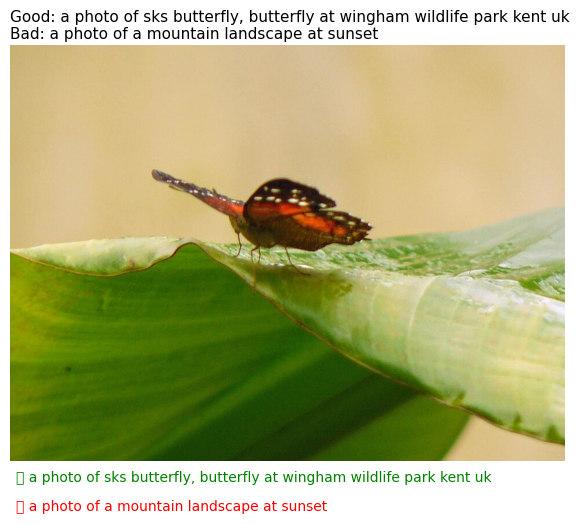

Изображение: /content/drive/MyDrive/lab13/data/commons_09.jpg
Хороший промпт: a photo of sks butterfly, butterfly at wingham wildlife park kent uk
Плохой промпт:  a photo of a mountain landscape at sunset


In [38]:
import matplotlib.pyplot as plt
from PIL import Image

# Берём, например, 10-е изображение из train (индекс 9)
idx = 9
item = train_items[idx]

# Открываем картинку
img = Image.open(item['file_path']).convert('RGB')

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)
ax.axis('off')

# Формируем заголовок: хороший caption зелёным, плохой — красным
good = item['good_caption']
bad = item['bad_caption']

# Используем HTML-разметку для цвета (работает в Jupyter/Colab)
title_text = f"Good: {good}\nBad: {bad}"
ax.set_title(title_text, fontsize=11, loc='left', wrap=True)

# Добавляем цветные подписи прямо на графике (чтобы точно было видно)
ax.text(0.01, -0.05, f"✅ {good}", transform=ax.transAxes, color='green', fontsize=10)
ax.text(0.01, -0.12, f"❌ {bad}", transform=ax.transAxes, color='red', fontsize=10)

plt.tight_layout()
plt.show()

# Также выведем в консоль для удобства копирования
print(f"Изображение: {item['file_path']}")
print(f"Хороший промпт: {good}")
print(f"Плохой промпт:  {bad}")

## Анализ результатов

В ходе лабораторной работы я сравнил три конфигурации LoRA: с рангом 4 и скоростью обучения \(10^{-4}\), с рангом 8 и скоростью обучения \(10^{-4}\), а также с рангом 8 и скоростью обучения \(5 \cdot 10^{-5}\). Для всех вариантов использовались одинаковые 28 обучающих изображений, 400 шагов обучения и одинаковые запросы и начальные значения генератора. Для оценки было создано по 60 изображений на каждый вариант.

### Сравнение результатов

| Конфигурация | Средняя ошибка обучения | Время обучения | Сходство с текстом | Разнообразие | Близость к train |
|---|---:|---:|---:|---:|---:|
| Baseline | — | — | 0,3251 | 0,1011 | 0,8608 |
| r4, lr=1e-4 | 0,155519 | 2,8 мин | 0,3251 | 0,1011 | 0,8608 |
| r8, lr=1e-4 | 0,155514 | 2,8 мин | 0,3251 | 0,1011 | 0,8608 |
| r8, lr=5e-5 | 0,155653 | 2,8 мин | 0,3251 | 0,1011 | 0,8608 |

По таблице видно, что различия между конфигурациями практически отсутствуют. Несмотря на разный ранг и скорость обучения, все три варианта получили одинаковые итоговые метрики. Более того, показатели совпали с исходной моделью без LoRA. Это означает, что заметного улучшения качества генерации после обучения обнаружено не было.

### Ограничения и выводы

У эксперимента есть несколько ограничений. Во-первых, обучающая выборка небольшая — всего 28 изображений. Во-вторых, обучение проводилось только 400 шагов. Кроме того, при загрузке LoRA появлялось предупреждение об отсутствии ключей адаптера для U-Net. Поэтому нельзя исключить, что адаптеры обучились, но не применились при генерации.

В дополнительном эксперименте с намеренно неправильными подписями метрики также не изменились: все три показателя совпали с основным вариантом. Поэтому гипотеза о том, что неправильные подписи заставят модель меньше ориентироваться на текст, не подтвердилась.

Таким образом, в ходе работы удалось подготовить и проверить набор данных, обучить три конфигурации LoRA и провести сравнение генераций. Однако улучшения относительно исходной модели получить не удалось. Совпадение изображений и метрик указывает на возможную техническую проблему при применении адаптеров. Поэтому по результатам этой работы нельзя сделать вывод, что изменение ранга или скорости обучения не влияет на качество LoRA в целом. Для такого вывода потребовалось бы повторить эксперимент после проверки загрузки адаптеров.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.